In [ ]:
# Open source data analysis and manipulation tool.
import pandas as pd

# Python data visualization library.
import seaborn as sns
import matplotlib.pyplot as plt
#It provides numerical routines for numerical integration, interpolation, optimization, linear algebra, and statistics.
import scipy.stats as ss
%matplotlib inline

##### https://docs.scipy.org/doc/scipy/reference/stats.html
##### https://seaborn.pydata.org/

### ¿Qué buscamos? ¿Cuál es nuestra hipótesis?

### H0 : Dentro de cada localidad, la distribución de casos entre los virus es homogénea; es decir, no existe evidencia de que un virus presente una frecuencia sistemáticamente diferente de los demás.

### H1 : Existe al menos una localidad en la que la distribución de casos entre los virus no es homogénea.

Los datos que buscamos, los atributos que medimos o recolectamos y las comparaciones que hagamos dependen en primera instancia de aquello que perseguimos

In [ ]:
path = '/content/Tabla_estadistica.csv'
df = pd.read_csv(path, sep=';', header=0)
del df['Numero']

In [ ]:
df.head()

,Fecha,Sexo,Poblacion,AdenoV,RSV,INFA,INFB,PIV1,PIV2,PIV3,Edad(meses)
0,03/01/11,F,CABA,-,-,-,-,-,-,-,96.0
1,03/01/11,F,LA FERRERE,-,-,-,-,-,-,-,4.0
2,03/01/11,M,VILLA CELINA,-,-,-,-,-,-,-,8.0
3,03/01/11,M,VILLA CELINA,-,-,-,-,-,-,-,8.0
4,03/01/11,F,NaN,-,-,-,-,-,-,-,9.0


# 1 - Exploración de los Datos

In [ ]:
df.isna()

,Fecha,Sexo,Poblacion,AdenoV,RSV,INFA,INFB,PIV1,PIV2,PIV3,Edad(meses)
0,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False
4,False,False,True,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...
6725,False,False,False,False,False,False,False,False,False,False,False
6726,False,False,False,False,False,False,False,False,False,False,False
6727,False,False,True,False,False,False,False,False,False,False,False
6728,False,False,True,True,True,True,True,True,True,True,False


In [ ]:
df['AdenoV'].describe()

,AdenoV
count,6708
unique,6
top,-
freq,6403


In [ ]:
# Categorias de AdenoV

categorias_medicion = df['AdenoV'].astype("category")
categorias_medicion_frecuencias = categorias_medicion.value_counts()
categorias_medicion_frecuencias

,count
AdenoV,
-,6403
EM,180
*,63
+,34
NM,27
MUESTRA MAL REMITIDA,1


In [ ]:
# Categorias de PIV1

categorias_medicion_PIV1 = df['PIV1'].astype("category")
categorias_medicion_PIV1_frecuencias = categorias_medicion_PIV1.value_counts()
categorias_medicion_PIV1_frecuencias

,count
PIV1,
-,6394
EM,180
*,93
NM,27
+,12
**,2


In [ ]:
# Categorias de PIV2

categorias_medicion_PIV2 = df['PIV2'].astype("category")
categorias_medicion_PIV2_frecuencias = categorias_medicion_PIV2.value_counts()
categorias_medicion_PIV2_frecuencias

,count
PIV2,
-,6403
EM,180
*,95
NM,27
+,3


In [ ]:
# Categorias de PIV3

categorias_medicion_PIV3 = df['PIV3'].astype("category")
categorias_medicion_PIV3_frecuencias = categorias_medicion_PIV3.value_counts()
categorias_medicion_PIV3_frecuencias

,count
PIV3,
-,6324
EM,180
*,94
+,82
NM,27
**,1


In [ ]:
# Categorias de INFA

categorias_medicion_IFNA = df['INFA'].astype("category")
categorias_medicion_IFNA_frecuencias = categorias_medicion_IFNA.value_counts()
categorias_medicion_IFNA_frecuencias

,count
INFA,
-,6361
EM,180
+,76
*,64
NM,27


In [ ]:
# Categorias de INFB

categorias_medicion_IFNB = df['INFB'].astype("category")
categorias_medicion_IFNB_frecuencias = categorias_medicion_IFNB.value_counts()
categorias_medicion_IFNB_frecuencias

,count
INFB,
-,6437
EM,180
*,63
NM,27
*.,1


In [ ]:
# Categorias de RSV

categorias_medicion_RSV = df['RSV'].astype("category")
categorias_medicion_RSV_frecuencias = categorias_medicion_RSV.value_counts()
categorias_medicion_RSV_frecuencias

,count
RSV,
-,4615
+,1822
EM,180
*,63
NM,27
**,1


In [ ]:
# Categorias de Sexo

categorias_sexo = df['Sexo'].astype("category")
categorias_sexo = categorias_sexo.value_counts()
categorias_sexo

,count
Sexo,
M,3727
F,2918
.,3


In [ ]:
df['Edad(meses)'].describe()

,Edad(meses)
count,6730.000000
mean,17.806300
std,92.370807
min,0.000000
25%,2.000000
50%,6.000000
75%,13.000000
max,6120.000000


In [ ]:
df['Sexo'].describe()

,Sexo
count,6648
unique,3
top,M
freq,3727


In [ ]:
df['Poblacion'].describe()

,Poblacion
count,4650
unique,466
top,CABA
freq,996


In [ ]:
# Categorias de Poblacion

categorias_medicion_poblacion = df['Poblacion'].astype("category")
categorias_medicion_poblacion = categorias_medicion_poblacion.value_counts()

# Mostrar lista de categorias
categorias_medicion_poblacion.index.tolist()


['CABA',
 'SAN MIGUEL',
 'MORENO',
 'PILAR',
 'MERLO',
 'J C PAZ',
 'L DE ZAMORA',
 'CIUDADELA',
 'LOMAS DE ZAMORA',
 'SAN MARTIN',
 'DEL VISO',
 'ESCOBAR',
 'LANUS',
 'LAFERRERE',
 'J.C.PAZ',
 'GRANDBOURG',
 'TIGRE',
 'LA MATANZA',
 'TORTUGUITAS',
 'CASEROS',
 'VILLA 31',
 'VTE LOPEZ',
 'DERQUI',
 'GARIN',
 'AVELLANEDA',
 'GRAND BOURG',
 'RETIRO',
 'J L SUAREZ',
 'QUILMES',
 'DON TORCUATO',
 'G CATAN',
 'P NOGUES',
 'BELLA VISTA',
 'M ARGENTINAS',
 'J.L.SUAREZ',
 'ZARATE',
 'BERAZATEGUI',
 'POLVORINES',
 'OLIVOS',
 'MONTE GRANDE',
 'R CASTILLO',
 'ITUZAINGO',
 'LA FERRERE',
 'LOS POLVORINES',
 'LUGANO',
 'SAN JUSTO',
 'BANFIELD',
 'JOSE C. PAZ',
 'V BALLESTER',
 'MORON',
 'VIRREY DEL PINO',
 'SAN FERNANDO',
 'JOSE C PAZ',
 'EZEIZA',
 'VICENTE LOPEZ',
 'MERCEDES',
 'RAMOS MEJIA',
 'VILLA DE MAYO',
 'ENTRE RIOS',
 'HURLINGHAN',
 '3 DE FEBRERO',
 'L DEL MIRADOR',
 'MONTEGRANDE',
 'GRAL RODRIGUEZ',
 'FLORIDA',
 'SAN PEDRO',
 'VILLA CELINA',
 'MALVINAS ARGENTINAS',
 'PALOMAR',
 'ADROGUE',


# 2 - Limpieza y corrección de nombres de ciudades

In [ ]:
!pip install rapidfuzz

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 50.5 MB/s eta 0:00:00


In [ ]:
import re
import unicodedata
import pandas as pd
from rapidfuzz import process, fuzz

# -------------------------------------------------------------------
# 1) NORMALIZACIÓN BÁSICA DE TEXTO
# -------------------------------------------------------------------

def quitar_acentos(texto: str) -> str:
    """Saca tildes/diéresis pero conserva la Ñ."""
    texto = texto.replace('Ñ', '§').replace('ñ', '§')
    texto = unicodedata.normalize('NFKD', texto)
    texto = ''.join(c for c in texto if not unicodedata.combining(c))
    return texto.replace('§', 'Ñ')

def normalizar(texto: str) -> str:
    if pd.isna(texto):
        return texto
    t = str(texto).strip().upper()

    # arreglar caracteres mal codificados típicos (mojibake) que vi en tu lista
    t = t.replace('\\A5', 'Ñ').replace('\\A6', 'Ñ').replace('\\80', '')

    t = quitar_acentos(t)
    t = t.replace('.', ' ')          # "J.C.PAZ" -> "J C PAZ"
    t = re.sub(r'[^A-Z0-9Ñ\s]', ' ', t)   # saca símbolos raros, guiones, barras
    t = re.sub(r'\s+', ' ', t).strip()   # espacios múltiples
    return t

# -------------------------------------------------------------------
# 2) DICCIONARIO DE ALIAS -> NOMBRE CANÓNICO
#    (cubre las variantes más frecuentes que aparecen en tu lista)
#    Las claves ya están normalizadas (sin tildes, sin puntos, en mayúsculas)
# -------------------------------------------------------------------

ALIAS = {
    # José C. Paz
    'J C PAZ': 'Jose C. Paz', 'JC PAZ': 'Jose C. Paz', 'J CPAZ': 'Jose C. Paz',
    'J C`PAZ': 'Jose C. Paz', 'J C PAZ': 'Jose C. Paz', 'JOSE C PAZ': 'Jose C. Paz',
    'JOSE C PAZ': 'Jose C. Paz', 'JOSE CPAZ': 'Jose C. Paz', 'JOSE C PAZ': 'Jose C. Paz',

    # Lomas de Zamora
    'L DE ZAMORA': 'Lomas de Zamora', 'L ZAMORA': 'Lomas de Zamora',
    'LOMAS DE ZAMORAS': 'Lomas de Zamora', 'LOMAS DE ZMORA': 'Lomas de Zamora',
    'LOMAZ DE ZAMORA': 'Lomas de Zamora', 'LOMASA DE ZAMORA': 'Lomas de Zamora',
    'LOMAS DE SAMORA': 'Lomas de Zamora', 'L DE ZMAORA': 'Lomas de Zamora',
    'L DE ZAMOR': 'Lomas de Zamora', 'L DE ZMORA': 'Lomas de Zamora',
    'LOMAS': 'Lomas de Zamora', 'V FIORITO': 'Lomas de Zamora', 'LAVALLOL': 'Lomas de Zamora',


    # Gral. San Martín
    'S MARTIN' : 'San Martin', 'SAN MERTIN': 'San Martin', 'SAN MIGEUL': 'San Miguel',
    'V ZAGALA': 'San Martin', 'V ZAGALIA': 'San Martin', 'BILLINGURST': 'San Martin',

    # San Miguel
    'S MIGUEL': 'San Miguel', 'SN MIGUEL': 'San Miguel',

    # Hurlingham
    'HURLINGHAN': 'Hurlingham', 'HURLINGAHN': 'Hurlingham', 'HURLINGAM': 'Hurlingham',
    'URLINGAN': 'Hurlingham',

    # Grand Bourg
    'GRANDBOURG': 'Grand Bourg', 'GRAND BOURG': 'Grand Bourg', 'GRANBOURG': 'Grand Bourg',
    'G BOURG': 'Grand Bourg', 'GRAN BOURG': 'Grand Bourg', 'GRAN BOURD': 'Grand Bourg',
    'GRAN BOUR': 'Grand Bourg', 'GRAND BOUR': 'Grand Bourg', 'GRAND BURG': 'Grand Bourg',
    'GRAND BURGE': 'Grand Bourg', 'GRANDOURG': 'Grand Bourg', 'G BOURG': 'Grand Bourg',

    # Isidro Casanova / La Ferrere / La Matanza
    'I CASANOVA': 'Isidro Casanova', 'LAFERRERE': 'La Ferrere', 'LA FERRERE': 'La Ferrere',
    'LAFERRE': 'La Ferrere', 'LA FERRERERE': 'La Ferrere', 'LAFERRRERE': 'La Ferrere',
    'LA FERERE': 'La Ferrere',

    # Jose Leon Suarez
    'J L SUAREZ': 'Jose Leon Suarez', 'J LEON SUAREZ': 'Jose Leon Suarez',
    'JL SUAREZ': 'Jose Leon Suarez', 'JOSE L SUAREZ': 'Jose Leon Suarez',
    'JOSE L SUAREZ': 'Jose Leon Suarez', 'JOSE LEON SUARZ': 'Jose Leon Suarez',
    'JOSE LEON SUAREZ': 'Jose Leon Suarez', 'J LEO SUAREZ': 'Jose Leon Suarez',

    # Gonzalez Catan
    'G CATAN': 'Gonzalez Catan', 'GONZALES CATAN': 'Gonzalez Catan',
    'GONZALEZ CATAN': 'Gonzalez Catan',

    # Malvinas Argentinas
    'M ARGENTINAS': 'Malvinas Argentinas', 'MALVINAS ARGENTINA': 'Malvinas Argentinas',
    'MALV ARG': 'Malvinas Argentinas', 'MALV ARGENTINAS': 'Malvinas Argentinas',
    'MALVINAS ARG': 'Malvinas Argentinas', 'M ARGENTINS': 'Malvinas Argentinas',
    'M ARGENTINA': 'Malvinas Argentinas', 'MALVINAS': 'Malvinas Argentinas',

    # Vicente Lopez
    'VTE LOPEZ': 'Vicente Lopez', 'VTE LOPEZ': 'Vicente Lopez', 'V LOPEZ': 'Vicente Lopez',

    # Villa Ballester / Bosch / Martelli / Tesei / Adelina / etc
    'V BALLESTER': 'Villa Ballester', 'V.BALLESTER': 'Villa Ballester',
    'V BOSCH': 'Villa Bosch', 'V MARTELLI': 'Villa Martelli',
    'VILLA MARTELL': 'Villa Martelli', 'V TESEI': 'Villa Tesei',
    'V ADELINA': 'Villa Adelina', 'V ZABALA': 'Villa Zabala',
    'V DEL PINO': 'Virrey del Pino', 'REY DEL PINO': 'Virrey del Pino','VA6 MARTELLI': 'Villa Martelli', 'VÑ MARTELLI': 'Villa Martelli',

    # Ituzaingo
    'ITUIZANGO': 'Ituzaingo',

    # Ciudadela
    'CUIDADELA': 'Ciudadela',

    # Don Torcuato
    'D TORCUATO': 'Don Torcuato', 'DONTORCUATO': 'Don Torcuato', 'DON TORCUARTO': 'Don Torcuato',

    # Esteban Echeverria
    'E ECHEVERRIA': 'Esteban Echeverria', 'ECHEBERRIA': 'Esteban Echeverria',
    'EST ECHEVERRIA': 'Esteban Echeverria',

    # Florencio Varela
    'F VARELA': 'Florencio Varela', 'FCIO VARELA': 'Florencio Varela',

    # Monte Grande
    'M GRANDE': 'Monte Grande', 'MONTEGRANDE': 'Monte Grande', 'M GRANDE': 'Monte Grande',

    # General Rodriguez
    'GRAL RODRIGUEZ': 'General Rodriguez', 'GRAL RODRIGUEZ': 'General Rodriguez',
    'GRL RODRIGUEZ': 'General Rodriguez',

    # General Pacheco
    'GRAL PACHECO': 'General Pacheco', 'GRL PACHECO': 'General Pacheco', 'PACHECO': 'General Pacheco',

    # San Antonio de Padua
    'S A DE PADUA': 'San Antonio de Padua', 'S A PADUA': 'San Antonio de Padua',
    'SAN A PADUA': 'San Antonio de Padua', 'SAN ANTONIO PADUA': 'San Antonio de Padua',
    'PADUA': 'San Antonio de Padua',

    # Ing. Maschwitz
    'I MASHWITZ': 'Ingeniero Maschwitz', 'I MASHCHWITZ': 'Ingeniero Maschwitz',
    'ING MASCHWITZ': 'Ingeniero Maschwitz', 'MASCHWITZ': 'Ingeniero Maschwitz',
    'ING MASCWUICH': 'Ingeniero Maschwitz',

    # Pablo Nogues
    'P NOGUES': 'Pablo Nogues', 'P NOGUES': 'Pablo Nogues', 'PABLO NOGES': 'Pablo Nogues',
    'PABLO NOGEZ': 'Pablo Nogues', 'PABLO NOGUEZ': 'Pablo Nogues',

    # Villa 1-11-14 -> Se movio a CABA

    # 3 de Febrero
    '3 DE FEBRERO': 'Tres de Febrero', 'TRES DE FEBRERO': 'Tres de Febrero', 'P PODESTA': 'Tres de Febrero',
    'M CORONADO': 'Tres de Febrero', 'PABLO PODESTA': 'Tres de Febrero',

    # Quilmes (typo)
    'QULMES': 'Quilmes',

    # Munro
    'MUNRRO': 'Munro',

    # Rafael Castillo
    'R CASTILLO': 'Rafael Castillo',

    # Ramos Mejia
    'R MEJIA': 'Ramos Mejia',

    # Rafael Calzada
    'R CALZADA': 'Rafael Calzada',

    # Los Polvorines
    'POLVORINES': 'Los Polvorines',

    # Longchamps
    'LONG CHAMPS': 'Longchamps',

    # Banfield typo
    'BANFILED': 'Banfield',

    # Berazategui typo
    'BERASATEGUI': 'Berazategui',

    # Almirante Brown
    'ALMIRANTE BROW': 'Almirante Brown', 'ATTE BROW': 'Almirante Brown',

    # Ing. Budge
    'ING BUDGE': 'Ingeniero Budge', 'INGENIERO BUDGE': 'Ingeniero Budge', 'I BUDGE': 'Ingeniero Budge',

    # Aldo Bonzi
    'A BONZI': 'Aldo Bonzi',

    # Alejandro Korn
    'A KORN': 'Alejandro Korn',

    # Chivilcoy / Chipoletti (Cipolletti, Río Negro)
    'CIPOLETTI': 'Cipolletti', 'CHIPOLETTI': 'Cipolletti',

    # Tigre / El Talar / Tortuguitas
    'TALAR': 'El Talar', 'EL TALAR': 'El Talar', 'TORTUGUITA': 'Tortuguitas',
    'TALAR DE PACHECO': 'Talar de Pacheco',

    # CABA / genérico
    'CABA': 'CABA', 'CAB': 'CABA', 'CASA': 'CABA', 'CAQBA': 'CABA',
    'RETIRO CABA': 'CABA', 'CABA VILLA 31': 'CABA',
    'VILLA 31 CABA': 'CABA', 'VILLA 31 RETIRO': 'CABA',
    'BO GUEMES VILLA 31': 'CABA', 'BO YPF VILLA 31': 'CABA',
    'FUNDACION JUANITO' : 'CABA', 'V SOLDATI' : 'CABA',
    'LINCOLN 366': 'CABA', 'M 25 C 60': 'CABA', 'HNRG': 'CABA', 'V LURO': 'CABA',
    'POMPEYA': 'CABA', 'MORRIS 1355': 'CABA', 'ACC3': 'CABA',
    'VILLA 1 11 14': 'CABA', 'VILLA 1 11 14': 'CABA', 'Villa 31': 'CABA',


    # Rosario
    'ROSARIO': 'Rosario',

    # Villa Alsina
    'V ALSINA': 'Villa Alsina', 'V ALORNA': 'Villa Alorna',

    # Capitan Sarmiento
    'CTAN SARMIENTO':'Capitan Sarmiento',

    # Savio
    'M SAVIO': 'Savio',

    # Cordoba
    'V CONCEPCION': 'Cordoba',

   # Merlo
    'LIBERTAD': 'Merlo',

    # Nuevas adiciones
    'NUÑEZ': 'Nuñez',
    'MUNIZ': 'Muñiz',

    # Tucuman
    'S.M. TUCUMAN': 'Tucuman',

    # La Pampa
    'INTENDENTE ALVEAR':'La Pampa', 'PAMPA': 'La Pampa',

    # Otros aliases
    'SANTOS LUGARES': 'Santos Lugares',
    'STA ROSA': 'Santa Rosa',
    'MARIANO ACOSTA': 'Mariano Acosta',
    'RIO COLORADO': 'Rio Colorado',
    'LEDESMA': 'Ledesma',
    'BARRIO ALBERDI': 'Barrio Alberdi',
    'STA FE': 'Santa Fe',
    'GRAL ACHA': 'General Acha',
    'BO BICENTENARIO': 'Barrio Bicentenario',
    'GENERAL PINEDO': 'General Pinedo',
    'LAS TUNAS': 'Las Tunas',
    'SAENZ PENIA': 'Sáenz Peña',
    'GRAL BEGRANO': 'General Belgrano',
    'GUAYMAYEN': 'Guaymallén',
    'ESPEGAZINI': 'Spegazzini',
    'BARRIO GUEMES': 'Barrio Guemes',
    'UGARTE': 'Ugarte',
    'FIORITO LOMAS': 'Villa Fiorito',
    'GUILLON': 'Luis Guillon',
    'V INSUPERABLE': 'Villa Insuperable',
    'WILLIAMS MORRIS': 'William C. Morris',
    'P PDESTA': 'Pablo Podesta', # Ya mapea a Tres de Febrero
    'OLMOS': 'Lisandro Olmos',
    'V CRESPO': 'Villa Crespo',
    'ALVAREZ': 'Alvarez',
}

# Normalizar todas las claves del diccionario ALIAS para asegurar consistencia
# con la función normalizar(). Esto es importante porque la función normalizar()
# se aplica a la entrada bruta antes de buscar en ALIAS.
ALIAS_NORMALIZED = {}
for key, value in ALIAS.items():
    ALIAS_NORMALIZED[normalizar(key)] = value
ALIAS = ALIAS_NORMALIZED

# -------------------------------------------------------------------
# 3) LISTA "CANÓNICA" PARA FUZZY MATCHING (fallback)
#    Localidades válidas de referencia, sacadas de tu propia lista
#    (las más completas / bien escritas). Agregá las que falten.
# -------------------------------------------------------------------

CANONICAS = sorted(set(list(ALIAS.values()) + [
    'CABA', 'San Miguel', 'Moreno', 'Pilar', 'Merlo', 'Jose C. Paz',
    'Lomas de Zamora', 'Ciudadela', 'San Martin', 'Del Viso', 'Escobar',
    'Lanus', 'Tigre', 'La Matanza', 'Tortuguitas', 'Caseros', 'Villa 31',
    'Vicente Lopez', 'Derqui', 'Garin', 'Avellaneda', 'Grand Bourg',
    'Retiro', 'Jose Leon Suarez', 'Quilmes', 'Don Torcuato', 'Gonzalez Catan',
    'Pablo Nogues', 'Bella Vista', 'Malvinas Argentinas', 'Zarate',
    'Berazategui', 'Los Polvorines', 'Olivos', 'Monte Grande',
    'Rafael Castillo', 'Ituzaingo', 'La Ferrere', 'Lugano', 'San Justo',
    'Banfield', 'Villa Ballester', 'Moron', 'Virrey del Pino', 'San Fernando',
    'Ezeiza', 'Mercedes', 'Ramos Mejia', 'Villa de Mayo', 'Entre Rios',
    'Hurlingham', 'Tres de Febrero', 'Lomas del Mirador', 'General Rodriguez',
    'Florida', 'San Pedro', 'Villa Celina', 'Palomar', 'Adrogue', 'Lujan',
    'La Tablada', 'General Pacheco', 'Munro', 'Isidro Casanova', 'Salta',
    'Concordia', 'Glew', 'Ciudad Evita', 'Esteban Echeverria', 'Bernal',
    'Villa Madero', 'Alberti', 'Marcos Paz', 'San Antonio de Padua',
    'San Luis', 'Villa Martelli', 'Rafael Calzada', 'Paso del Rey',
    'Loma Hermosa', 'Flores', 'Solano', 'Floresta', 'El Talar', 'La Boca',
    'Mendoza', 'Lanus Este', 'Longchamps', 'Lanus Oeste', 'Haedo',
    'Carapachay', 'Castelar', 'Claypole', 'Corrientes', 'Villa Adelina',
    'Villa Fiorito', 'Villa Lugano', 'Villa Maipu', 'Ingeniero Budge',
    'Linters', 'Aldo Bonzi', 'Alejandro Korn', 'Almirante Brown',
    'Ingeniero Maschwitz', 'Rauch', 'Wilde', 'Villa Tesei', 'Villa Rosa',
    'La Plata', 'Barracas', 'Villa Bosch', 'Villa Zabala', 'Villa 1-11-14',
    'Santiago del Estero', 'San Telmo', 'Temperley', 'Tablada',
    'Florencio Varela', 'Ushuaia', 'Colon', 'El Dorado', 'El Jaguel',
    'Campana', 'Cipolletti', 'Beccar', 'Bellavista', 'Burzaco', 'Boulogne',
    'Azul', 'Jose Ingenieros', 'Hudson', 'Talar de Pacheco', 'Rosario',
    'Villa Alsina', 'Capitan Sarmiento', 'Jujuy', 'La Lomita', 'Valentin Garcia',
    'Gualeguay', 'Pontevedra', 'Benavidez', 'Savio', 'Gesell', 'Lobos', 'Guernica',
    'Misiones', 'Cordoba', 'La Pampa','Nuñez', 'Rio Negro', 'Tornquist',

    # Nuevas adiciones a CANONICAS para resolver entradas de 'revisar'
    'Villa Alorna', 'Santos Lugares', 'Santa Rosa', 'Catamarca', 'Mariano Acosta', 'Rio Colorado', 'Ledesma',
    'Barrio Alberdi', 'General Acha', 'Barrio Bicentenario', 'Tandil', 'General Pinedo', 'Bicentenario',
    'Las Tunas', 'Sáenz Peña', 'General Belgrano', 'Guaymallén', 'Parana', 'Spegazzini', 'Obera', 'Barrio Guemes',
    'Saavedra', 'Ugarte', 'Rio Cuarto', 'Villa Lynch', 'Bragado', 'Las Grutas', 'Luis Guillon', 'Belgrano',
    'Villa Insuperable', 'William C. Morris', 'Independencia', 'Mataderos', 'Berisso', 'Necochea',
    'Santo Domingo', 'Lisandro Olmos', 'Maximo Paz', 'Villa Crespo', 'Formosa', 'Alvarez',
    'A Farrace', 'Hernandez', 'Delai', 'Falcon', 'Estocolmo'
]))

# -------------------------------------------------------------------
# 4) PIPELINE DE LIMPIEZA
# -------------------------------------------------------------------

def limpiar_ciudad(valor, umbral_confianza=85):
    """
    Devuelve (nombre_limpio, metodo, score)
    metodo: 'alias' | 'fuzzy' | 'sin_match'
    """
    norm = normalizar(valor)
    # Check if norm is NaN (from original input being NaN) or an empty string
    if pd.isna(norm) or not norm:
        return (None, 'vacio', 0)

    # 1) match exacto por diccionario de alias
    if norm in ALIAS:
        return (ALIAS[norm], 'alias', 100)

    # 2) si ya es un nombre canónico normalizado, listo
    canon_norm = {normalizar(c): c for c in CANONICAS}
    if norm in canon_norm:
        return (canon_norm[norm], 'exacto', 100)

    # 3) fuzzy matching contra la lista canónica
    match, score, _ = process.extractOne(norm, list(canon_norm.keys()), scorer=fuzz.WRatio)
    if score >= umbral_confianza:
        return (canon_norm[match], 'fuzzy', score)

    return (str(valor).strip().title(), 'sin_match', score)


# -------------------------------------------------------------------
# 5) APLICAR SOBRE UNA COPIA DEL DATAFRAME
# -------------------------------------------------------------------
df_ciudades_corregidas = df.copy()

resultados = df_ciudades_corregidas['Poblacion'].apply(limpiar_ciudad)
df_ciudades_corregidas['Poblacion_limpia'] = resultados.apply(lambda x: x[0])
df_ciudades_corregidas['metodo_match']     = resultados.apply(lambda x: x[1])
df_ciudades_corregidas['score_match']      = resultados.apply(lambda x: x[2])

# Eliminar filas con Poblacion_limpia '48565921'
df_ciudades_corregidas = df_ciudades_corregidas[
    df_ciudades_corregidas['Poblacion_limpia'] != '48565921'
]

# Para revisar a mano los casos dudosos
revisar = (
    df_ciudades_corregidas[
        df_ciudades_corregidas['metodo_match'] == 'sin_match'
    ][['Poblacion', 'Poblacion_limpia', 'score_match']]
    .drop_duplicates()
)

revisar.sort_values('score_match')


if __name__ == '__main__':
    # demo rápida con algunos valores de tu lista
    ejemplos = ['J C PAZ', 'LOMAZ DE ZAMORA', 'HURLINGHAN', 'GRANDBOURG',
                'QULMES', 'V BALLESTER', 'NU\\A5EZ', 'MunIZ', ' M 25 C 60', 'V ZAGALIA\\80',
                'Fundacion Juanito', 'S.M. TUCUMAN', 'Billingurst', 'Lavallol', 'V Alorna', 'Santos Lugares',
                'Sta Rosa', 'Catamarca', 'Mariano Acosta', 'Rio Colorado', 'Barrio Alberdi', 'Gral Acha',
                'Bo Bicentenario', 'Tandil', 'General Pinedo', 'Saenz Penia', 'Gral Begrano', 'Guaymayen',
                'Parana', 'Espegazini', 'Obera', 'Saavedra', 'Ugarte', 'Rio Cuarto', 'Fiorito Lomas',
                'Villa Lynch', 'Bragado', 'Las Grutas', 'Guillon', 'Belgrano', 'V. Insuperable',
                'Williams Morris', 'Mataderos', 'Berisso', 'Necochea', 'Santo Domingo', 'P Pdesta',
                'Olmos', 'Maximo Paz', 'V Crespo', 'Formosa', 'Alvarez', 'V\\A6 Martelli',
                'Morris 1355', 'Acc3', 'A Farrace', 'Hernandez', 'Delai', 'Falcon', 'Estocolmo']
    for e in ejemplos:
        print(f'{e!r:25} -> {limpiar_ciudad(e)}')

'J C PAZ'                 -> ('Jose C. Paz', 'alias', 100)
'LOMAZ DE ZAMORA'         -> ('Lomas de Zamora', 'alias', 100)
'HURLINGHAN'              -> ('Hurlingham', 'alias', 100)
'GRANDBOURG'              -> ('Grand Bourg', 'alias', 100)
'QULMES'                  -> ('Quilmes', 'alias', 100)
'V BALLESTER'             -> ('Villa Ballester', 'alias', 100)
'NU\\A5EZ'                -> ('Nuñez', 'alias', 100)
'MunIZ'                   -> ('Muñiz', 'alias', 100)
' M 25 C 60'              -> ('CABA', 'alias', 100)
'V ZAGALIA\\80'           -> ('San Martin', 'alias', 100)
'Fundacion Juanito'       -> ('CABA', 'alias', 100)
'S.M. TUCUMAN'            -> ('Tucuman', 'alias', 100)
'Billingurst'             -> ('San Martin', 'alias', 100)
'Lavallol'                -> ('Lomas de Zamora', 'alias', 100)
'V Alorna'                -> ('Villa Alorna', 'alias', 100)
'Santos Lugares'          -> ('Santos Lugares', 'alias', 100)
'Sta Rosa'                -> ('Santa Rosa', 'alias', 100)
'Catamarca'        

In [ ]:
# Remover el score_match
df_ciudades_corregidas = df_ciudades_corregidas.drop(columns=['score_match'])

In [ ]:
# Remover el metodo_match
df_ciudades_corregidas = df_ciudades_corregidas.drop(columns=['metodo_match'])

In [ ]:
# Remover poblacion
df_ciudades_corregidas = df_ciudades_corregidas.drop(columns=['Poblacion'])

In [ ]:
df_ciudades_corregidas.head()

,Fecha,Sexo,AdenoV,RSV,INFA,INFB,PIV1,PIV2,PIV3,Edad(meses),Poblacion_limpia
0,03/01/11,F,-,-,-,-,-,-,-,96.0,CABA
1,03/01/11,F,-,-,-,-,-,-,-,4.0,La Ferrere
2,03/01/11,M,-,-,-,-,-,-,-,8.0,Villa Celina
3,03/01/11,M,-,-,-,-,-,-,-,8.0,Villa Celina
4,03/01/11,F,-,-,-,-,-,-,-,9.0,None


In [ ]:
# Verificar las categorias de las ciudades nuevas
nuevas_categorias_ciudades = df_ciudades_corregidas['Poblacion_limpia'].astype("category")
nuevas_categorias_ciudades = nuevas_categorias_ciudades.value_counts()

nuevas_categorias_ciudades.index.tolist()

['CABA',
 'Jose C. Paz',
 'San Miguel',
 'Moreno',
 'Lomas de Zamora',
 'Pilar',
 'Merlo',
 'San Martin',
 'Ciudadela',
 'Grand Bourg',
 'Del Viso',
 'La Ferrere',
 'Jose Leon Suarez',
 'Escobar',
 'Vicente Lopez',
 'Lanus',
 'Malvinas Argentinas',
 'Tigre',
 'La Matanza',
 'Tortuguitas',
 'Pablo Nogues',
 'Caseros',
 'Los Polvorines',
 'Monte Grande',
 'Derqui',
 'Villa Ballester',
 'Garin',
 'Gonzalez Catan',
 'Avellaneda',
 'Don Torcuato',
 'Retiro',
 'Bella Vista',
 'Quilmes',
 'Tres de Febrero',
 'Villa Celina',
 'Rafael Castillo',
 'Berazategui',
 'Zarate',
 'Hurlingham',
 'Isidro Casanova',
 'Lomas del Mirador',
 'Olivos',
 'Ituzaingo',
 'Virrey del Pino',
 'Lugano',
 'Esteban Echeverria',
 'San Fernando',
 'Banfield',
 'Ramos Mejia',
 'San Justo',
 'San Antonio de Padua',
 'Moron',
 'Entre Rios',
 'General Rodriguez',
 'Ezeiza',
 'Florencio Varela',
 'Mercedes',
 'Villa de Mayo',
 'Loma Hermosa',
 'General Pacheco',
 'Ciudad Evita',
 'Florida',
 'Palomar',
 'Lujan',
 'Adrogue',

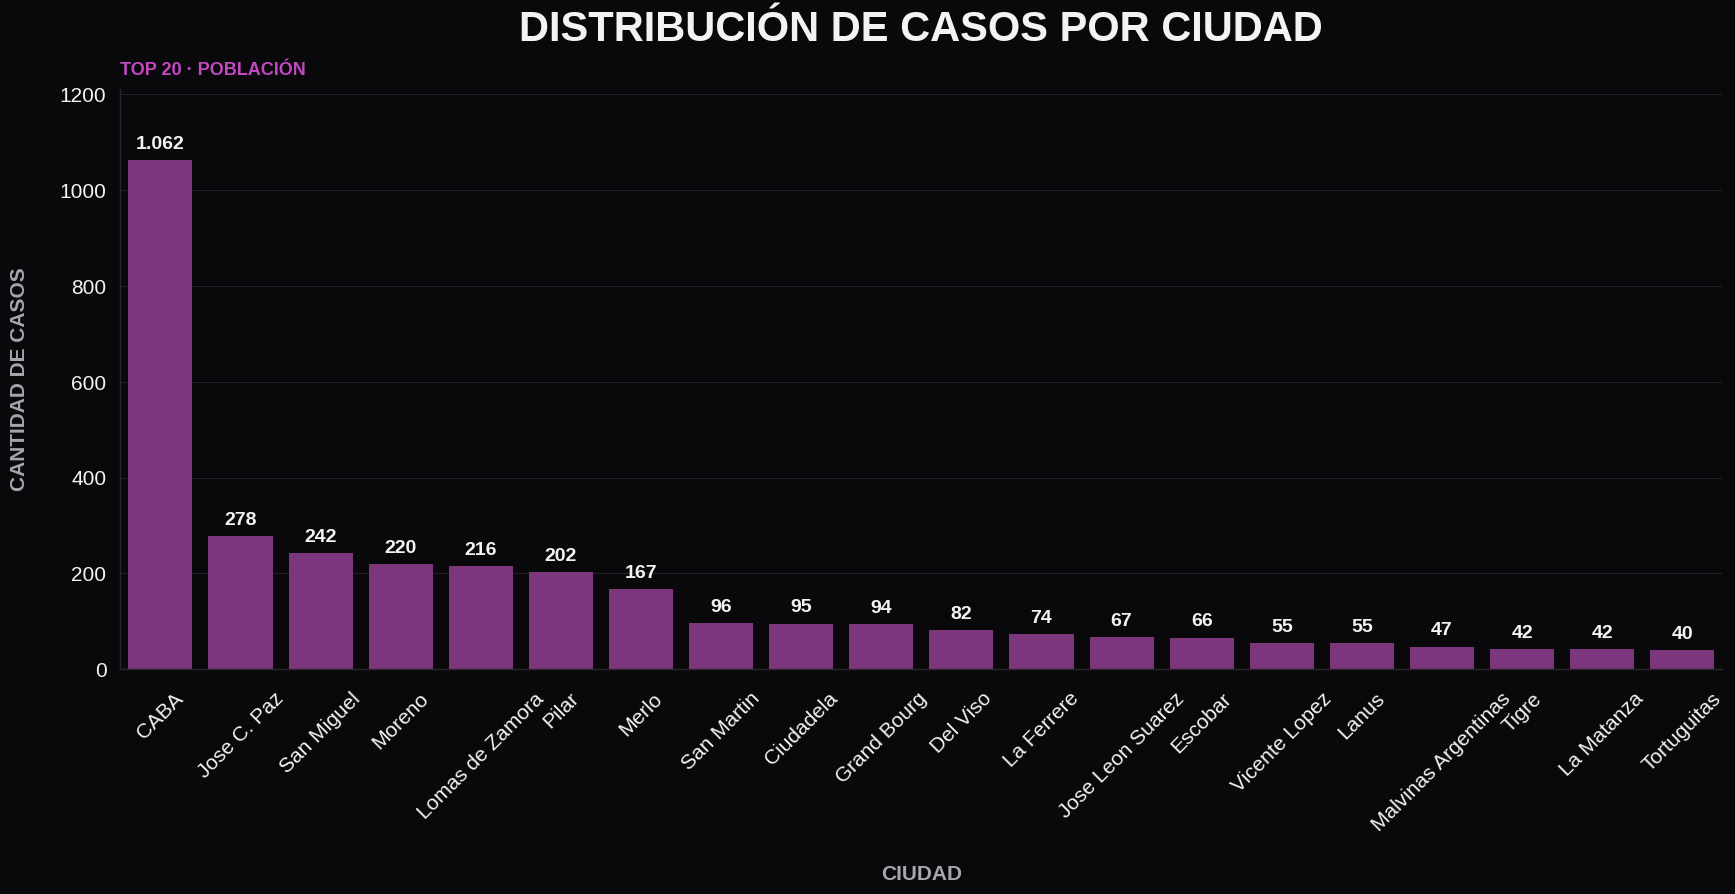

Imagen guardada en: distribucion_casos_ciudad.png


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# PREPARAR LOS DATOS
# ============================================================

city_counts = (
    df_ciudades_corregidas['Poblacion_limpia']
    .value_counts()
    .head(20)
)

# ============================================================
# PALETA DE COLORES
# ============================================================

BG_COLOR = '#09090B'          # Negro grafito
TEXT_COLOR = '#F5F2F6'        # Blanco suave
MUTED_COLOR = '#AAA4AD'       # Gris claro
GRID_COLOR = '#29252D'        # Gris oscuro
ORCHID_DARK = '#8F2D8F'       # Orchid oscuro
ORCHID_GLOW = '#C447C4'       # Orchid brillante

# ============================================================
# CREAR LA FIGURA
# ============================================================

fig, ax = plt.subplots(
    figsize=(18, 10),
    facecolor=BG_COLOR
)

ax.set_facecolor(BG_COLOR)

# ============================================================
# GRÁFICO DE BARRAS
# ============================================================

sns.barplot(
    x=city_counts.index,
    y=city_counts.values,
    ax=ax,
    color=ORCHID_DARK,
    edgecolor='none'
)

# Ajustar la apariencia de las barras
for bar in ax.patches:
    bar.set_alpha(0.95)

# ============================================================
# TÍTULO PRINCIPAL
# ============================================================

ax.set_title(
    'DISTRIBUCIÓN DE CASOS POR CIUDAD',
    fontsize=30,
    fontweight='bold',
    color=TEXT_COLOR,
    fontfamily='sans-serif',
    loc='center',
    pad=35
)

# ============================================================
# SUBTÍTULO
# ============================================================

ax.text(
    0,
    1.025,
    'TOP 20 · POBLACIÓN',
    transform=ax.transAxes,
    fontsize=13,
    fontweight='bold',
    color=ORCHID_GLOW,
    ha='left'
)

# ============================================================
# ETIQUETAS DE LOS EJES
# ============================================================

ax.set_xlabel(
    'CIUDAD',
    fontsize=15,
    fontweight='bold',
    color=MUTED_COLOR,
    labelpad=22
)

ax.set_ylabel(
    'CANTIDAD DE CASOS',
    fontsize=15,
    fontweight='bold',
    color=MUTED_COLOR,
    labelpad=22
)

# ============================================================
# ETIQUETAS DEL EJE X
# ============================================================

ax.tick_params(
    axis='x',
    labelsize=15,
    rotation=45,
    colors=TEXT_COLOR,
    length=0,
    pad=14
)

# ============================================================
# ETIQUETAS DEL EJE Y
# ============================================================

ax.tick_params(
    axis='y',
    labelsize=15,
    colors=TEXT_COLOR,
    length=0,
    pad=10
)

# ============================================================
# CUADRÍCULA
# ============================================================

ax.grid(
    axis='y',
    color=GRID_COLOR,
    linestyle='-',
    linewidth=0.8,
    alpha=0.8
)

ax.grid(axis='x', visible=False)

# Mantener la cuadrícula detrás de las barras
ax.set_axisbelow(True)

# ============================================================
# BORDES
# ============================================================

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.spines['left'].set_color(GRID_COLOR)
ax.spines['bottom'].set_color(GRID_COLOR)

ax.spines['left'].set_linewidth(1)
ax.spines['bottom'].set_linewidth(1)

# ============================================================
# VALORES SOBRE LAS BARRAS
# ============================================================

for bar in ax.patches:

    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + (city_counts.max() * 0.015),
        f'{int(height):,}'.replace(',', '.'),
        ha='center',
        va='bottom',
        fontsize=14,
        fontweight='bold',
        color=TEXT_COLOR
    )

# ============================================================
# ESPACIO SUPERIOR PARA LOS VALORES
# ============================================================

ax.set_ylim(
    0,
    city_counts.max() * 1.14
)

# ============================================================
# AJUSTE DE ESPACIADO
# ============================================================

plt.subplots_adjust(
    left=0.09,
    right=0.98,
    top=0.85,
    bottom=0.27
)

# ============================================================
# GUARDAR EN PNG DE ALTA RESOLUCIÓN
# ============================================================

ruta_png = 'distribucion_casos_ciudad.png'

fig.savefig(
    ruta_png,
    dpi=300,
    bbox_inches='tight',
    facecolor=fig.get_facecolor(),
    edgecolor='none'
)

# ============================================================
# MOSTRAR EL GRÁFICO
# ============================================================

plt.show()

print(f'Imagen guardada en: {ruta_png}')


In [ ]:
# Analizar cuales ciudades tienen poca incidencia -> Lista de ciudades "despreciables en casos"
nuevas_categorias_ciudades_counts = df_ciudades_corregidas['Poblacion_limpia'].value_counts()

print("\n--- Ciudades con baja incidencia (menos de 10 casos) ---")
cities_low_incidence = nuevas_categorias_ciudades_counts[nuevas_categorias_ciudades_counts < 10]
cities_high_incidence = nuevas_categorias_ciudades_counts[nuevas_categorias_ciudades_counts >= 10]
if not cities_low_incidence.empty:
    print(cities_low_incidence)
else:
    print("No hay ciudades con menos de 10 casos.")

if not cities_high_incidence.empty:
    print("\n--- Ciudades con alta incidencia (al menos 10 casos) ---")
    print(cities_high_incidence)
else:
    print("No hay ciudades con al menos 10 casos.")

print("\n--- Ciudades con alta incidencia (Top 30) ---")
cities_high_incidence = nuevas_categorias_ciudades_counts.head(30)
print(cities_high_incidence)


--- Ciudades con baja incidencia (menos de 10 casos) ---
Poblacion_limpia
La Plata          9
Concordia         9
Rafael Calzada    8
Glew              8
Alberti           8
                 ..
Lisandro Olmos    1
Villa Crespo      1
Formosa           1
Nuñez             1
Alvarez           1
Name: count, Length: 128, dtype: int64

--- Ciudades con alta incidencia (al menos 10 casos) ---
Poblacion_limpia
CABA               1062
Jose C. Paz         278
San Miguel          242
Moreno              220
Lomas de Zamora     216
                   ... 
Villa Alsina         10
Munro                10
Villa Martelli       10
La Tablada           10
El Talar             10
Name: count, Length: 72, dtype: int64

--- Ciudades con alta incidencia (Top 30) ---
Poblacion_limpia
CABA                   1062
Jose C. Paz             278
San Miguel              242
Moreno                  220
Lomas de Zamora         216
Pilar                   202
Merlo                   167
San Martin               96
C

In [ ]:
# Esto ya daría un distribución asimétrica que decae casi exponencialmente pero por como fue la distribución de las personas respecto a este hospital
# y no revela la estructura real de cada infección

# Recategorizando
provincias_puras = [
    'Entre Rios',
    'Salta',
    'San Luis',
    'Mendoza',
    'La Pampa',
    'Corrientes',
    'Cordoba',
    'Misiones',
    'Santiago del Estero',
    'Santa Fe',
    'Catamarca',
    'Formosa',
    'Jujuy',
    'Rio Negro',
    'Tucuman'
]

Ciudades_De_provincia = {
    'Cipolletti': 'Rio Negro',
    'Ushuaia': 'Tierra del Fuego',
    'Parana': 'Entre Rios',
    'Obera': 'Misiones',
    'General Acha': 'La Pampa',
    'Las Grutas': 'Rio Negro',
    'Rosario': 'Santa Fe',
    'Rio Colorado': 'Rio Negro',
    'Rio Cuarto': 'Cordoba',
    'Santa Rosa': 'La Pampa',
    'Guaymallén': 'Mendoza'
} # -> Pasar a Provincia

Interior = [
    'Entre Rios',
    'Salta',
    'Concordia',
    'Gualeguay',
    'San Luis',
    'Mendoza',
    'Cipolletti',
    'La Pampa',
    'Corrientes',
    'Cordoba',
    'General Pinedo',
    'El Dorado',
    'Misiones',
    'Ushuaia',
    'Santiago del Estero',
    'Santa Fe',
    'Catamarca',
    'Guaymallén',
    'Formosa',
    'Parana',
    'Obera',
    'Jujuy',
    'Las Grutas',
    'Ledesma',
    'Rosario',
    'Rio Colorado',
    'Santa Rosa',
    'Rio Negro',
    'Rio Cuarto',
    'Tucuman',
    'Alvarez',
    'General Acha'
]


No_existentes = [
    'Linters',
    'A Farrace',
    'Delai',
    'Estocolmo',
    'Villa Alorna',
    'Barrio Alberdi',
    'Bicentenario',
    'Colon',
    'Valentin Garcia',
]


CABA = [
    'CABA',
    'Villa 31',
    'Retiro',
    'Lugano',
    'Villa 1-11-14',
    'Villa Lugano',
    'La Boca',
    'Flores',
    'Barracas',
    'Floresta',
    'San Telmo',
    'Belgrano',
    'Nuñez',
    'Mataderos',
    'Saavedra',
    'Villa Crespo',
    'Barrio Guemes',
    'Falcon',
]

Bonaerenses = [
    'Jose C. Paz',
    'San Miguel',
    'Moreno',
    'Lomas de Zamora',
    'Bellavista',
    'Pilar',
    'Merlo',
    'San Martin',
    'Ciudadela',
    'Grand Bourg',
    'Del Viso',
    'La Ferrere',
    'Jose Leon Suarez',
    'Escobar',
    'Vicente Lopez',
    'Lanus',
    'Malvinas Argentinas',
    'La Matanza',
    'Tigre',
    'Tortuguitas',
    'Caseros',
    'Pablo Nogues',
    'Los Polvorines',
    'Monte Grande',
    'Derqui',
    'Villa Ballester',
    'Garin',
    'Gonzalez Catan',
    'Avellaneda',
    'Don Torcuato',
    'Bella Vista',
    'Quilmes',
    'Villa Celina',
    'Tres de Febrero',
    'Berazategui',
    'Zarate',
    'Rafael Castillo',
    'Hurlingham',
    'Isidro Casanova',
    'Olivos',
    'Ituzaingo',
    'Lomas del Mirador',
    'Virrey del Pino',
    'Esteban Echeverria',
    'San Fernando',
    'Ramos Mejia',
    'San Antonio de Padua',
    'Banfield',
    'San Justo',
    'Moron',
    'General Rodriguez',
    'Florencio Varela',
    'Mercedes',
    'Villa de Mayo',
    'Ezeiza',
    'General Pacheco',
    'Ciudad Evita',
    'Florida',
    'Palomar',
    'Loma Hermosa',
    'San Pedro',
    'Lujan',
    'Adrogue',
    'Villa Martelli',
    'Villa Alsina',
    'Munro',
    'El Talar',
    'La Tablada',
    'La Plata',
    'Rafael Calzada',
    'Glew',
    'Alberti',
    'Villa Madero',
    'Villa Maipu',
    'Ingeniero Maschwitz',
    'Guernica',
    'Sáenz Peña',
    'Savio',
    'Bernal',
    'Benavidez',
    'Longchamps',
    'Villa Bosch',
    'Ingeniero Budge',
    'Solano',
    'Marcos Paz',
    'Paso del Rey',
    'Jose Ingenieros',
    'Lanus Este',
    'Villa Tesei',
    'Villa Adelina',
    'Villa Fiorito',
    'Lanus Oeste',
    'Almirante Brown',
    'Castelar',
    'Claypole',
    'Carapachay',
    'Capitan Sarmiento',
    'Luis Guillon',
    'Haedo',
    'Hudson',
    'Rauch',
    'Azul',
    'Burzaco',
    'Campana',
    'Beccar',
    'Boulogne',
    'Aldo Bonzi',
    'Alejandro Korn',
    'Villa Zabala',
    'Mariano Acosta',
    'Pontevedra',
    'Muñiz',
    'Wilde',
    'Villa Insuperable',
    'Villa Rosa',
    'Santos Lugares',
    'Tablada',
    'Temperley',
    'Gesell',
    'General Belgrano',
    'Barrio Bicentenario',
    'Bragado',
    'Berisso',
    'Las Tunas',
    'Lobos',
    'Pablo Podesta',
    'Maximo Paz',
    'Independencia',
    'La Lomita',
    'Hernandez',
    'Lisandro Olmos',
    'El Jaguel',
    'Talar de Pacheco',
    'Tandil',
    'Spegazzini',
    'Santo Domingo',
    'Tornquist',
    'Ugarte',
    'Villa Lynch',
    'William C. Morris',
    'Necochea'
]

# Realizar una segunda correccion a las ciudades con las categorias anteriores

# 1. Eliminar las categorías que no existen
df_ciudades_corregidas_2 = df_ciudades_corregidas[
    ~df_ciudades_corregidas['Poblacion_limpia'].isin(No_existentes)
].copy()


# 2. CABA
df_ciudades_corregidas_2.loc[
    df_ciudades_corregidas_2['Poblacion_limpia'].isin(CABA),
    'Poblacion_limpia'
] = 'CABA'


# 3. Provincias / Interior
df_ciudades_corregidas_2.loc[
    df_ciudades_corregidas_2['Poblacion_limpia'].isin(Interior),
    'Poblacion_limpia'
] = 'Interior'


# 4. Bonaerenses
df_ciudades_corregidas_2.loc[
    df_ciudades_corregidas_2['Poblacion_limpia'].isin(Bonaerenses),
    'Poblacion_limpia'
] = 'Bonaerense'





In [ ]:
# 5. Revisar categorías finales
nuevas_categorias_ciudades_2 = (
    df_ciudades_corregidas_2['Poblacion_limpia']
    .astype('category')
    .value_counts()
)

nuevas_categorias_ciudades_2

,count
Poblacion_limpia,
Bonaerense,3390
CABA,1156
Interior,90


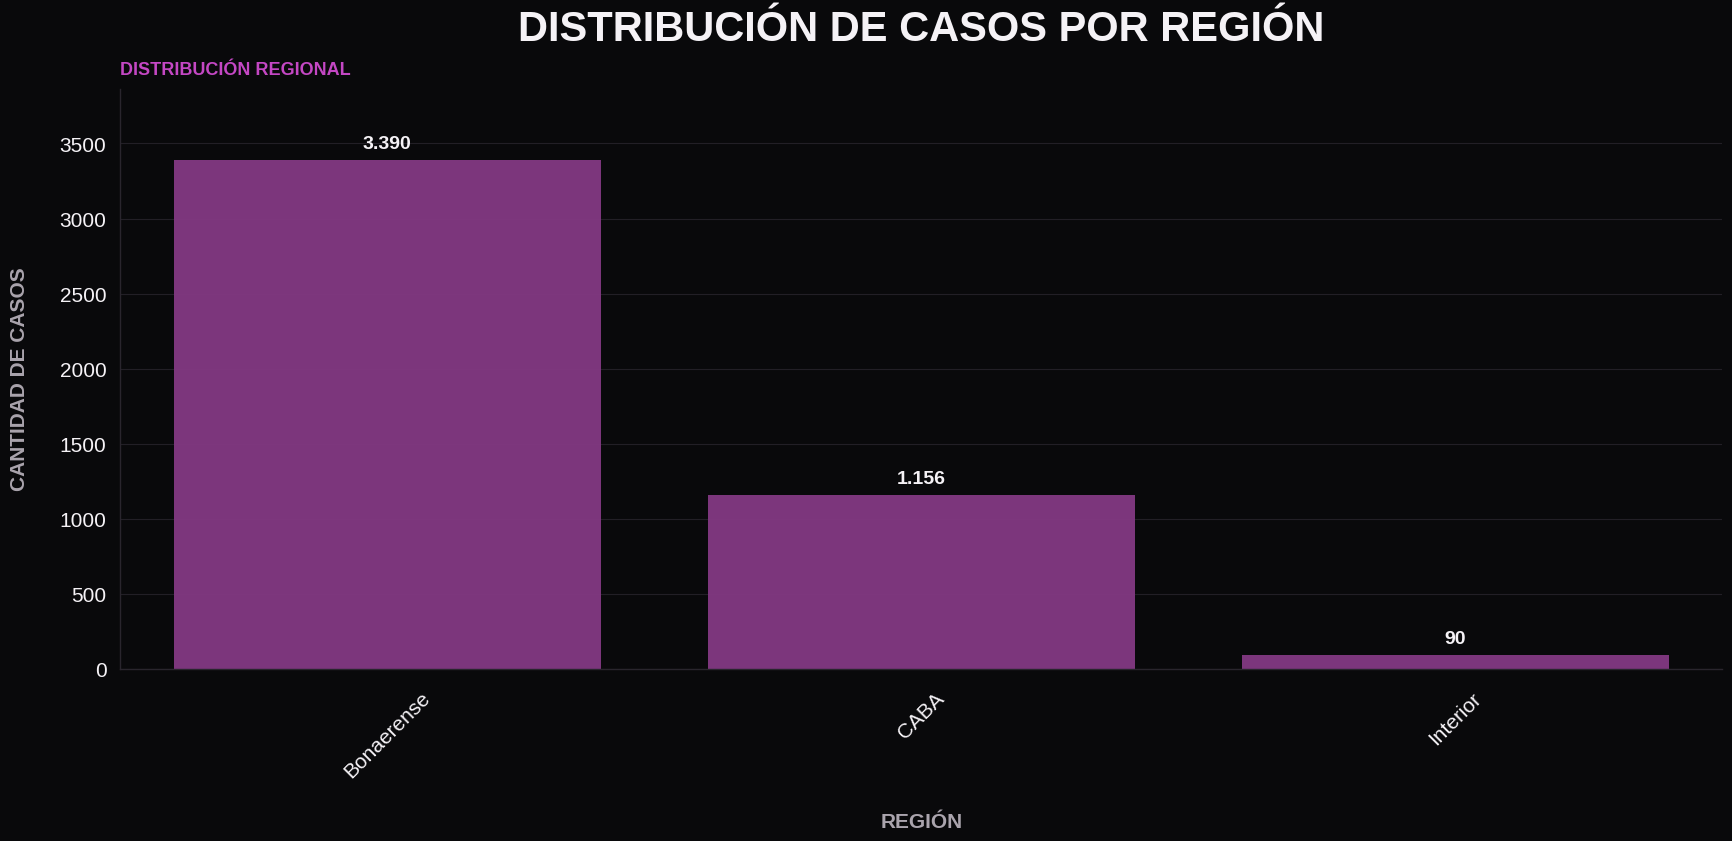

Imagen guardada en: distribucion_casos_region.png


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# PREPARAR LOS DATOS
# ============================================================

city_counts = (
    df_ciudades_corregidas_2['Poblacion_limpia']
    .value_counts()
)

# ============================================================
# PALETA DE COLORES
# ============================================================

BG_COLOR = '#09090B'          # Negro grafito
TEXT_COLOR = '#F5F2F6'        # Blanco suave
MUTED_COLOR = '#AAA4AD'       # Gris claro
GRID_COLOR = '#29252D'        # Gris oscuro
ORCHID_DARK = '#8F2D8F'       # Orchid oscuro
ORCHID_GLOW = '#C447C4'       # Orchid brillante

# ============================================================
# CREAR LA FIGURA
# ============================================================

fig, ax = plt.subplots(
    figsize=(18, 10),
    facecolor=BG_COLOR
)

# Fondo del área del gráfico
ax.set_facecolor(BG_COLOR)

# ============================================================
# GRÁFICO DE BARRAS
# ============================================================

sns.barplot(
    x=city_counts.index,
    y=city_counts.values,
    ax=ax,
    color=ORCHID_DARK,
    edgecolor='none'
)

# Ajustar la apariencia de las barras
for bar in ax.patches:
    bar.set_alpha(0.95)

# ============================================================
# TÍTULO PRINCIPAL
# ============================================================

ax.set_title(
    'DISTRIBUCIÓN DE CASOS POR REGIÓN',
    fontsize=30,
    fontweight='bold',
    color=TEXT_COLOR,
    fontfamily='sans-serif',
    loc='center',
    pad=35
)

# ============================================================
# SUBTÍTULO
# ============================================================

ax.text(
    0,
    1.025,
    'DISTRIBUCIÓN REGIONAL',
    transform=ax.transAxes,
    fontsize=13,
    fontweight='bold',
    color=ORCHID_GLOW,
    ha='left'
)

# ============================================================
# ETIQUETAS DE LOS EJES
# ============================================================

ax.set_xlabel(
    'REGIÓN',
    fontsize=15,
    fontweight='bold',
    color=MUTED_COLOR,
    labelpad=22
)

ax.set_ylabel(
    'CANTIDAD DE CASOS',
    fontsize=15,
    fontweight='bold',
    color=MUTED_COLOR,
    labelpad=22
)

# ============================================================
# ETIQUETAS DEL EJE X
# ============================================================

ax.tick_params(
    axis='x',
    labelsize=15,
    rotation=45,
    colors=TEXT_COLOR,
    length=0,
    pad=14
)

# ============================================================
# ETIQUETAS DEL EJE Y
# ============================================================

ax.tick_params(
    axis='y',
    labelsize=15,
    colors=TEXT_COLOR,
    length=0,
    pad=10
)

# ============================================================
# CUADRÍCULA
# ============================================================

# Líneas horizontales sutiles para facilitar la lectura
ax.grid(
    axis='y',
    color=GRID_COLOR,
    linestyle='-',
    linewidth=0.8,
    alpha=0.8
)

# Ocultar líneas verticales
ax.grid(axis='x', visible=False)

# Mantener la cuadrícula detrás de las barras
ax.set_axisbelow(True)

# ============================================================
# BORDES
# ============================================================

# Ocultar bordes superior y derecho
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Mantener bordes inferiores y laterales muy sutiles
ax.spines['left'].set_color(GRID_COLOR)
ax.spines['bottom'].set_color(GRID_COLOR)

ax.spines['left'].set_linewidth(1)
ax.spines['bottom'].set_linewidth(1)

# ============================================================
# VALORES SOBRE LAS BARRAS
# ============================================================

for bar in ax.patches:

    height = bar.get_height()

    # Mostrar el valor ligeramente por encima de cada barra
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + (city_counts.max() * 0.015),
        f'{int(height):,}'.replace(',', '.'),
        ha='center',
        va='bottom',
        fontsize=14,
        fontweight='bold',
        color=TEXT_COLOR
    )

# ============================================================
# ESPACIO SUPERIOR PARA LOS VALORES
# ============================================================

ax.set_ylim(
    0,
    city_counts.max() * 1.14
)

# ============================================================
# AJUSTE FINAL DE ESPACIADO
# ============================================================

plt.subplots_adjust(
    left=0.09,
    right=0.98,
    top=0.85,
    bottom=0.27
)

# ============================================================
# GUARDAR COMO PNG DE ALTA RESOLUCIÓN
# ============================================================

ruta_png = 'distribucion_casos_region.png'

fig.savefig(
    ruta_png,
    dpi=300,
    bbox_inches='tight',
    facecolor=fig.get_facecolor(),
    edgecolor='none'
)

# ============================================================
# MOSTRAR EL GRÁFICO
# ============================================================

plt.show()

print(f'Imagen guardada en: {ruta_png}')

### ¿Qué hacemos si faltan valores para algunos atributos?

*Ante la falta de valores tenemos tres opciones:*

   *- Eliminamos cada suceso que tenga al menos un valor faltante.*
    
   *- Reemplazamos los valores faltantes por el valor más frecuente
      si el atributo es categórico o por el promedio si es numérico.*
      
   *-Eliminar los atributos con datos faltantes.*
      
*¿Qué harían ustedes?*

# 3 - Eliminar los NAs

In [ ]:
# Limpiar los NaN
df_sin_na = df_ciudades_corregidas.dropna()
df_sin_na.isna()

,Fecha,Sexo,AdenoV,RSV,INFA,INFB,PIV1,PIV2,PIV3,Edad(meses),Poblacion_limpia
0,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False
5,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...
6722,False,False,False,False,False,False,False,False,False,False,False
6723,False,False,False,False,False,False,False,False,False,False,False
6724,False,False,False,False,False,False,False,False,False,False,False
6725,False,False,False,False,False,False,False,False,False,False,False


In [ ]:
display(df_sin_na.head())

,Fecha,Sexo,AdenoV,RSV,INFA,INFB,PIV1,PIV2,PIV3,Edad(meses),Poblacion_limpia
0,03/01/11,F,-,-,-,-,-,-,-,96.0,CABA
1,03/01/11,F,-,-,-,-,-,-,-,4.0,La Ferrere
2,03/01/11,M,-,-,-,-,-,-,-,8.0,Villa Celina
3,03/01/11,M,-,-,-,-,-,-,-,8.0,Villa Celina
5,03/01/11,M,-,-,-,-,-,-,-,1.0,CABA


# 5 - Limpieza de los valores de prueba de los virus

In [ ]:
# Para cada virus (AdenoV 	RSV 	INFA 	INFB 	PIV1 	PIV2 	PIV3), solo admitir valores con sentido : + o -

df_correccion_virus = df_sin_na.copy()
df_correccion_virus = df_correccion_virus[df_correccion_virus['AdenoV'].isin(['+', '-'])]
df_correccion_virus = df_correccion_virus[df_correccion_virus['RSV'].isin(['+', '-'])]
df_correccion_virus = df_correccion_virus[df_correccion_virus['INFA'].isin(['+', '-'])]
df_correccion_virus = df_correccion_virus[df_correccion_virus['INFB'].isin(['+', '-'])]
df_correccion_virus = df_correccion_virus[df_correccion_virus['PIV1'].isin(['+', '-'])]
df_correccion_virus = df_correccion_virus[df_correccion_virus['PIV2'].isin(['+', '-'])]
df_correccion_virus = df_correccion_virus[df_correccion_virus['PIV3'].isin(['+', '-'])]


In [ ]:
# Verificación

nuevo_categorias_virus_Adenov = df_correccion_virus['AdenoV'].astype("category")
nuevo_categorias_virus_Adenov = nuevo_categorias_virus_Adenov.value_counts()

nuevo_categorias_virus_Adenov

,count
AdenoV,
-,4370
+,25


In [ ]:
nuevo_categorias_virus_PIV3 = df_correccion_virus['PIV3'].astype("category")
nuevo_categorias_virus_PIV3 = nuevo_categorias_virus_PIV3.value_counts()

nuevo_categorias_virus_PIV3

,count
PIV3,
-,4335
+,60


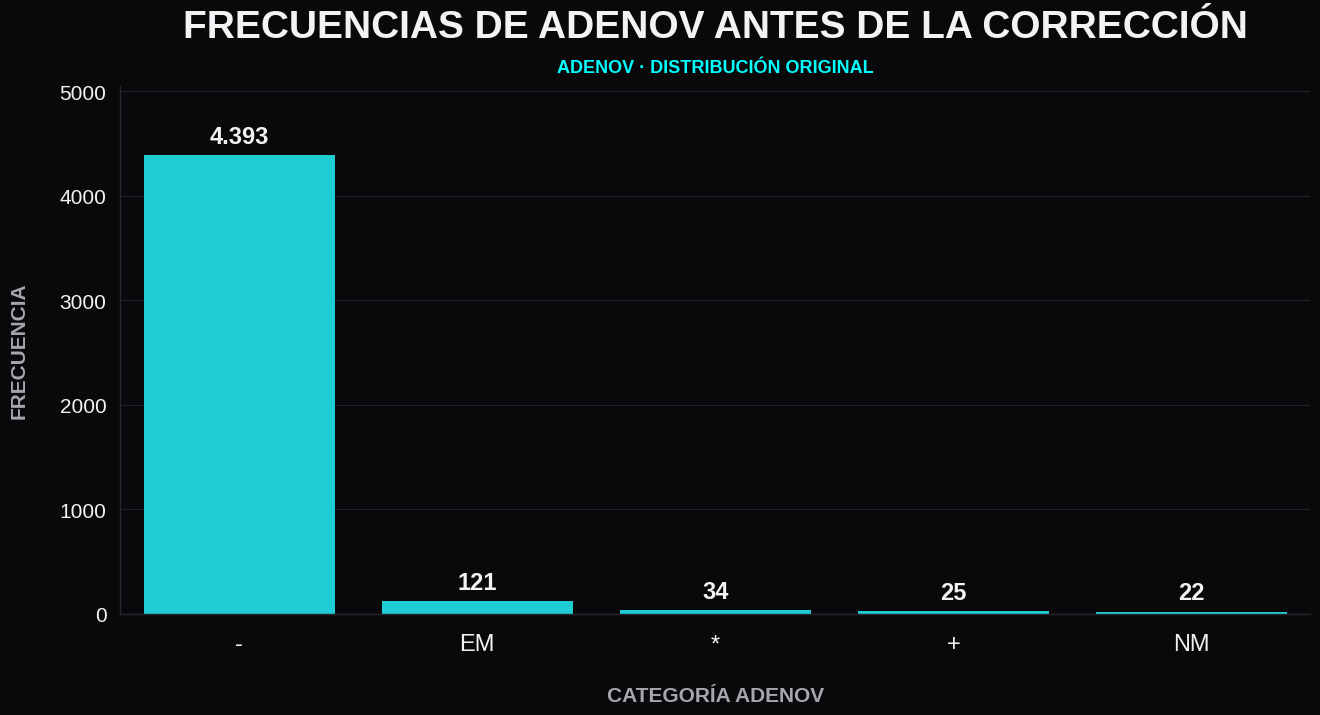

Imagen guardada en: frecuencias_AdenoV_antes_correccion.png


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# PREPARAR LOS DATOS
# ============================================================

freq_adenoV_before = (
    df_sin_na['AdenoV']
    .value_counts()
)

# ============================================================
# PALETA DE COLORES
# ============================================================

BG_COLOR = '#09090B'          # Negro grafito
TEXT_COLOR = '#F5F2F6'        # Blanco suave
MUTED_COLOR = '#AAA4AD'       # Gris claro
GRID_COLOR = '#29252D'        # Gris oscuro
CYAN_NEON = '#00F5FF'         # Cian neón
CYAN_GLOW = '#00FFFF'         # Cian brillante

# ============================================================
# CREAR LA FIGURA
# ============================================================

fig, ax = plt.subplots(
    figsize=(14, 8),
    facecolor=BG_COLOR
)

ax.set_facecolor(BG_COLOR)

# ============================================================
# GRÁFICO DE BARRAS
# ============================================================

sns.barplot(
    x=freq_adenoV_before.index,
    y=freq_adenoV_before.values,
    ax=ax,
    color=CYAN_NEON,
    edgecolor='none'
)

# Ajustar la apariencia de las barras
for bar in ax.patches:
    bar.set_alpha(0.95)

# ============================================================
# TÍTULO PRINCIPAL
# ============================================================

ax.set_title(
    'FRECUENCIAS DE ADENOV ANTES DE LA CORRECCIÓN',
    fontsize=28,
    fontweight='bold',
    color=TEXT_COLOR,
    fontfamily='sans-serif',
    loc='center',
    pad=35
)

# ============================================================
# SUBTÍTULO
# ============================================================

ax.text(
    0.5,
    1.025,
    'ADENOV · DISTRIBUCIÓN ORIGINAL',
    transform=ax.transAxes,
    fontsize=13,
    fontweight='bold',
    color=CYAN_GLOW,
    ha='center'
)

# ============================================================
# ETIQUETAS DE LOS EJES
# ============================================================

ax.set_xlabel(
    'CATEGORÍA ADENOV',
    fontsize=15,
    fontweight='bold',
    color=MUTED_COLOR,
    labelpad=22
)

ax.set_ylabel(
    'FRECUENCIA',
    fontsize=15,
    fontweight='bold',
    color=MUTED_COLOR,
    labelpad=22
)

# ============================================================
# ETIQUETAS DEL EJE X
# ============================================================

ax.tick_params(
    axis='x',
    labelsize=17,
    rotation=0,
    colors=TEXT_COLOR,
    length=0,
    pad=14
)

# ============================================================
# ETIQUETAS DEL EJE Y
# ============================================================

ax.tick_params(
    axis='y',
    labelsize=15,
    colors=TEXT_COLOR,
    length=0,
    pad=10
)

# ============================================================
# CUADRÍCULA
# ============================================================

ax.grid(
    axis='y',
    color=GRID_COLOR,
    linestyle='-',
    linewidth=0.8,
    alpha=0.8
)

ax.grid(axis='x', visible=False)

# Mantener la cuadrícula detrás de las barras
ax.set_axisbelow(True)

# ============================================================
# BORDES
# ============================================================

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.spines['left'].set_color(GRID_COLOR)
ax.spines['bottom'].set_color(GRID_COLOR)

ax.spines['left'].set_linewidth(1)
ax.spines['bottom'].set_linewidth(1)

# ============================================================
# VALORES SOBRE LAS BARRAS
# ============================================================

for bar in ax.patches:

    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + (freq_adenoV_before.max() * 0.015),
        f'{int(height):,}'.replace(',', '.'),
        ha='center',
        va='bottom',
        fontsize=17,
        fontweight='bold',
        color=TEXT_COLOR
    )

# ============================================================
# ESPACIO SUPERIOR PARA LOS VALORES
# ============================================================

ax.set_ylim(
    0,
    freq_adenoV_before.max() * 1.15
)

# ============================================================
# AJUSTE FINAL
# ============================================================

plt.subplots_adjust(
    left=0.10,
    right=0.95,
    top=0.84,
    bottom=0.18
)

# ============================================================
# GUARDAR COMO PNG DE ALTA RESOLUCIÓN
# ============================================================

ruta_png = 'frecuencias_AdenoV_antes_correccion.png'

fig.savefig(
    ruta_png,
    dpi=300,
    bbox_inches='tight',
    facecolor=fig.get_facecolor(),
    edgecolor='none'
)

# ============================================================
# MOSTRAR EL GRÁFICO
# ============================================================

plt.show()

print(f'Imagen guardada en: {ruta_png}')


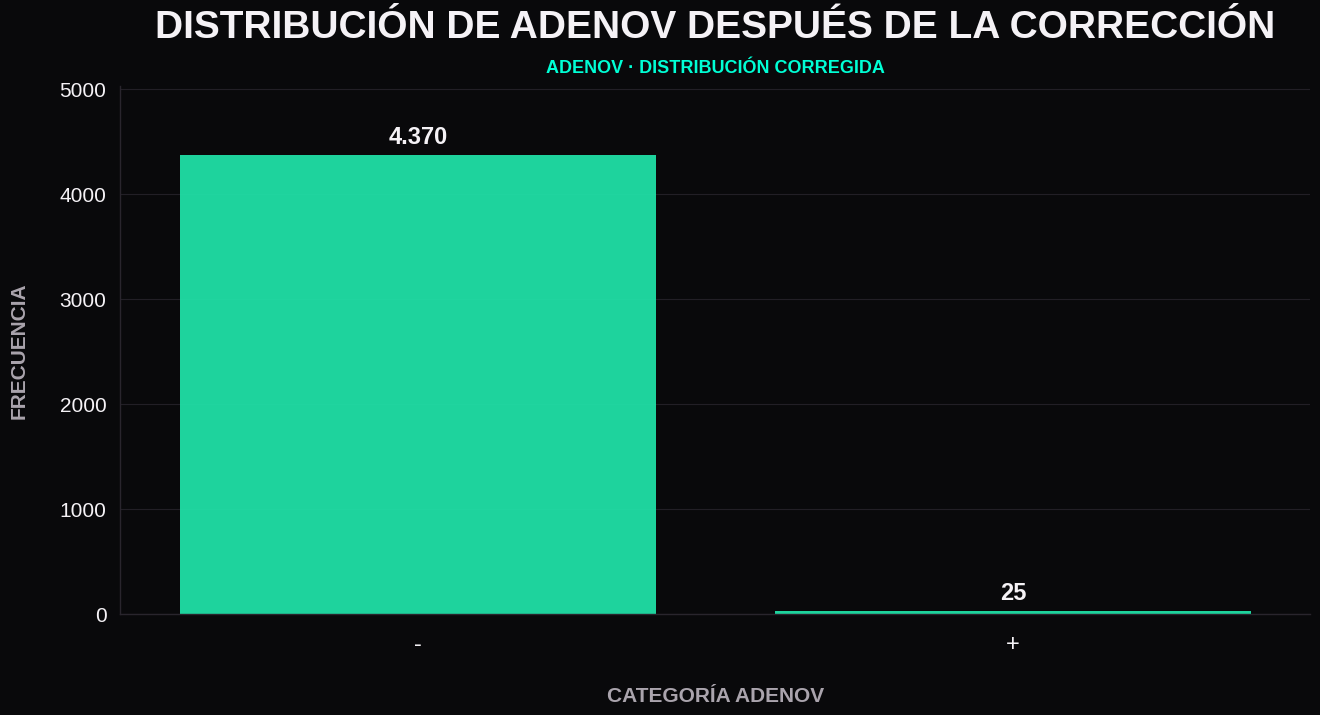

Imagen guardada en: frecuencias_AdenoV_despues_correccion.png


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# PREPARAR LOS DATOS
# ============================================================

freq_adenoV_after = (
    df_correccion_virus['AdenoV']
    .value_counts()
)

# ============================================================
# PALETA DE COLORES
# ============================================================

BG_COLOR = '#09090B'          # Negro grafito
TEXT_COLOR = '#F5F2F6'        # Blanco suave
MUTED_COLOR = '#AAA4AD'       # Gris claro
GRID_COLOR = '#29252D'        # Gris oscuro

# Verde-cian neón
GREEN_CYAN = '#00FFB3'        # Verde cian principal
GREEN_GLOW = '#00FFD5'        # Verde cian brillante

# ============================================================
# CREAR LA FIGURA
# ============================================================

fig, ax = plt.subplots(
    figsize=(14, 8),
    facecolor=BG_COLOR
)

ax.set_facecolor(BG_COLOR)

# ============================================================
# GRÁFICO DE BARRAS
# ============================================================

sns.barplot(
    x=freq_adenoV_after.index,
    y=freq_adenoV_after.values,
    ax=ax,
    color=GREEN_CYAN,
    edgecolor='none'
)

# Ajustar la apariencia de las barras
for bar in ax.patches:
    bar.set_alpha(0.95)

# ============================================================
# TÍTULO PRINCIPAL
# ============================================================

ax.set_title(
    'DISTRIBUCIÓN DE ADENOV DESPUÉS DE LA CORRECCIÓN',
    fontsize=28,
    fontweight='bold',
    color=TEXT_COLOR,
    fontfamily='sans-serif',
    loc='center',
    pad=35
)

# ============================================================
# SUBTÍTULO
# ============================================================

ax.text(
    0.5,
    1.025,
    'ADENOV · DISTRIBUCIÓN CORREGIDA',
    transform=ax.transAxes,
    fontsize=13,
    fontweight='bold',
    color=GREEN_GLOW,
    ha='center'
)

# ============================================================
# ETIQUETAS DE LOS EJES
# ============================================================

ax.set_xlabel(
    'CATEGORÍA ADENOV',
    fontsize=15,
    fontweight='bold',
    color=MUTED_COLOR,
    labelpad=22
)

ax.set_ylabel(
    'FRECUENCIA',
    fontsize=15,
    fontweight='bold',
    color=MUTED_COLOR,
    labelpad=22
)

# ============================================================
# ETIQUETAS DEL EJE X
# ============================================================

ax.tick_params(
    axis='x',
    labelsize=17,
    rotation=0,
    colors=TEXT_COLOR,
    length=0,
    pad=14
)

# ============================================================
# ETIQUETAS DEL EJE Y
# ============================================================

ax.tick_params(
    axis='y',
    labelsize=15,
    colors=TEXT_COLOR,
    length=0,
    pad=10
)

# ============================================================
# CUADRÍCULA
# ============================================================

ax.grid(
    axis='y',
    color=GRID_COLOR,
    linestyle='-',
    linewidth=0.8,
    alpha=0.8
)

ax.grid(axis='x', visible=False)

# Mantener la cuadrícula detrás de las barras
ax.set_axisbelow(True)

# ============================================================
# BORDES
# ============================================================

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.spines['left'].set_color(GRID_COLOR)
ax.spines['bottom'].set_color(GRID_COLOR)

ax.spines['left'].set_linewidth(1)
ax.spines['bottom'].set_linewidth(1)

# ============================================================
# VALORES SOBRE LAS BARRAS
# ============================================================

for bar in ax.patches:

    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + (freq_adenoV_after.max() * 0.015),
        f'{int(height):,}'.replace(',', '.'),
        ha='center',
        va='bottom',
        fontsize=17,
        fontweight='bold',
        color=TEXT_COLOR
    )

# ============================================================
# ESPACIO SUPERIOR PARA LOS VALORES
# ============================================================

ax.set_ylim(
    0,
    freq_adenoV_after.max() * 1.15
)

# ============================================================
# AJUSTE FINAL
# ============================================================

plt.subplots_adjust(
    left=0.10,
    right=0.95,
    top=0.84,
    bottom=0.18
)

# ============================================================
# GUARDAR COMO PNG DE ALTA RESOLUCIÓN
# ============================================================

ruta_png = 'frecuencias_AdenoV_despues_correccion.png'

fig.savefig(
    ruta_png,
    dpi=300,
    bbox_inches='tight',
    facecolor=fig.get_facecolor(),
    edgecolor='none'
)

# ============================================================
# MOSTRAR EL GRÁFICO
# ============================================================

plt.show()

print(f'Imagen guardada en: {ruta_png}')


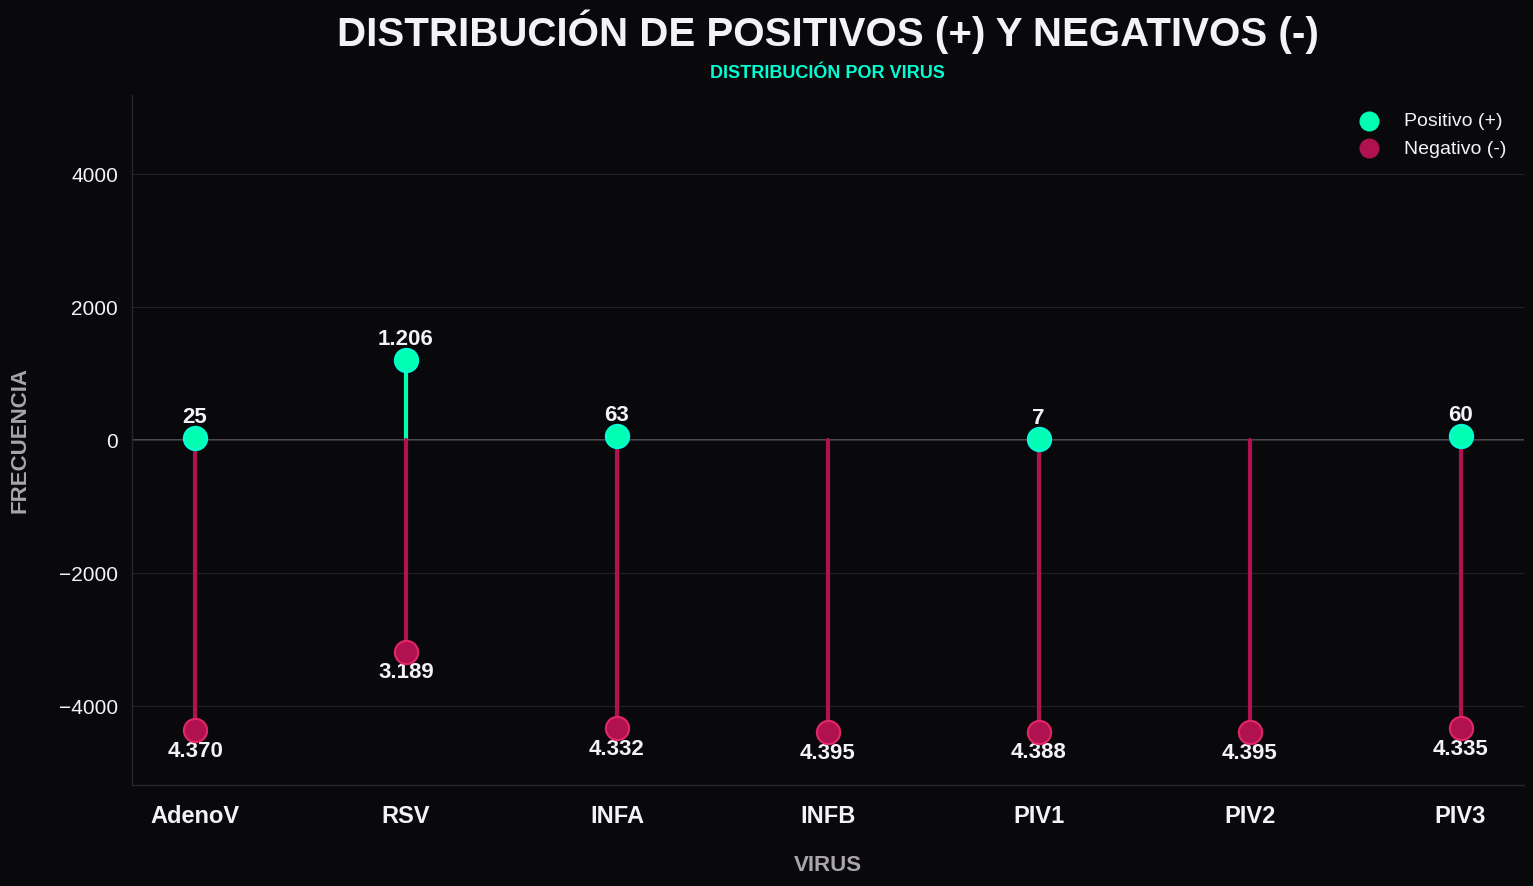

Imagen guardada en: distribucion_virus_positivo_negativo.png


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# COLUMNAS DE VIRUS
# ============================================================

virus_columns = [
    'AdenoV',
    'RSV',
    'INFA',
    'INFB',
    'PIV1',
    'PIV2',
    'PIV3'
]

# ============================================================
# PALETA DE COLORES
# ============================================================

BG_COLOR = '#09090B'          # Negro grafito
TEXT_COLOR = '#F5F2F6'        # Blanco suave
MUTED_COLOR = '#AAA4AD'       # Gris claro
GRID_COLOR = '#29252D'        # Gris oscuro

GREEN_CYAN = '#00FFB3'        # Verde cian neón para positivos
GREEN_GLOW = '#00FFD5'        # Verde cian brillante

WINE_NEON = '#B0124F'         # Rojo vino neón para negativos
WINE_GLOW = '#E32668'         # Rojo vino brillante

# ============================================================
# CREAR LA FIGURA
# ============================================================

fig, ax = plt.subplots(
    figsize=(16, 10),
    facecolor=BG_COLOR
)

ax.set_facecolor(BG_COLOR)

# ============================================================
# RECOPILAR LOS DATOS
# ============================================================

plot_data = []
max_freq = 0

for col in virus_columns:

    freq = df_correccion_virus[col].value_counts()

    positive_count = freq.get('+', 0)
    negative_count = freq.get('-', 0)

    plot_data.append({
        'Virus': col,
        'Categoria': '+',
        'Frecuencia': positive_count
    })

    plot_data.append({
        'Virus': col,
        'Categoria': '-',
        'Frecuencia': negative_count
    })

    max_freq = max(
        max_freq,
        positive_count,
        negative_count
    )

# ============================================================
# DIBUJAR LOS LOLLIPOPS
# ============================================================

positions = range(len(virus_columns))

for i, col in enumerate(virus_columns):

    freq = df_correccion_virus[col].value_counts()

    positive_count = freq.get('+', 0)
    negative_count = freq.get('-', 0)

    # --------------------------------------------------------
    # CATEGORÍA POSITIVA (+)
    # --------------------------------------------------------

    if positive_count > 0:

        # Línea vertical positiva
        ax.plot(
            [i, i],
            [0, positive_count],
            color=GREEN_CYAN,
            linewidth=3,
            zorder=1
        )

        # Punto positivo
        ax.scatter(
            i,
            positive_count,
            color=GREEN_CYAN,
            s=280,
            edgecolor=GREEN_GLOW,
            linewidth=1.5,
            zorder=5
        )

        # Valor positivo
        ax.text(
            i,
            positive_count + (max_freq * 0.035),
            f'{positive_count:,}'.replace(',', '.'),
            ha='center',
            va='bottom',
            fontsize=16,
            color=TEXT_COLOR,
            fontweight='bold'
        )

    # --------------------------------------------------------
    # CATEGORÍA NEGATIVA (-)
    # --------------------------------------------------------

    if negative_count > 0:

        # Línea vertical negativa
        ax.plot(
            [i, i],
            [0, -negative_count],
            color=WINE_NEON,
            linewidth=3,
            zorder=1
        )

        # Punto negativo
        ax.scatter(
            i,
            -negative_count,
            color=WINE_NEON,
            s=280,
            edgecolor=WINE_GLOW,
            linewidth=1.5,
            zorder=5
        )

        # Valor negativo
        ax.text(
            i,
            -negative_count - (max_freq * 0.035),
            f'{negative_count:,}'.replace(',', '.'),
            ha='center',
            va='top',
            fontsize=16,
            color=TEXT_COLOR,
            fontweight='bold'
        )

# ============================================================
# TÍTULO PRINCIPAL
# ============================================================

ax.set_title(
    'DISTRIBUCIÓN DE POSITIVOS (+) Y NEGATIVOS (-)',
    fontsize=29,
    fontweight='bold',
    color=TEXT_COLOR,
    fontfamily='sans-serif',
    loc='center',
    pad=35
)

# ============================================================
# SUBTÍTULO
# ============================================================

ax.text(
    0.5,
    1.025,
    'DISTRIBUCIÓN POR VIRUS',
    transform=ax.transAxes,
    fontsize=13,
    fontweight='bold',
    color=GREEN_GLOW,
    ha='center'
)

# ============================================================
# ETIQUETAS DE LOS EJES
# ============================================================

ax.set_xlabel(
    'VIRUS',
    fontsize=16,
    fontweight='bold',
    color=MUTED_COLOR,
    labelpad=20
)

ax.set_ylabel(
    'FRECUENCIA',
    fontsize=16,
    fontweight='bold',
    color=MUTED_COLOR,
    labelpad=20
)

# ============================================================
# EJE X
# ============================================================

ax.set_xticks(list(positions))

ax.set_xticklabels(
    virus_columns,
    rotation=0,
    fontsize=17,
    fontweight='bold',
    color=TEXT_COLOR
)

ax.tick_params(
    axis='x',
    length=0,
    pad=14
)

# ============================================================
# EJE Y
# ============================================================

ax.tick_params(
    axis='y',
    labelsize=15,
    colors=TEXT_COLOR,
    length=0,
    pad=10
)

# ============================================================
# LÍMITES DEL EJE Y
# ============================================================

ax.set_ylim(
    -max_freq * 1.18,
    max_freq * 1.18
)

# ============================================================
# LÍNEA CENTRAL
# ============================================================

ax.axhline(
    0,
    color='#5C5660',
    linewidth=1.2,
    linestyle='-',
    zorder=0
)

# ============================================================
# CUADRÍCULA
# ============================================================

ax.grid(
    axis='y',
    linestyle='-',
    linewidth=0.8,
    alpha=0.8,
    color=GRID_COLOR
)

ax.grid(
    axis='x',
    visible=False
)

ax.set_axisbelow(True)

# ============================================================
# BORDES
# ============================================================

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.spines['left'].set_color(GRID_COLOR)
ax.spines['bottom'].set_color(GRID_COLOR)

ax.spines['left'].set_linewidth(1)
ax.spines['bottom'].set_linewidth(1)

# ============================================================
# LEYENDA MANUAL
# ============================================================

ax.scatter(
    [],
    [],
    color=GREEN_CYAN,
    s=180,
    label='Positivo (+)'
)

ax.scatter(
    [],
    [],
    color=WINE_NEON,
    s=180,
    label='Negativo (-)'
)

legend = ax.legend(
    loc='upper right',
    frameon=False,
    fontsize=14,
    labelcolor=TEXT_COLOR
)

# ============================================================
# AJUSTE FINAL
# ============================================================

plt.subplots_adjust(
    left=0.09,
    right=0.96,
    top=0.84,
    bottom=0.15
)

# ============================================================
# GUARDAR COMO PNG DE ALTA RESOLUCIÓN
# ============================================================

ruta_png = 'distribucion_virus_positivo_negativo.png'

fig.savefig(
    ruta_png,
    dpi=300,
    bbox_inches='tight',
    facecolor=fig.get_facecolor(),
    edgecolor='none'
)

# ============================================================
# MOSTRAR EL GRÁFICO
# ============================================================

plt.show()

print(f'Imagen guardada en: {ruta_png}')


# 6- Eliminación y limpieza de edades sin sentido (>18 años)

### ¿Qué nos dicen los datos?¿Tienen sentido?

***Hay datos que se alejan del comportamiento estándar y para eso tenemos conocer las razones***

***-Errores al cargar los datos***

***-Valores erráticos (Outliers)***

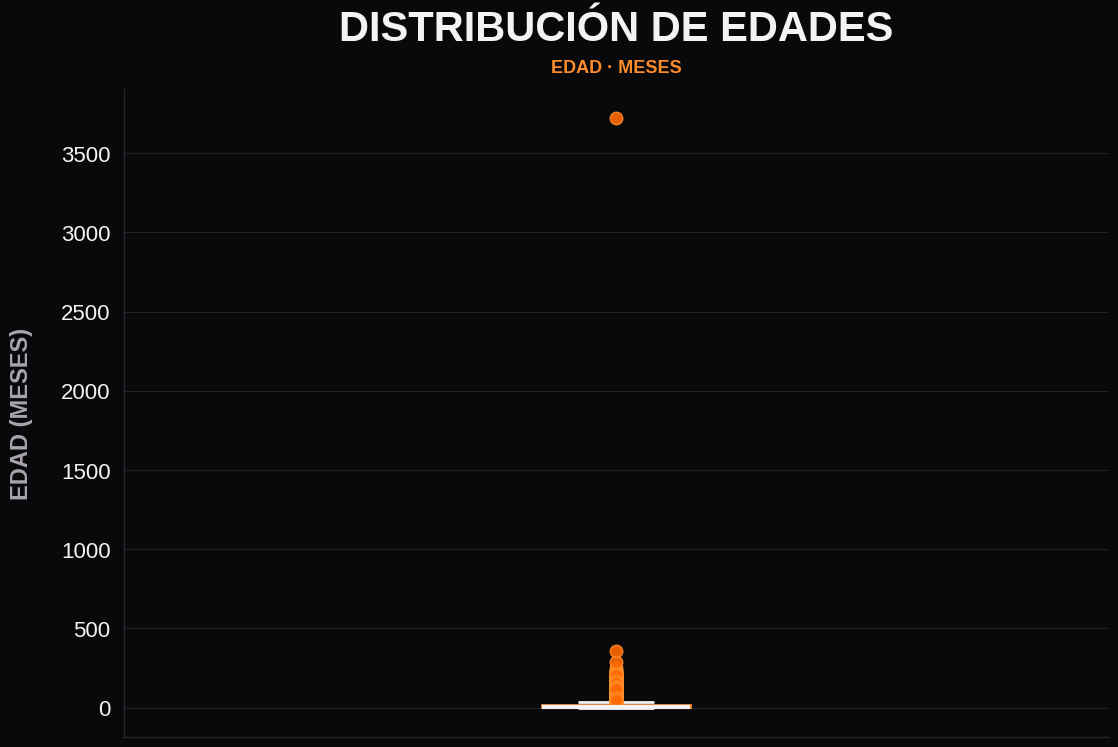

Imagen guardada en: distribucion_edades_naranja.png


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# PREPARAR EL ESTILO
# ============================================================

# Fondo oscuro y estética minimalista
BG_COLOR = '#09090B'          # Negro grafito
TEXT_COLOR = '#F5F2F6'        # Blanco suave
MUTED_COLOR = '#AAA4AD'       # Gris claro
GRID_COLOR = '#29252D'        # Gris oscuro

# Naranja neón
ORANGE_NEON = '#FF6A00'       # Naranja neón principal
ORANGE_GLOW = '#FF8C2B'       # Naranja brillante

# ============================================================
# CREAR LA FIGURA
# ============================================================

fig, ax = plt.subplots(
    figsize=(12, 9),
    facecolor=BG_COLOR
)

ax.set_facecolor(BG_COLOR)

# ============================================================
# BOXPLOT
# ============================================================

bp = ax.boxplot(
    df_correccion_virus['Edad(meses)'],
    patch_artist=True,

    # Caja
    boxprops=dict(
        facecolor=ORANGE_NEON,
        color=ORANGE_GLOW,
        linewidth=2
    ),

    # Mediana
    medianprops=dict(
        color=TEXT_COLOR,
        linewidth=3
    ),

    # Bigotes
    whiskerprops=dict(
        color=TEXT_COLOR,
        linewidth=2
    ),

    # Extremos de los bigotes
    capprops=dict(
        color=TEXT_COLOR,
        linewidth=2
    ),

    # Valores atípicos
    flierprops=dict(
        marker='o',
        markerfacecolor=ORANGE_NEON,
        markeredgecolor=ORANGE_GLOW,
        markersize=9,
        alpha=0.9
    )
)

# ============================================================
# TÍTULO PRINCIPAL
# ============================================================

ax.set_title(
    'DISTRIBUCIÓN DE EDADES',
    fontsize=30,
    fontweight='bold',
    color=TEXT_COLOR,
    fontfamily='sans-serif',
    loc='center',
    pad=35
)

# ============================================================
# SUBTÍTULO
# ============================================================

ax.text(
    0.5,
    1.025,
    'EDAD · MESES',
    transform=ax.transAxes,
    fontsize=13,
    fontweight='bold',
    color=ORANGE_GLOW,
    ha='center'
)

# ============================================================
# EJE Y
# ============================================================

ax.set_ylabel(
    'EDAD (MESES)',
    fontsize=17,
    fontweight='bold',
    color=MUTED_COLOR,
    labelpad=20
)

# ============================================================
# EJE X
# ============================================================

# Ocultar etiquetas del eje X porque existe un único boxplot
ax.set_xticks([])
ax.set_xlabel('')

# ============================================================
# CONFIGURACIÓN DEL EJE Y
# ============================================================

ax.tick_params(
    axis='y',
    labelsize=16,
    colors=TEXT_COLOR,
    length=0,
    pad=10
)

# ============================================================
# CUADRÍCULA
# ============================================================

ax.grid(
    axis='y',
    color=GRID_COLOR,
    linestyle='-',
    linewidth=0.8,
    alpha=0.8
)

ax.grid(
    axis='x',
    visible=False
)

ax.set_axisbelow(True)

# ============================================================
# BORDES
# ============================================================

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.spines['left'].set_color(GRID_COLOR)
ax.spines['bottom'].set_color(GRID_COLOR)

ax.spines['left'].set_linewidth(1)
ax.spines['bottom'].set_linewidth(1)

# ============================================================
# AJUSTE FINAL
# ============================================================

plt.subplots_adjust(
    left=0.13,
    right=0.95,
    top=0.84,
    bottom=0.12
)

# ============================================================
# GUARDAR COMO PNG DE ALTA RESOLUCIÓN
# ============================================================

ruta_png = 'distribucion_edades_naranja.png'

fig.savefig(
    ruta_png,
    dpi=300,
    bbox_inches='tight',
    facecolor=fig.get_facecolor(),
    edgecolor='none'
)

# ============================================================
# MOSTRAR EL GRÁFICO
# ============================================================

plt.show()

print(f'Imagen guardada en: {ruta_png}')


***Criterio IQR para el tratamiento de outliers en las edades***

In [ ]:
Q1 = df_correccion_virus['Edad(meses)'].quantile(0.02)
Q3 = df_correccion_virus['Edad(meses)'].quantile(0.98)
IQR = Q3 - Q1
idx = ~((df_correccion_virus['Edad(meses)'] < (Q1 - 1.5 * IQR)) | (df_correccion_virus['Edad(meses)'] > (Q3 + 1.5 * IQR)))

In [ ]:
df_correccion_edad = df_correccion_virus[idx]

In [ ]:
df_correccion_edad.head()

,Fecha,Sexo,AdenoV,RSV,INFA,INFB,PIV1,PIV2,PIV3,Edad(meses),Poblacion_limpia
0,03/01/11,F,-,-,-,-,-,-,-,96.0,CABA
1,03/01/11,F,-,-,-,-,-,-,-,4.0,La Ferrere
2,03/01/11,M,-,-,-,-,-,-,-,8.0,Villa Celina
3,03/01/11,M,-,-,-,-,-,-,-,8.0,Villa Celina
5,03/01/11,M,-,-,-,-,-,-,-,1.0,CABA


Pero lo anterior sigue teniendo valores muy grandes de edad (> 18 años o 216 meses)

**Criterio de z-score para el tratamiento de outliers**

In [ ]:
import numpy as np
# Test de outliers

'''Este test me devuelve las posiciones que tiene un z-score por encima del valor de referencia;
es decir, las posiciones de los datos outliers'''

#Calcula el estadístico del test
z = np.abs(ss.zscore(df_correccion_virus['Edad(meses)']))

#Muestra las posiciones donde están los outliers
threshold = 3
print(np.where(z > threshold))

(array([  79,  232,  313, 1398, 2055, 3095, 3224, 3488, 3548]),)


In [ ]:
# Elimino outliers

df_correccion_edad = df_correccion_virus[(z < threshold)]

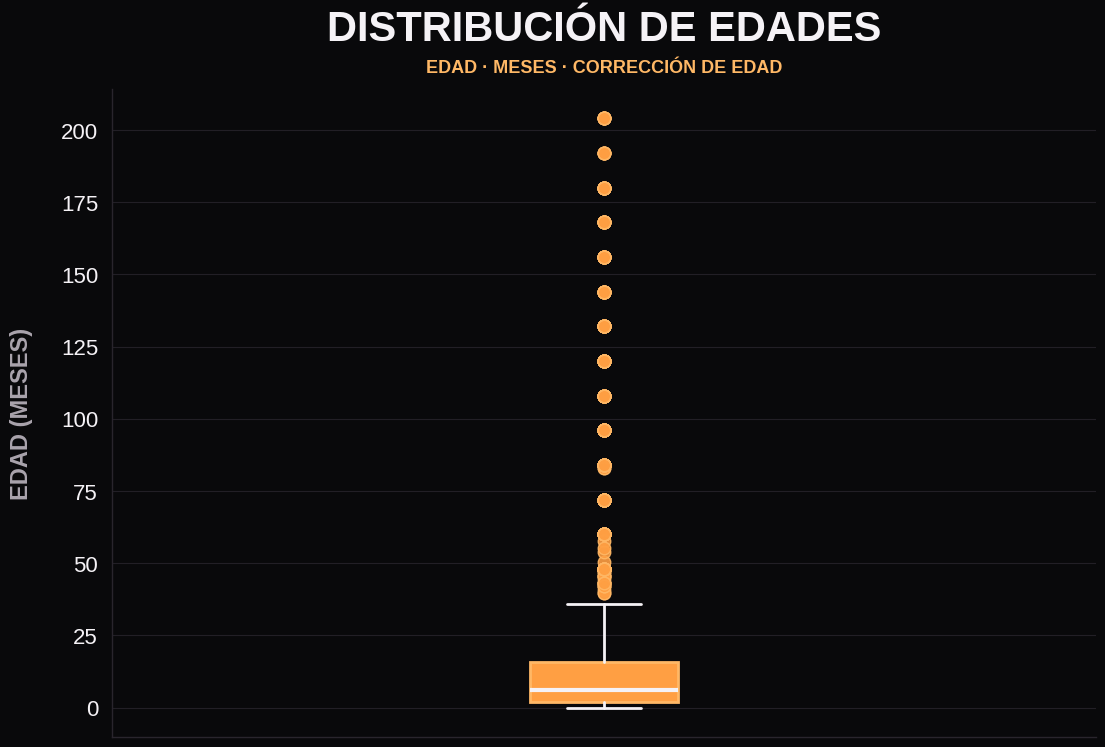

Imagen guardada en: distribucion_edades_z_corregido.png


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# PREPARAR EL ESTILO
# ============================================================

# Fondo oscuro y estética minimalista
BG_COLOR = '#09090B'          # Negro grafito
TEXT_COLOR = '#F5F2F6'        # Blanco suave
MUTED_COLOR = '#AAA4AD'       # Gris claro
GRID_COLOR = '#29252D'        # Gris oscuro

# Naranja claro y luminoso
ORANGE_LIGHT = '#FF9F43'      # Naranja claro principal
ORANGE_GLOW = '#FFB866'       # Naranja claro brillante

# ============================================================
# CREAR LA FIGURA
# ============================================================

fig, ax = plt.subplots(
    figsize=(12, 9),
    facecolor=BG_COLOR
)

ax.set_facecolor(BG_COLOR)

# ============================================================
# BOXPLOT
# ============================================================

bp = ax.boxplot(
    df_correccion_edad['Edad(meses)'],
    patch_artist=True,

    # Caja
    boxprops=dict(
        facecolor=ORANGE_LIGHT,
        color=ORANGE_GLOW,
        linewidth=2
    ),

    # Mediana
    medianprops=dict(
        color=TEXT_COLOR,
        linewidth=3
    ),

    # Bigotes
    whiskerprops=dict(
        color=TEXT_COLOR,
        linewidth=2
    ),

    # Extremos de los bigotes
    capprops=dict(
        color=TEXT_COLOR,
        linewidth=2
    ),

    # Valores atípicos
    flierprops=dict(
        marker='o',
        markerfacecolor=ORANGE_LIGHT,
        markeredgecolor=ORANGE_GLOW,
        markersize=9,
        alpha=0.9
    )
)

# ============================================================
# TÍTULO PRINCIPAL
# ============================================================

ax.set_title(
    'DISTRIBUCIÓN DE EDADES',
    fontsize=30,
    fontweight='bold',
    color=TEXT_COLOR,
    fontfamily='sans-serif',
    loc='center',
    pad=35
)

# ============================================================
# SUBTÍTULO
# ============================================================

ax.text(
    0.5,
    1.025,
    'EDAD · MESES · CORRECCIÓN DE EDAD',
    transform=ax.transAxes,
    fontsize=13,
    fontweight='bold',
    color=ORANGE_GLOW,
    ha='center'
)

# ============================================================
# EJE Y
# ============================================================

ax.set_ylabel(
    'EDAD (MESES)',
    fontsize=17,
    fontweight='bold',
    color=MUTED_COLOR,
    labelpad=20
)

# ============================================================
# EJE X
# ============================================================

# Ocultar etiquetas del eje X porque existe un único boxplot
ax.set_xticks([])
ax.set_xlabel('')

# ============================================================
# CONFIGURACIÓN DEL EJE Y
# ============================================================

ax.tick_params(
    axis='y',
    labelsize=16,
    colors=TEXT_COLOR,
    length=0,
    pad=10
)

# ============================================================
# CUADRÍCULA
# ============================================================

ax.grid(
    axis='y',
    color=GRID_COLOR,
    linestyle='-',
    linewidth=0.8,
    alpha=0.8
)

ax.grid(
    axis='x',
    visible=False
)

ax.set_axisbelow(True)

# ============================================================
# BORDES
# ============================================================

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.spines['left'].set_color(GRID_COLOR)
ax.spines['bottom'].set_color(GRID_COLOR)

ax.spines['left'].set_linewidth(1)
ax.spines['bottom'].set_linewidth(1)

# ============================================================
# AJUSTE FINAL
# ============================================================

plt.subplots_adjust(
    left=0.13,
    right=0.95,
    top=0.84,
    bottom=0.12
)

# ============================================================
# GUARDAR COMO PNG DE ALTA RESOLUCIÓN
# ============================================================

ruta_png = 'distribucion_edades_z_corregido.png'

fig.savefig(
    ruta_png,
    dpi=300,
    bbox_inches='tight',
    facecolor=fig.get_facecolor(),
    edgecolor='none'
)

# ============================================================
# MOSTRAR EL GRÁFICO
# ============================================================

plt.show()

print(f'Imagen guardada en: {ruta_png}')

In [ ]:
# Verificación del nuevo maximo de edad (Tiene que ser menor a 216 meses)
df_correccion_edad['Edad(meses)'].max()

204.0

# 7 - Corrección de las categorias de Sexo

In [ ]:
# Solo admitir M o F
df_correccion_sexo = df_correccion_edad.copy()
df_correccion_sexo = df_correccion_sexo[df_correccion_sexo['Sexo'].isin(['M', 'F'])]

In [ ]:
# Verificacion
nuevas_categorias_sexo = df_correccion_sexo['Sexo'].astype("category")
nuevas_categorias_sexo = nuevas_categorias_sexo.value_counts()

nuevas_categorias_sexo

,count
Sexo,
M,2444
F,1939


# 8 - Analisis de la distribución de casos + por ciudad

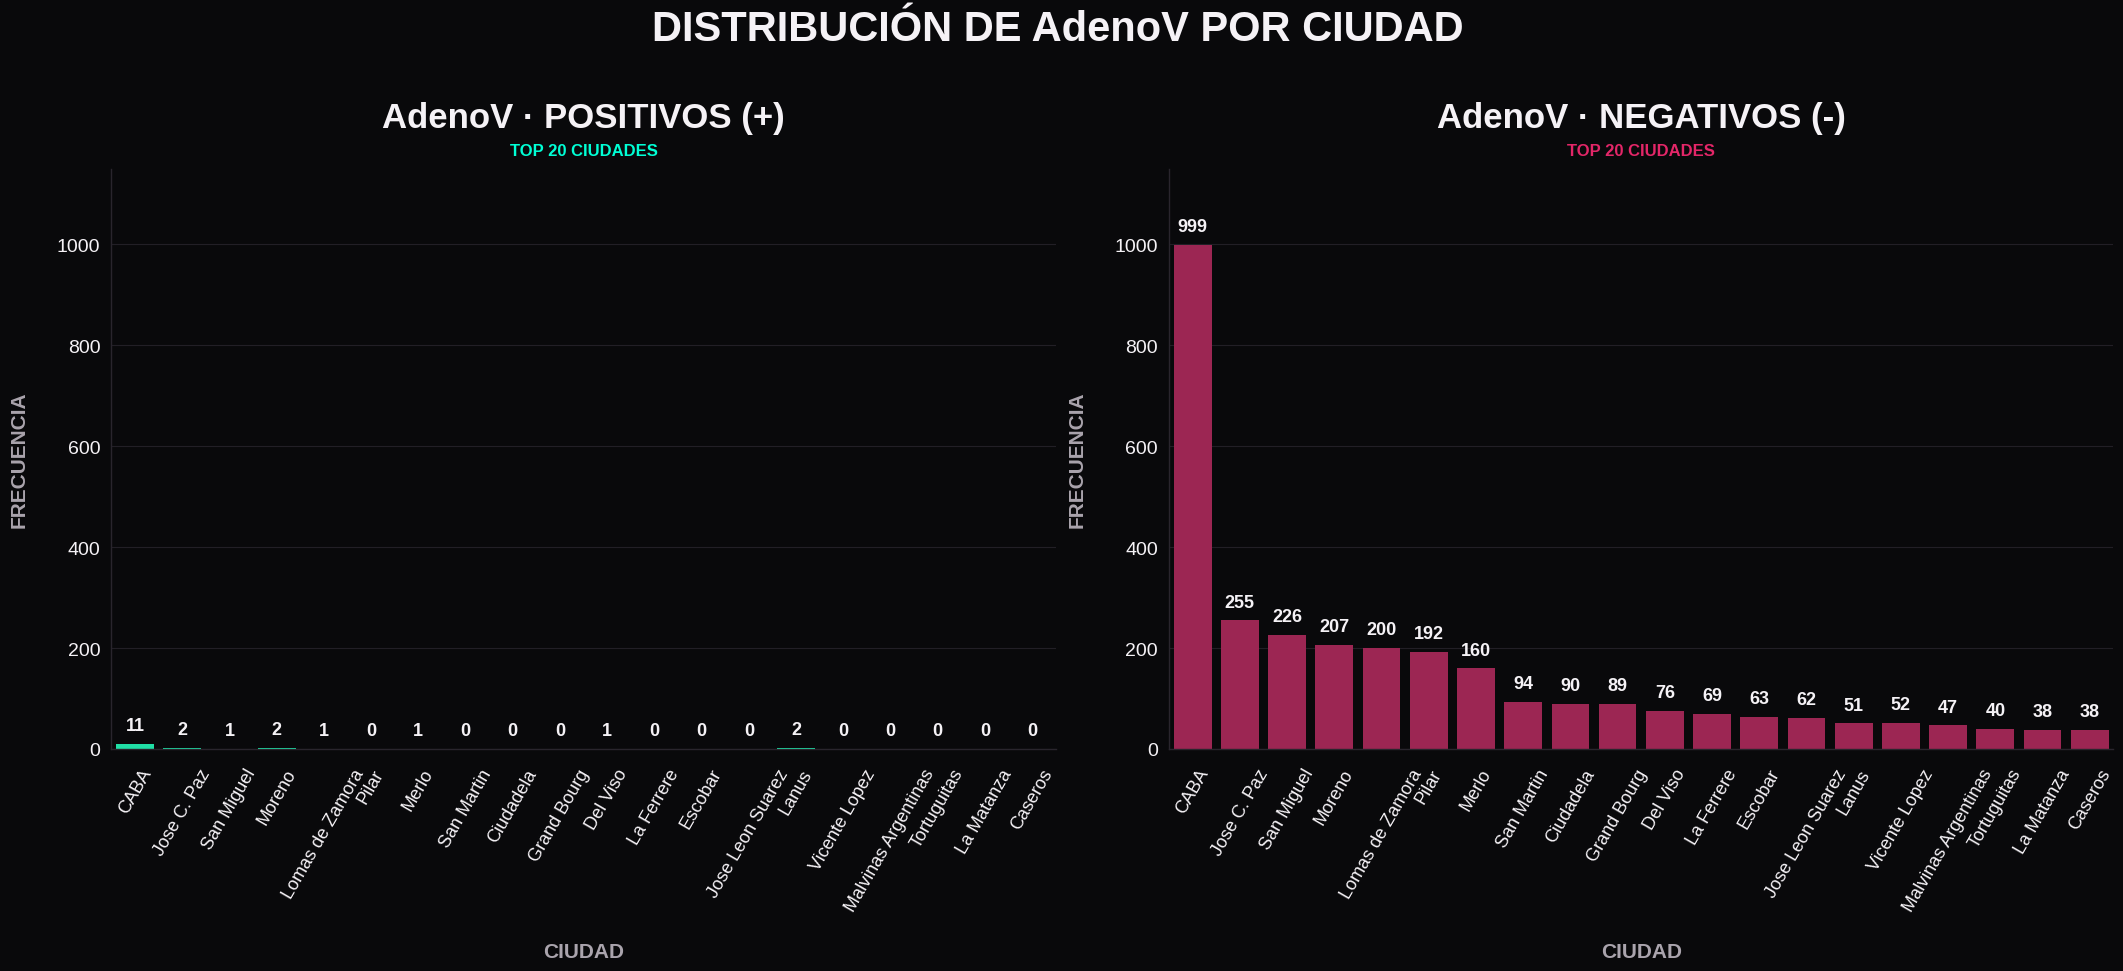

Imagen guardada en: distribucion_AdenoV_top20_ciudades.png


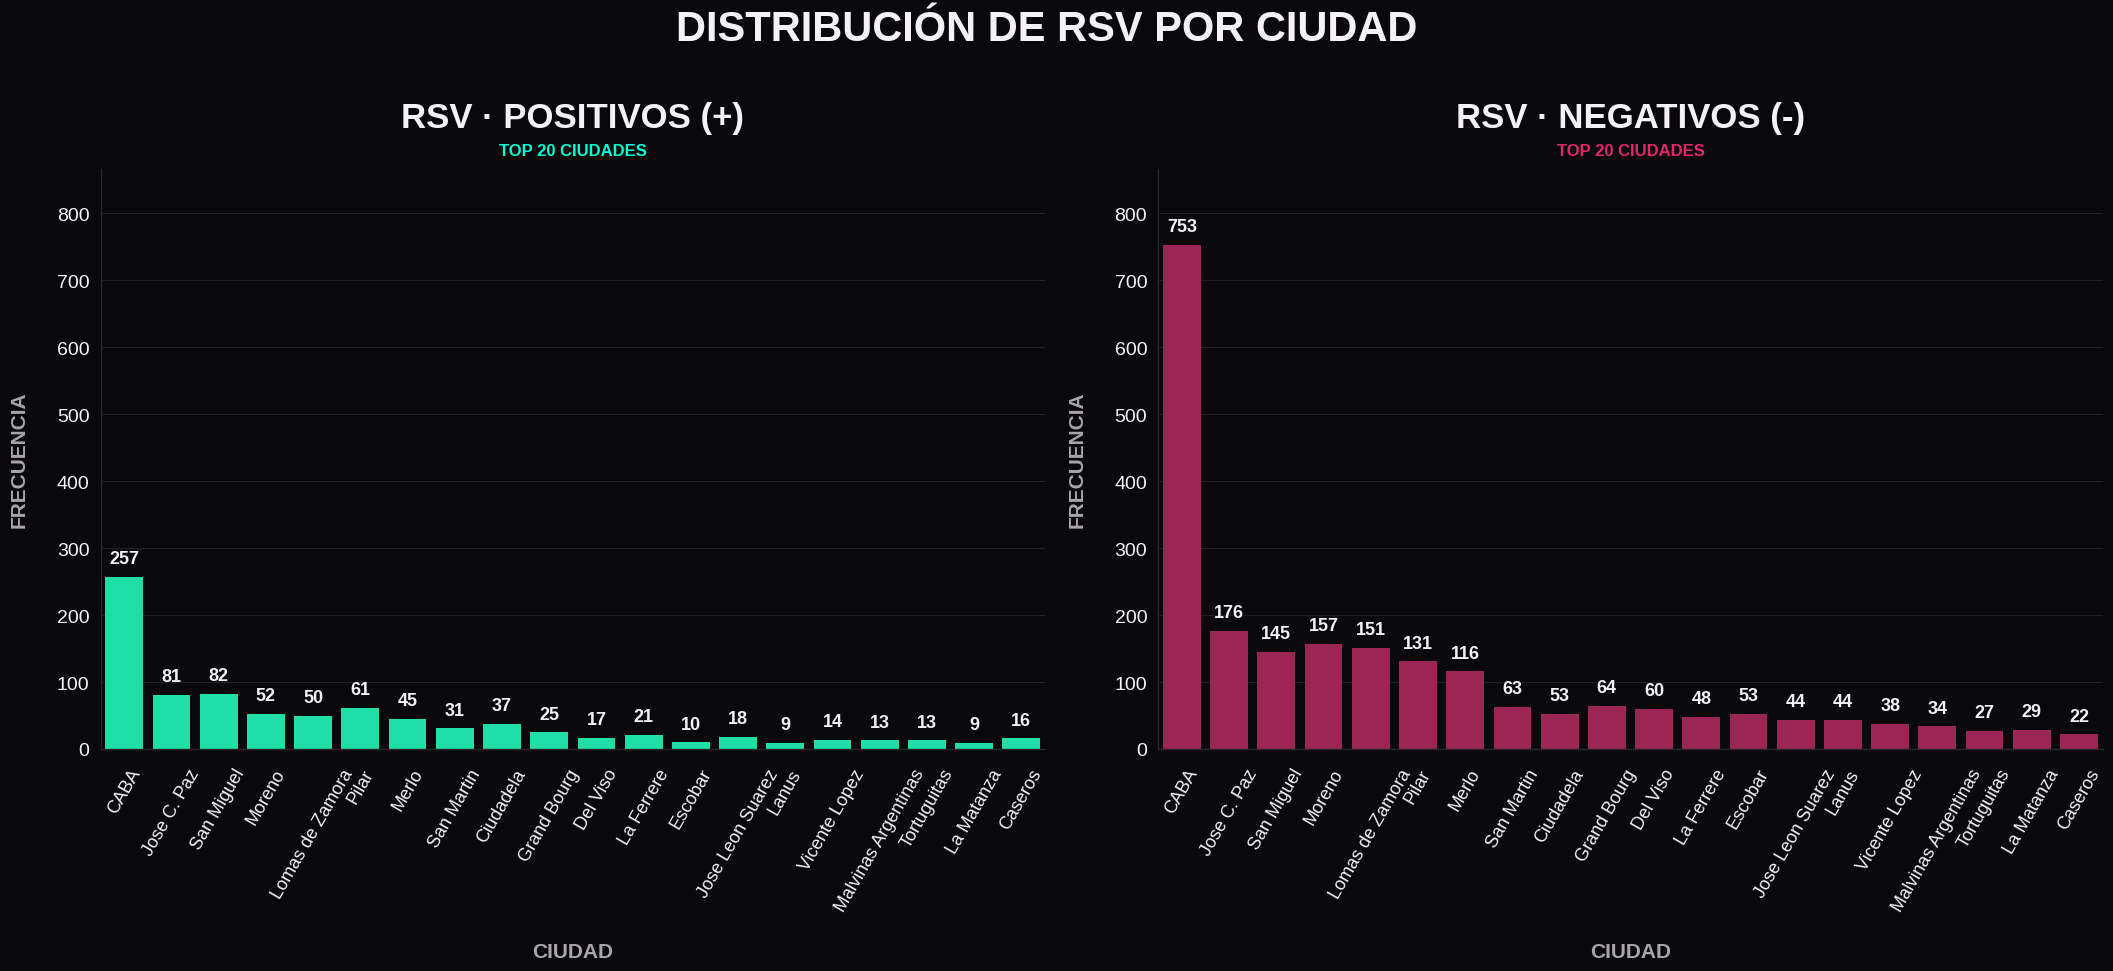

Imagen guardada en: distribucion_RSV_top20_ciudades.png


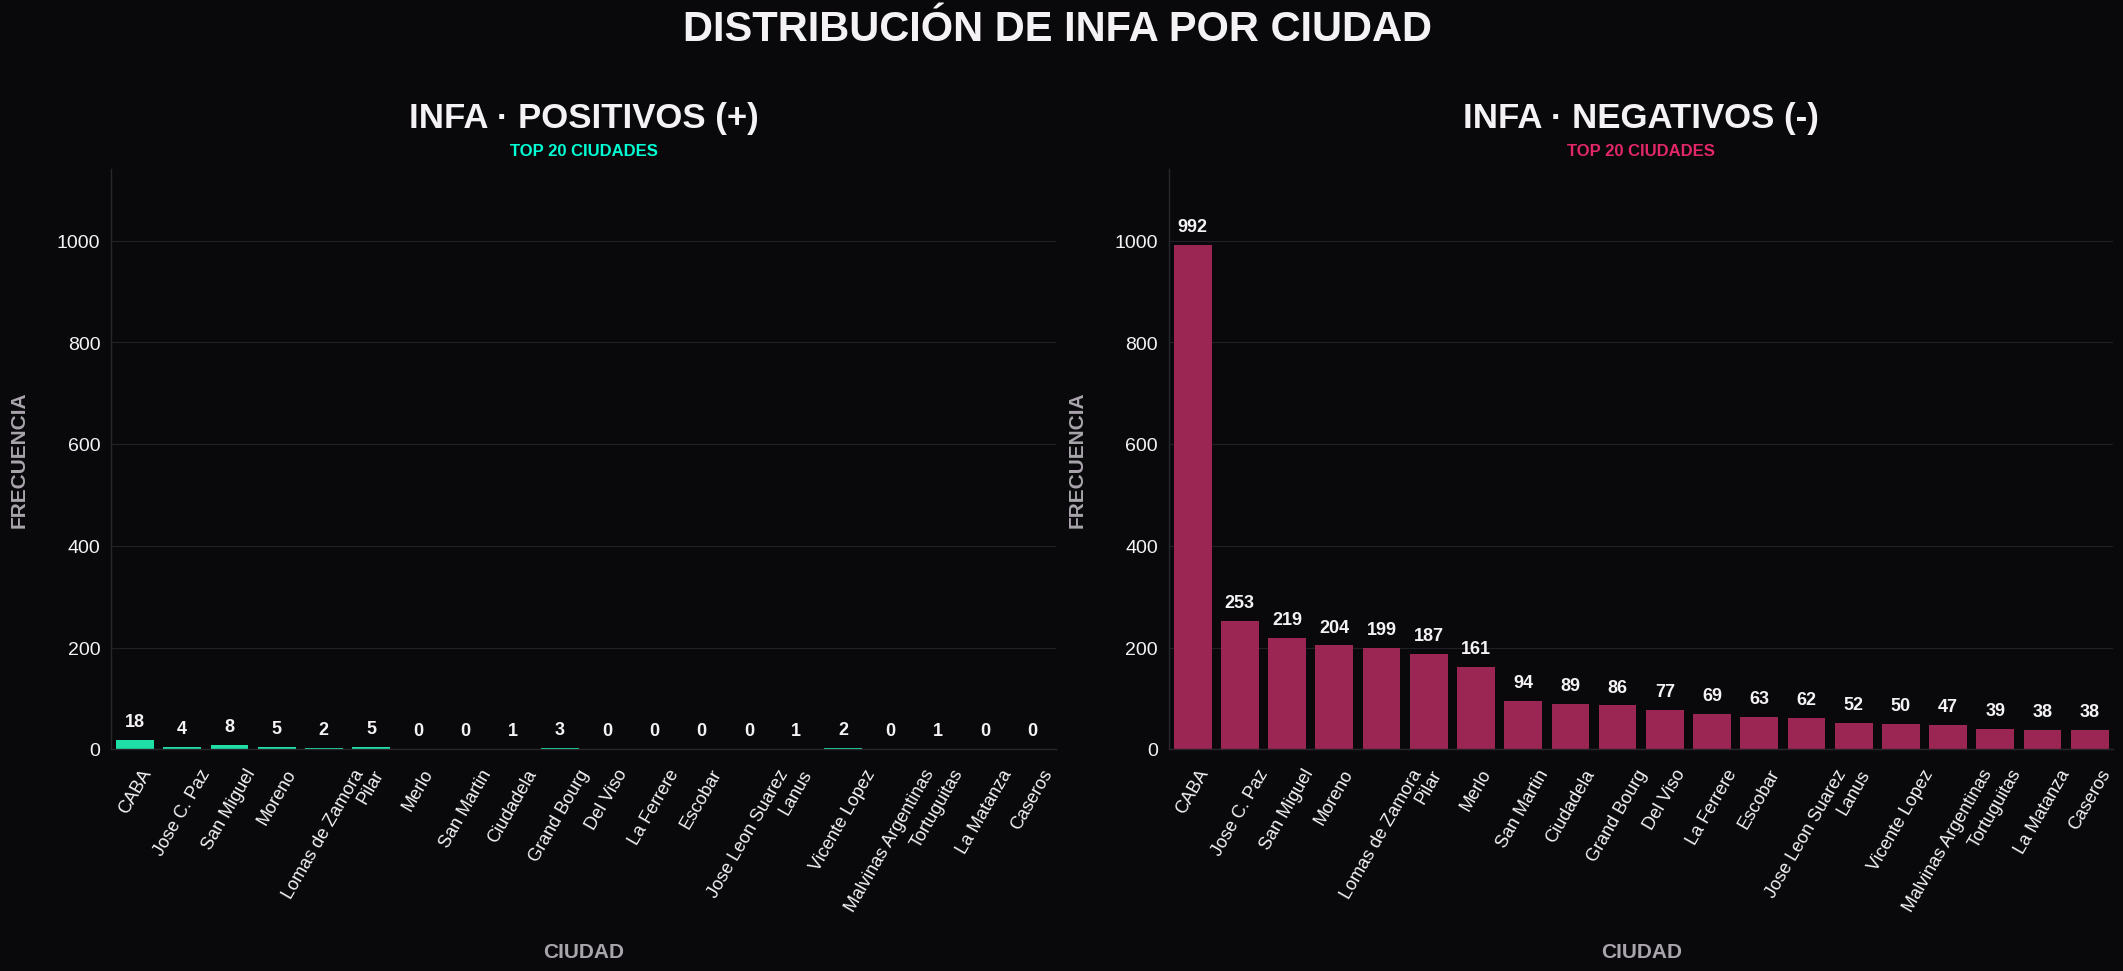

Imagen guardada en: distribucion_INFA_top20_ciudades.png


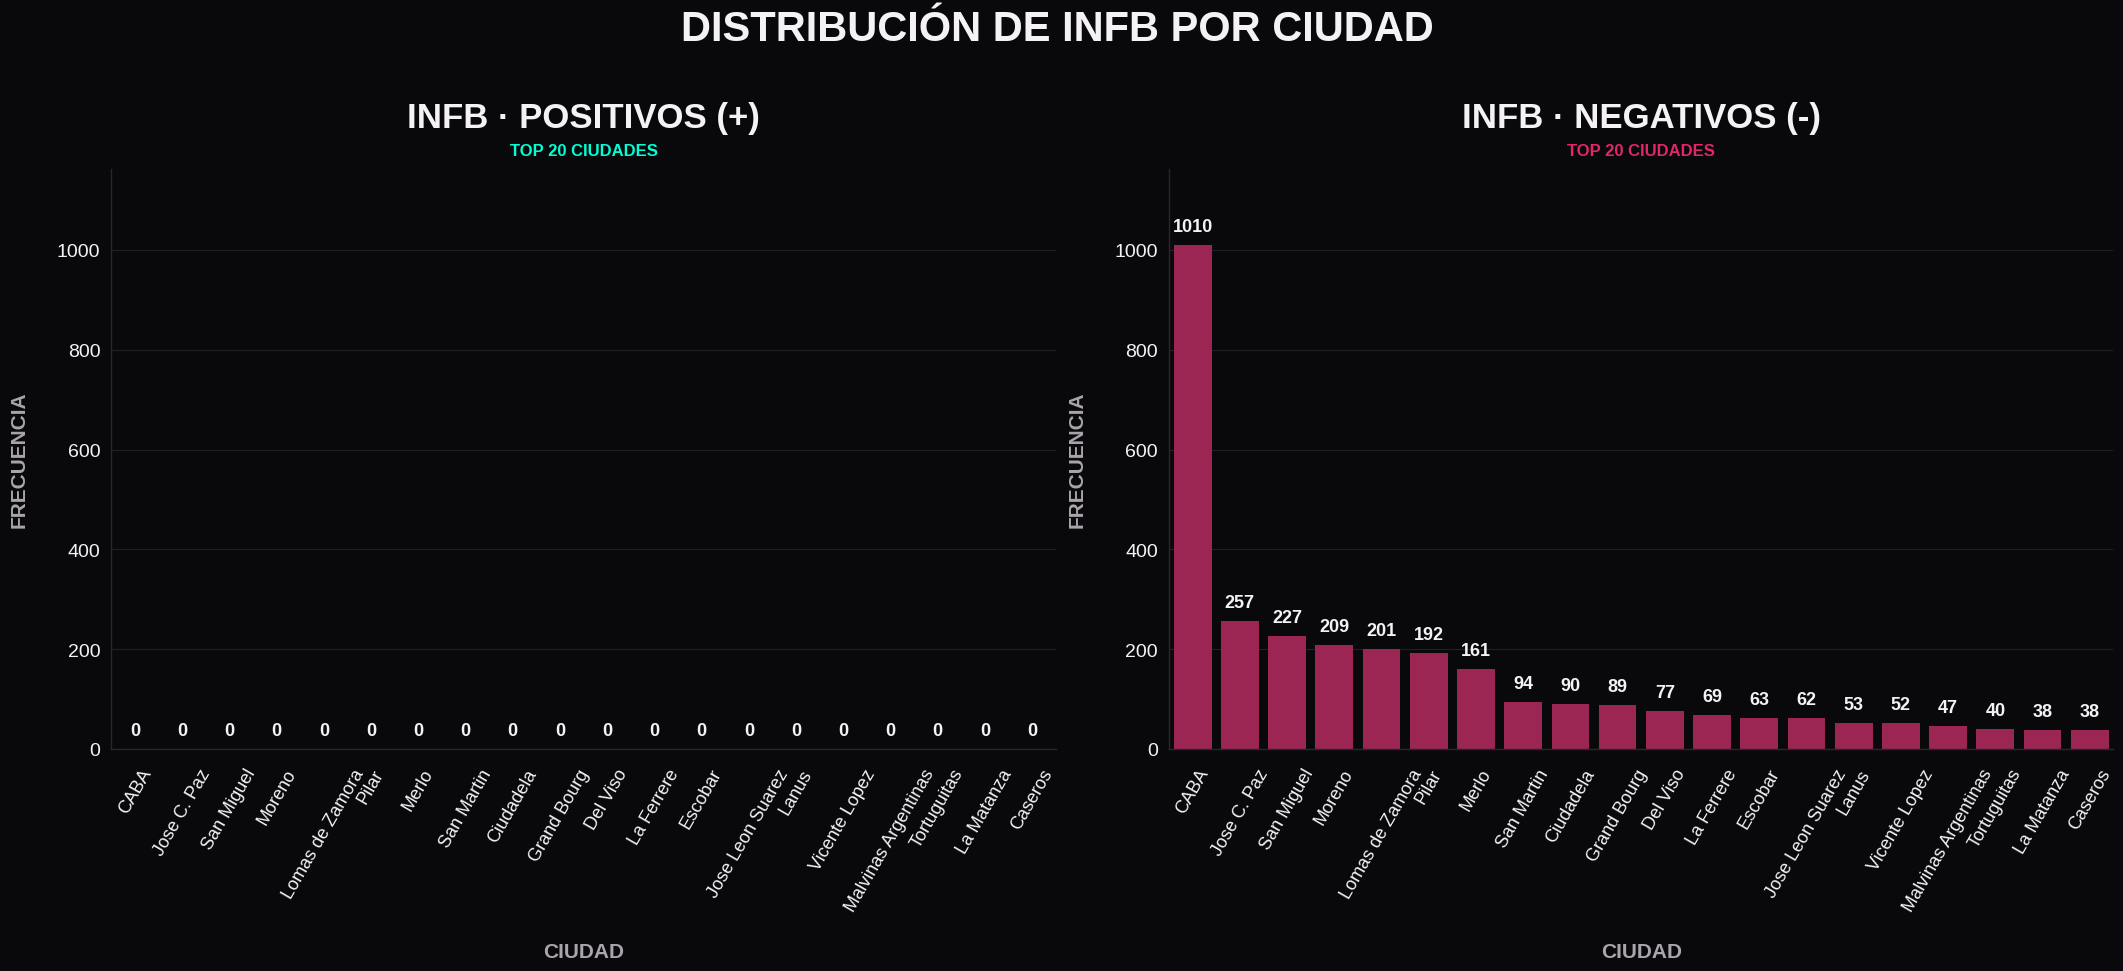

Imagen guardada en: distribucion_INFB_top20_ciudades.png


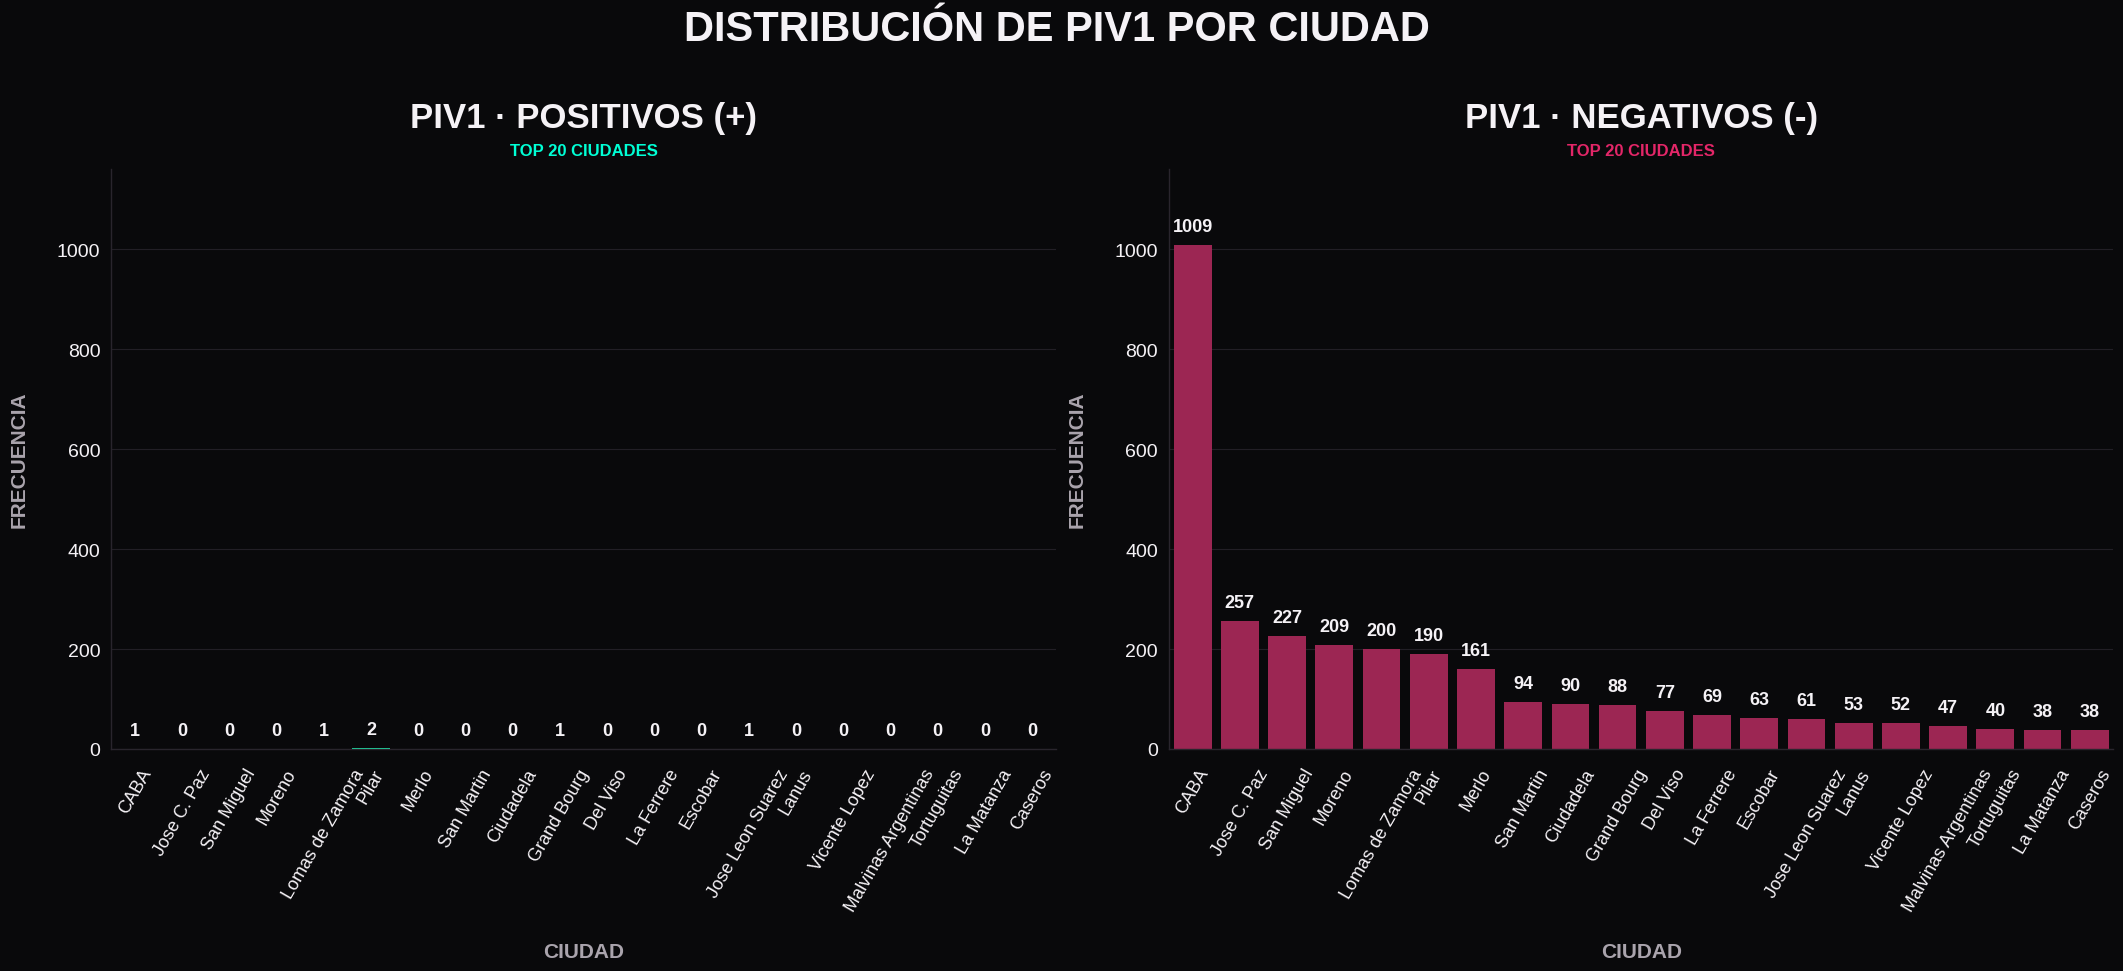

Imagen guardada en: distribucion_PIV1_top20_ciudades.png


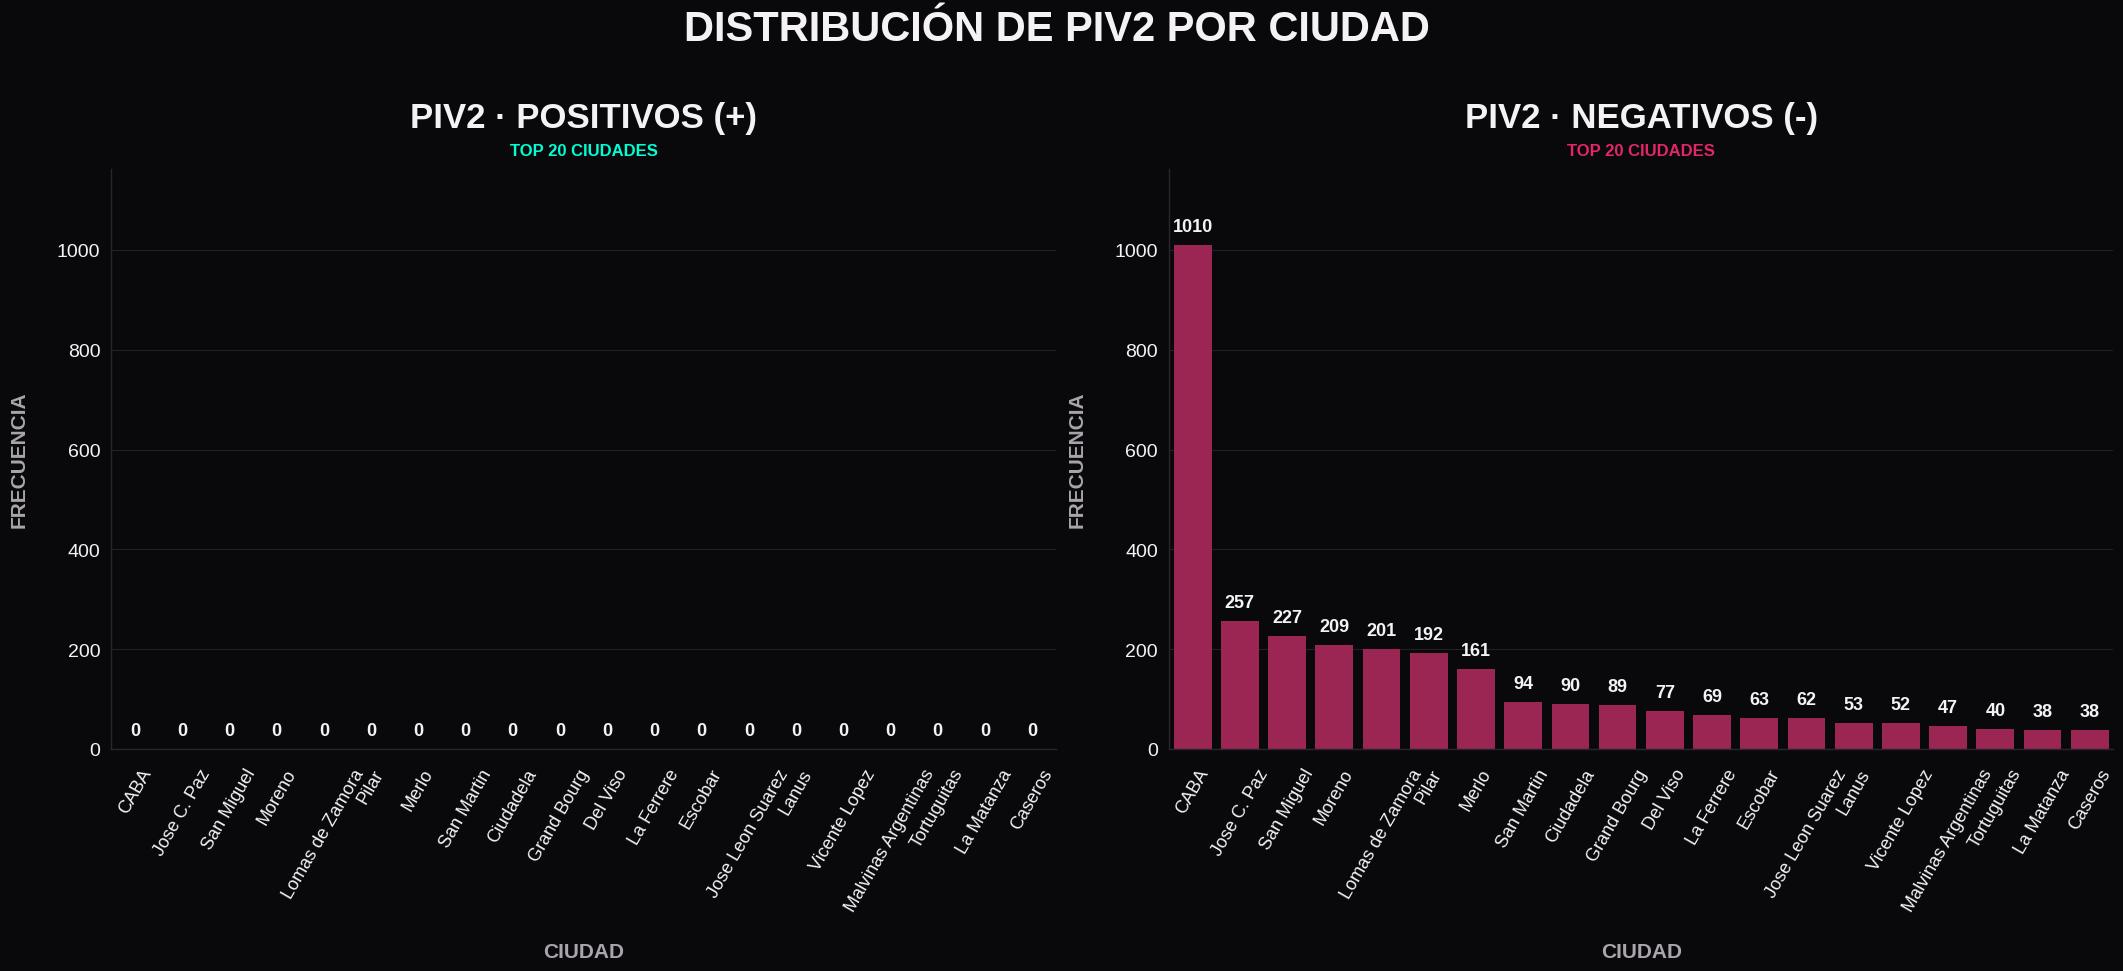

Imagen guardada en: distribucion_PIV2_top20_ciudades.png


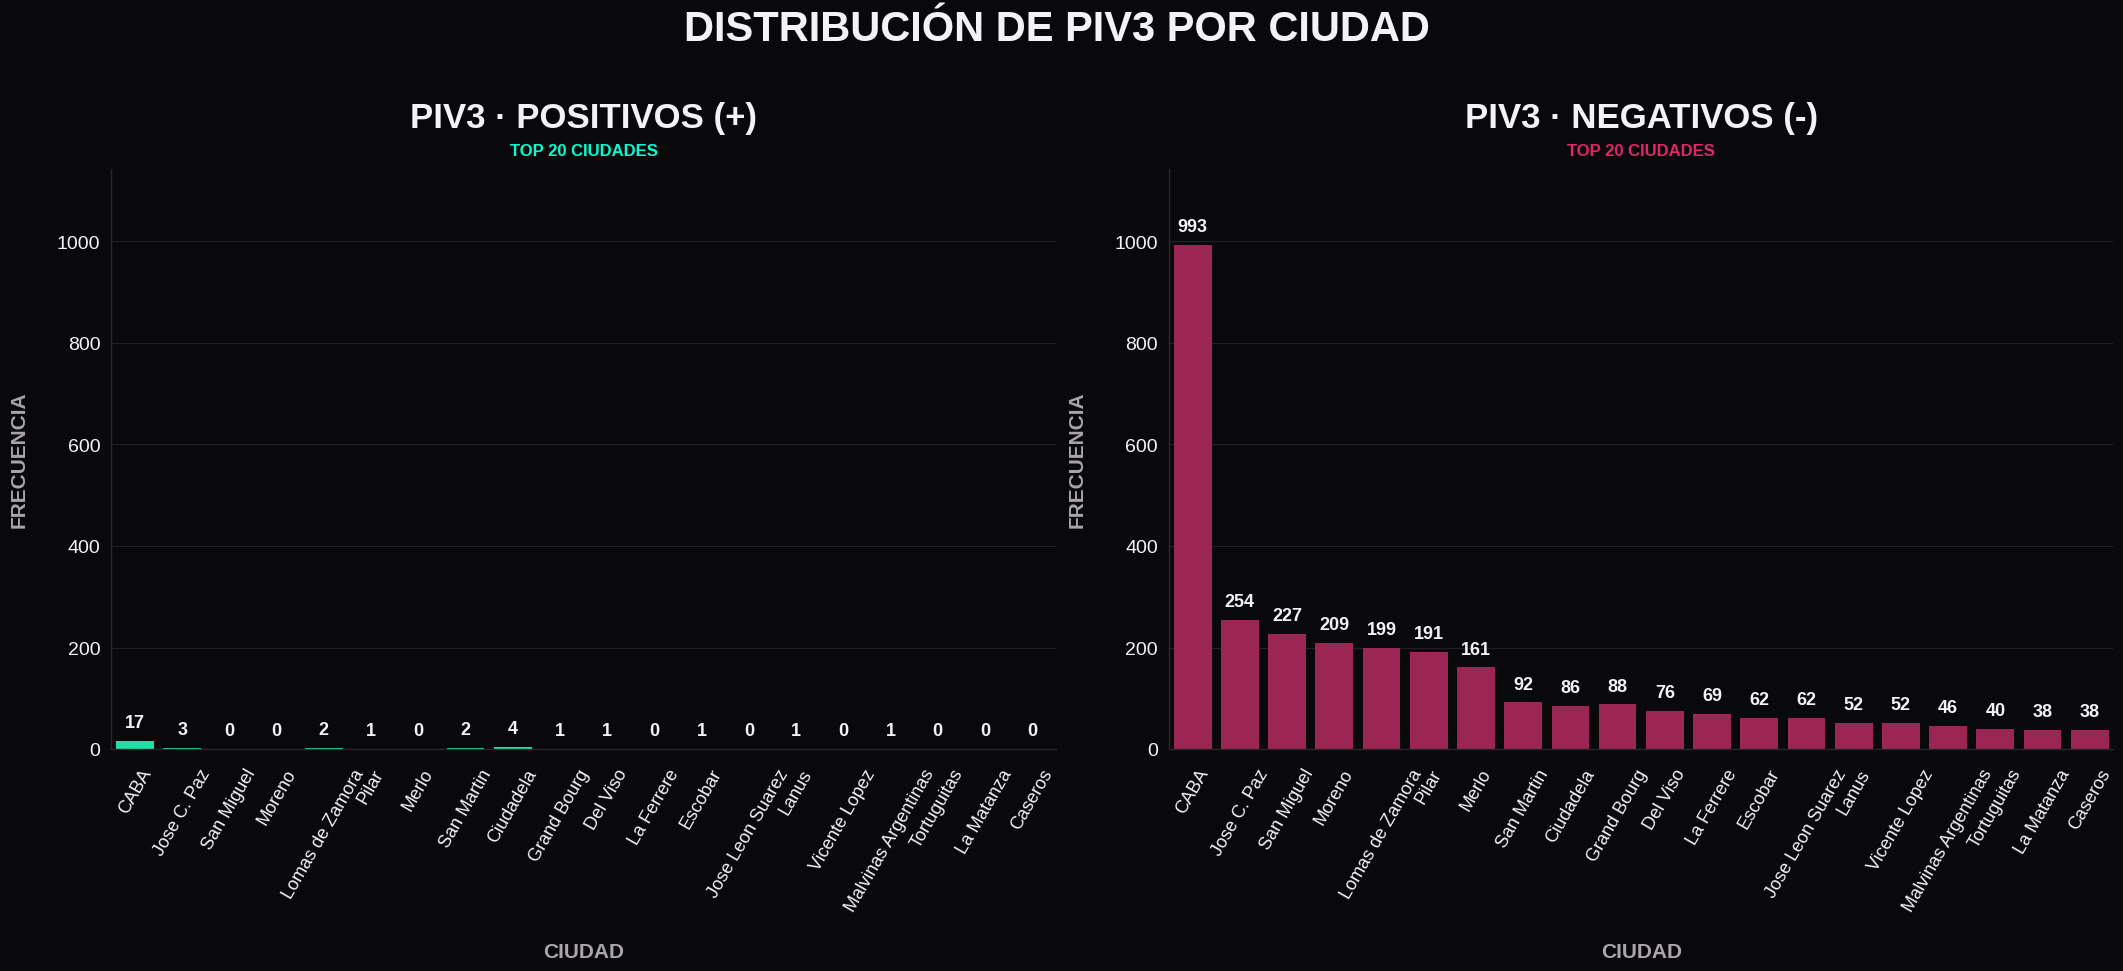

Imagen guardada en: distribucion_PIV3_top20_ciudades.png


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# CONFIGURACIÓN
# ============================================================

virus_columns = [
    'AdenoV',
    'RSV',
    'INFA',
    'INFB',
    'PIV1',
    'PIV2',
    'PIV3'
]

# Colores principales
BG_COLOR = '#09090B'          # Negro grafito
TEXT_COLOR = '#F5F2F6'        # Blanco suave
MUTED_COLOR = '#AAA4AD'       # Gris claro
GRID_COLOR = '#29252D'        # Gris oscuro

# Verde cian para positivos
GREEN_CYAN = '#00FFB3'
GREEN_GLOW = '#00FFD5'

# Rojo vino para negativos
WINE_NEON = '#B0124F'
WINE_GLOW = '#E32668'

# ============================================================
# IDENTIFICAR LAS 20 CIUDADES PRINCIPALES
# ============================================================

top_20_cities = (
    df_correccion_virus['Poblacion_limpia']
    .value_counts()
    .head(20)
    .index
    .tolist()
)

# Filtrar únicamente las ciudades principales
df_filtered_cities = df_correccion_virus[
    df_correccion_virus['Poblacion_limpia'].isin(top_20_cities)
].copy()

# ============================================================
# GENERAR UN GRÁFICO POR VIRUS
# ============================================================

for col in virus_columns:

    # Crear figura con dos paneles
    fig, axes = plt.subplots(
        1,
        2,
        figsize=(22, 10),
        facecolor=BG_COLOR
    )

    # Fondo de ambos paneles
    axes[0].set_facecolor(BG_COLOR)
    axes[1].set_facecolor(BG_COLOR)

    # ========================================================
    # DATOS POSITIVOS
    # ========================================================

    df_pos_virus = df_filtered_cities[
        df_filtered_cities[col] == '+'
    ]

    counts_pos = (
        df_pos_virus['Poblacion_limpia']
        .value_counts()
        .reindex(top_20_cities, fill_value=0)
    )

    # ========================================================
    # GRÁFICO POSITIVO
    # ========================================================

    sns.barplot(
        x=counts_pos.index,
        y=counts_pos.values,
        ax=axes[0],
        color=GREEN_CYAN,
        edgecolor='none'
    )

    # Título
    axes[0].set_title(
        f'{col} · POSITIVOS (+)',
        fontsize=25,
        fontweight='bold',
        color=TEXT_COLOR,
        fontfamily='sans-serif',
        loc='center',
        pad=30
    )

    # Subtítulo
    axes[0].text(
        0.5,
        1.025,
        'TOP 20 CIUDADES',
        transform=axes[0].transAxes,
        fontsize=12,
        fontweight='bold',
        color=GREEN_GLOW,
        ha='center'
    )

    # Etiquetas
    axes[0].set_xlabel(
        'CIUDAD',
        fontsize=15,
        fontweight='bold',
        color=MUTED_COLOR,
        labelpad=20
    )

    axes[0].set_ylabel(
        'FRECUENCIA',
        fontsize=15,
        fontweight='bold',
        color=MUTED_COLOR,
        labelpad=20
    )

    # Eje X
    axes[0].tick_params(
        axis='x',
        labelsize=13,
        colors=TEXT_COLOR,
        rotation=60,
        length=0,
        pad=12
    )

    # Eje Y
    axes[0].tick_params(
        axis='y',
        labelsize=14,
        colors=TEXT_COLOR,
        length=0,
        pad=8
    )

    # Cuadrícula
    axes[0].grid(
        axis='y',
        color=GRID_COLOR,
        linestyle='-',
        linewidth=0.8,
        alpha=0.8
    )

    axes[0].grid(axis='x', visible=False)
    axes[0].set_axisbelow(True)

    # Bordes
    axes[0].spines['top'].set_visible(False)
    axes[0].spines['right'].set_visible(False)

    axes[0].spines['left'].set_color(GRID_COLOR)
    axes[0].spines['bottom'].set_color(GRID_COLOR)

    # Valores sobre las barras
    for container in axes[0].containers:

        axes[0].bar_label(
            container,
            fmt='%d',
            fontsize=13,
            color=TEXT_COLOR,
            fontweight='bold',
            padding=7
        )

    # ========================================================
    # DATOS NEGATIVOS
    # ========================================================

    df_neg_virus = df_filtered_cities[
        df_filtered_cities[col] == '-'
    ]

    counts_neg = (
        df_neg_virus['Poblacion_limpia']
        .value_counts()
        .reindex(top_20_cities, fill_value=0)
    )

    # ========================================================
    # GRÁFICO NEGATIVO
    # ========================================================

    sns.barplot(
        x=counts_neg.index,
        y=counts_neg.values,
        ax=axes[1],
        color=WINE_NEON,
        edgecolor='none'
    )

    # Título
    axes[1].set_title(
        f'{col} · NEGATIVOS (-)',
        fontsize=25,
        fontweight='bold',
        color=TEXT_COLOR,
        fontfamily='sans-serif',
        loc='center',
        pad=30
    )

    # Subtítulo
    axes[1].text(
        0.5,
        1.025,
        'TOP 20 CIUDADES',
        transform=axes[1].transAxes,
        fontsize=12,
        fontweight='bold',
        color=WINE_GLOW,
        ha='center'
    )

    # Etiquetas
    axes[1].set_xlabel(
        'CIUDAD',
        fontsize=15,
        fontweight='bold',
        color=MUTED_COLOR,
        labelpad=20
    )

    axes[1].set_ylabel(
        'FRECUENCIA',
        fontsize=15,
        fontweight='bold',
        color=MUTED_COLOR,
        labelpad=20
    )

    # Eje X
    axes[1].tick_params(
        axis='x',
        labelsize=13,
        colors=TEXT_COLOR,
        rotation=60,
        length=0,
        pad=12
    )

    # Eje Y
    axes[1].tick_params(
        axis='y',
        labelsize=14,
        colors=TEXT_COLOR,
        length=0,
        pad=8
    )

    # Cuadrícula
    axes[1].grid(
        axis='y',
        color=GRID_COLOR,
        linestyle='-',
        linewidth=0.8,
        alpha=0.8
    )

    axes[1].grid(axis='x', visible=False)
    axes[1].set_axisbelow(True)

    # Bordes
    axes[1].spines['top'].set_visible(False)
    axes[1].spines['right'].set_visible(False)

    axes[1].spines['left'].set_color(GRID_COLOR)
    axes[1].spines['bottom'].set_color(GRID_COLOR)

    # Valores sobre las barras
    for container in axes[1].containers:

        axes[1].bar_label(
            container,
            fmt='%d',
            fontsize=13,
            color=TEXT_COLOR,
            fontweight='bold',
            padding=7
        )

    # ========================================================
    # TÍTULO GENERAL
    # ========================================================

    fig.suptitle(
        f'DISTRIBUCIÓN DE {col} POR CIUDAD',
        fontsize=30,
        fontweight='bold',
        color=TEXT_COLOR,
        y=1.02
    )

    # ========================================================
    # AJUSTE DE ESCALA
    # ========================================================

    # Obtener el máximo de ambos gráficos
    max_value = max(
        counts_pos.max(),
        counts_neg.max()
    )

    # Dejar espacio para las etiquetas
    axes[0].set_ylim(0, max_value * 1.15)
    axes[1].set_ylim(0, max_value * 1.15)

    # ========================================================
    # AJUSTE FINAL
    # ========================================================

    plt.subplots_adjust(
        left=0.07,
        right=0.98,
        top=0.86,
        bottom=0.28,
        wspace=0.12
    )

    # ========================================================
    # GUARDAR COMO PNG DE ALTA RESOLUCIÓN
    # ========================================================

    ruta_png = (
        f'distribucion_{col}_top20_ciudades.png'
    )

    fig.savefig(
        ruta_png,
        dpi=300,
        bbox_inches='tight',
        facecolor=fig.get_facecolor(),
        edgecolor='none'
    )

    # Mostrar el gráfico
    plt.show()

    print(f'Imagen guardada en: {ruta_png}')

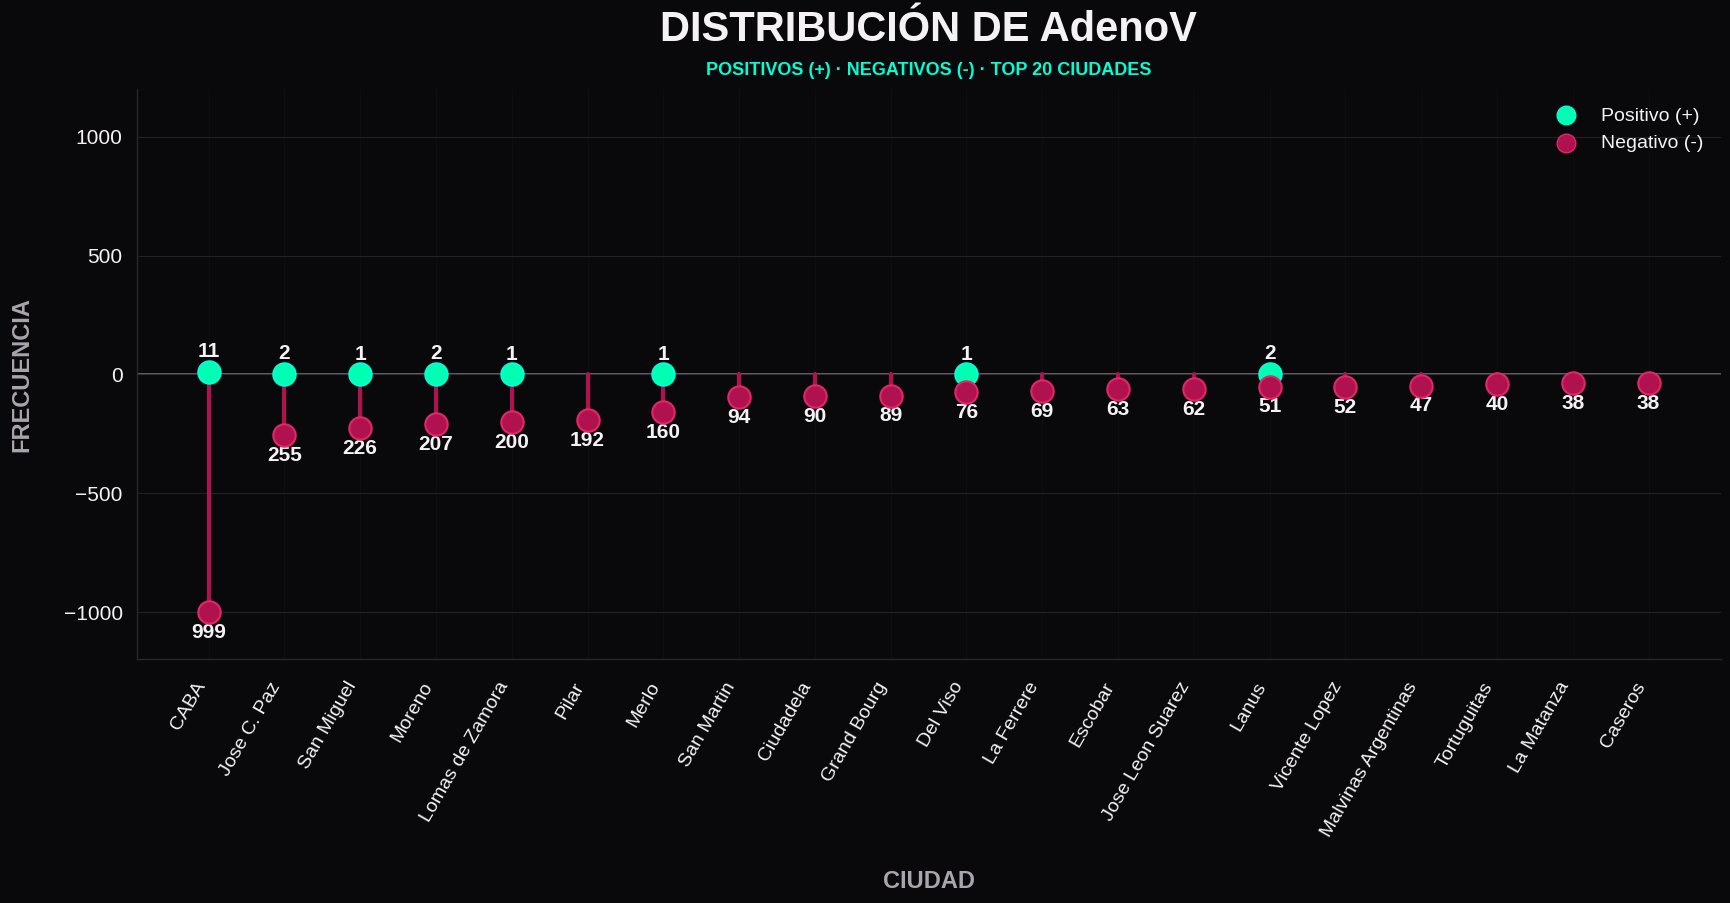

Imagen guardada en: distribucion_AdenoV_top20_ciudades_lollipop_neon.png


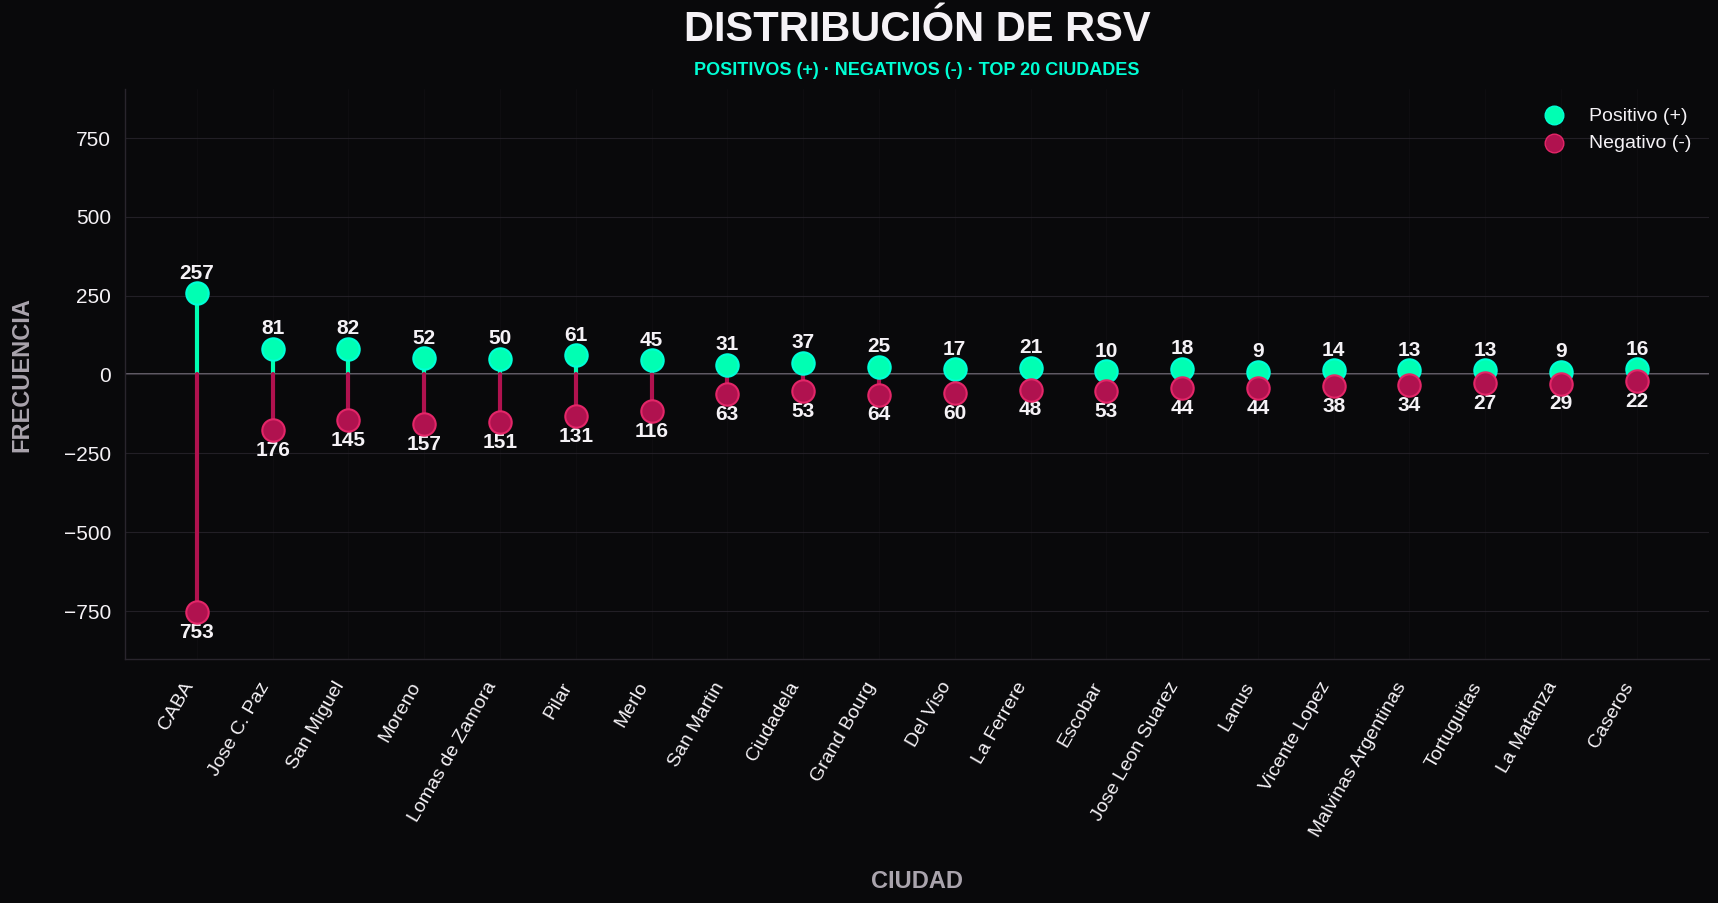

Imagen guardada en: distribucion_RSV_top20_ciudades_lollipop_neon.png


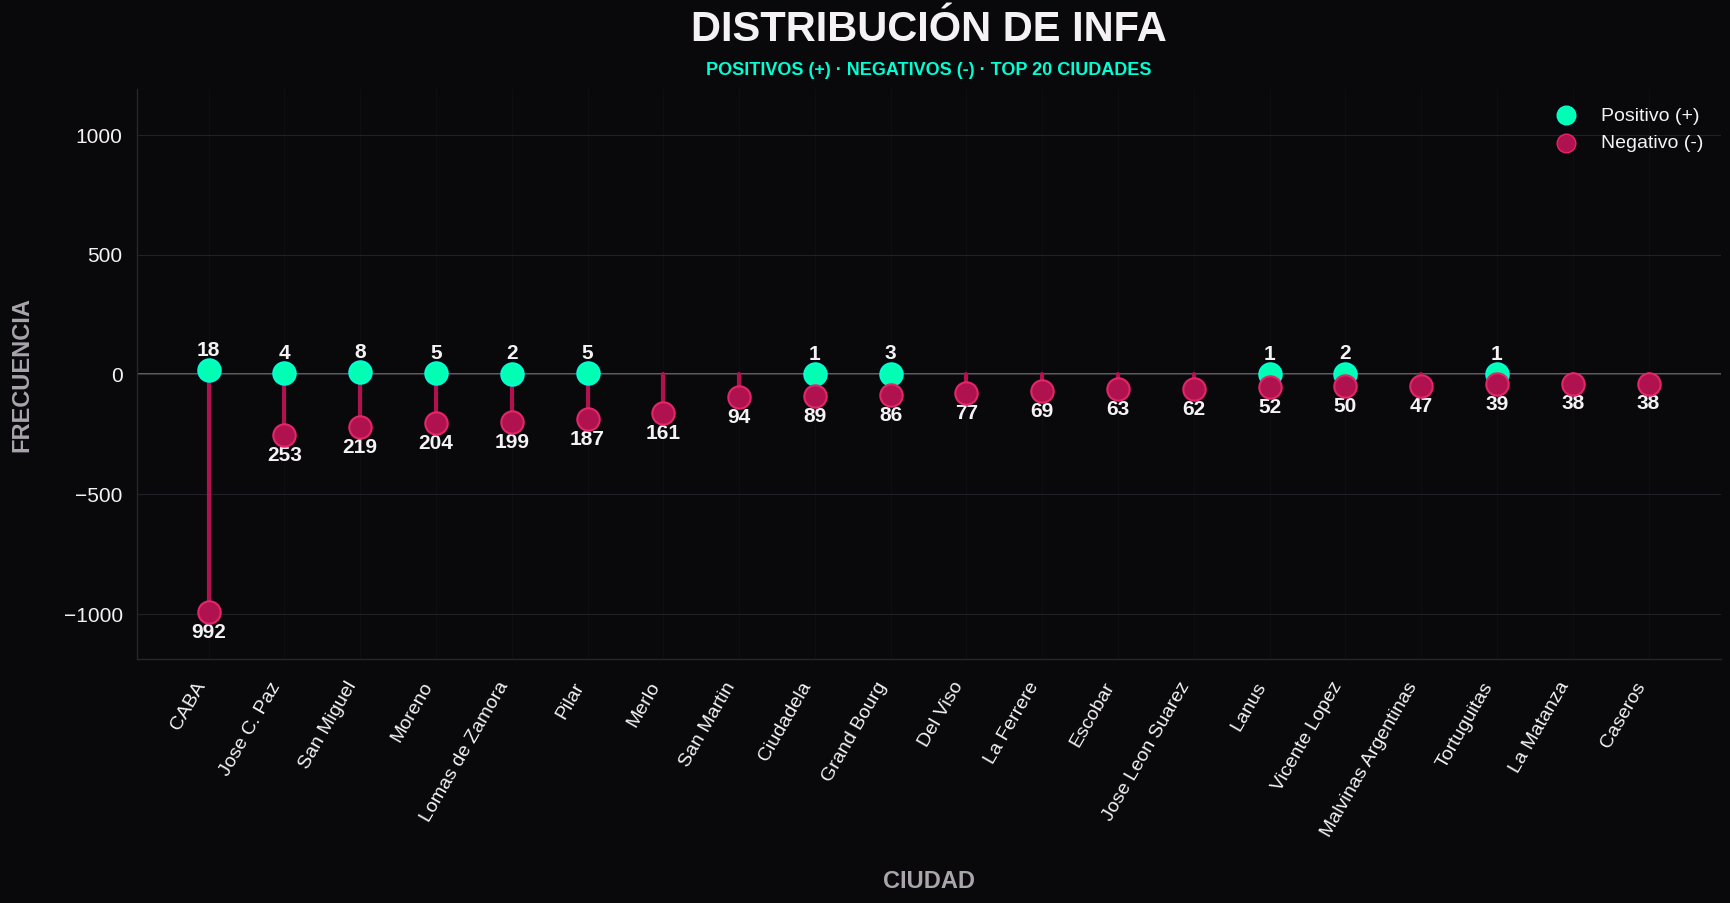

Imagen guardada en: distribucion_INFA_top20_ciudades_lollipop_neon.png


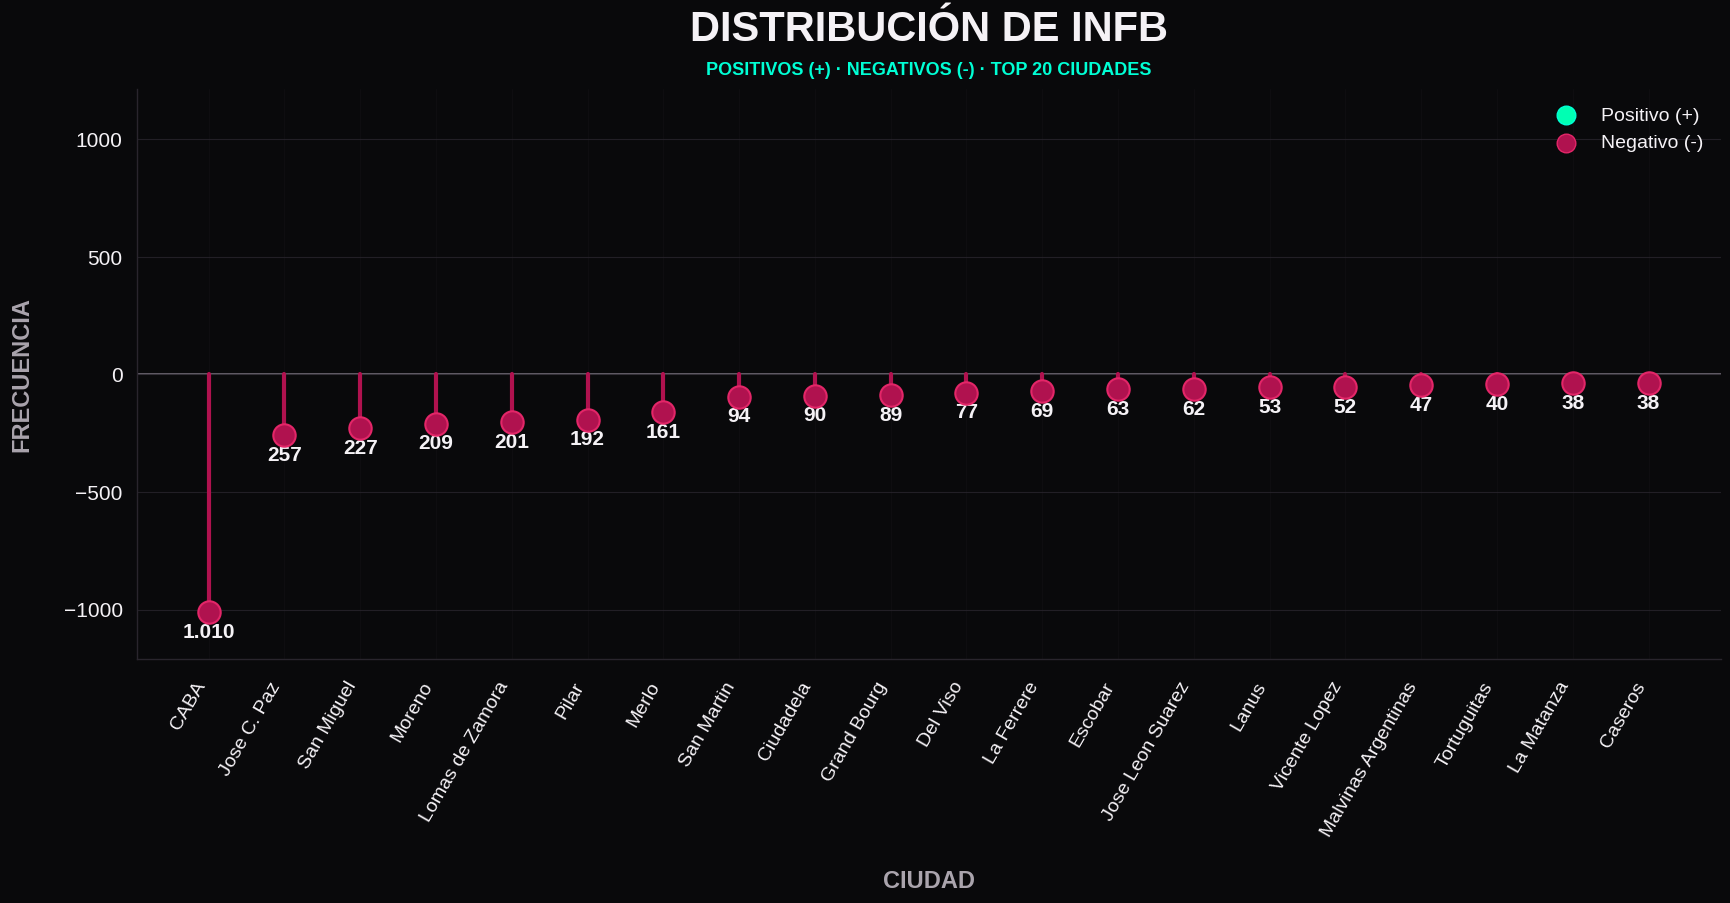

Imagen guardada en: distribucion_INFB_top20_ciudades_lollipop_neon.png


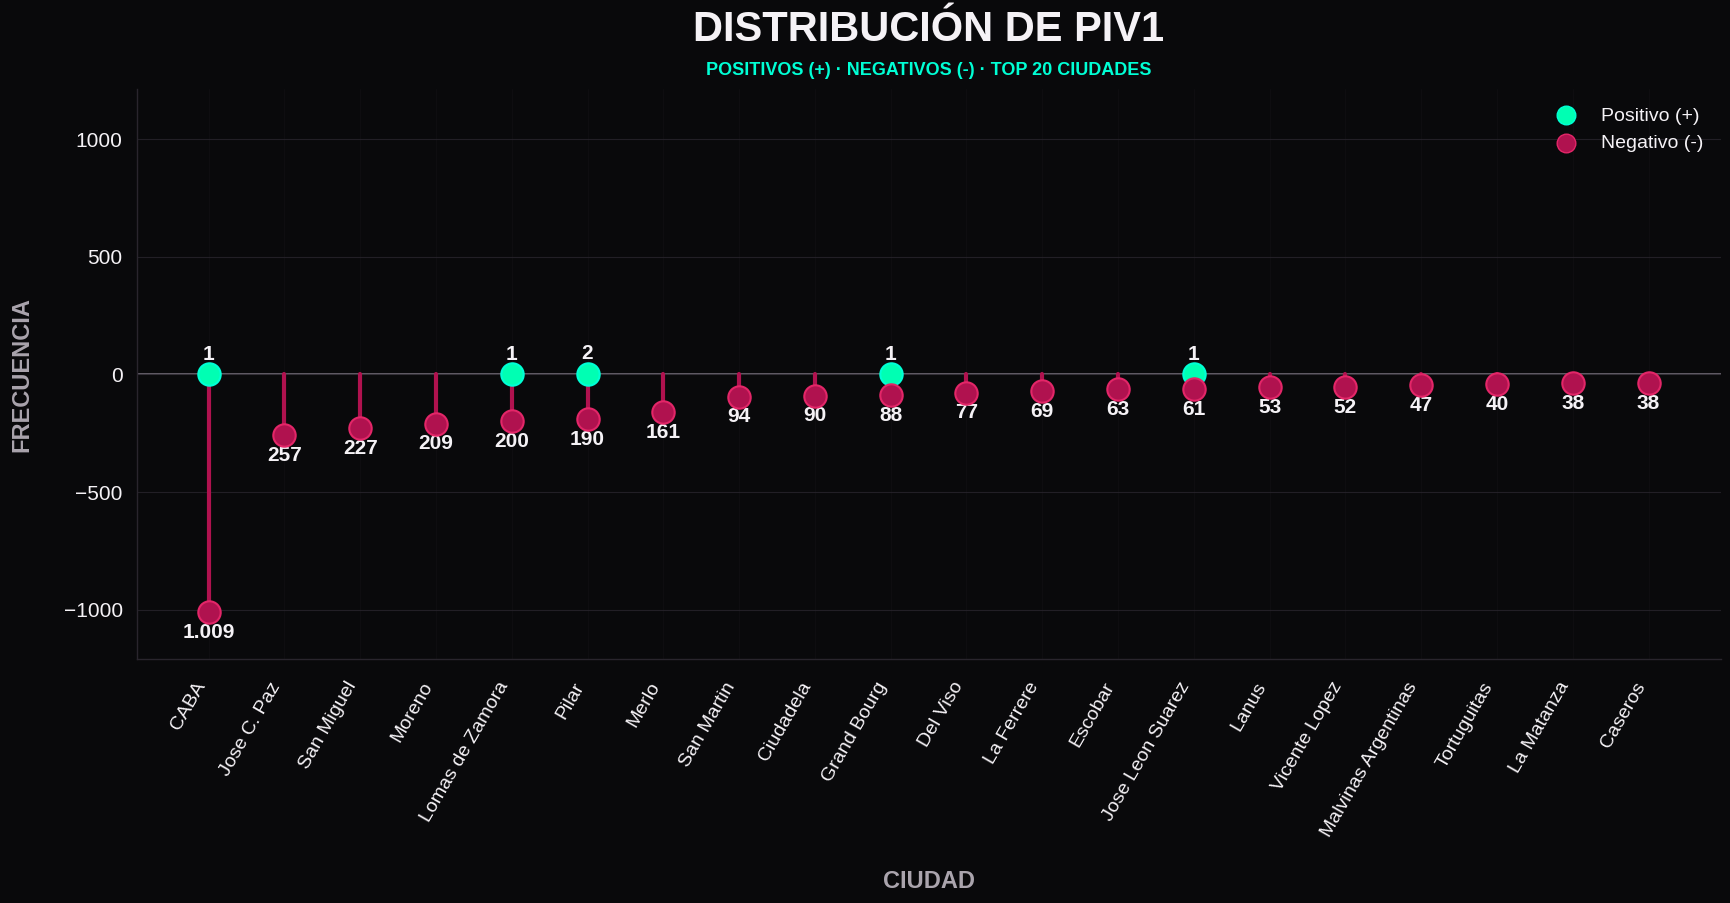

Imagen guardada en: distribucion_PIV1_top20_ciudades_lollipop_neon.png


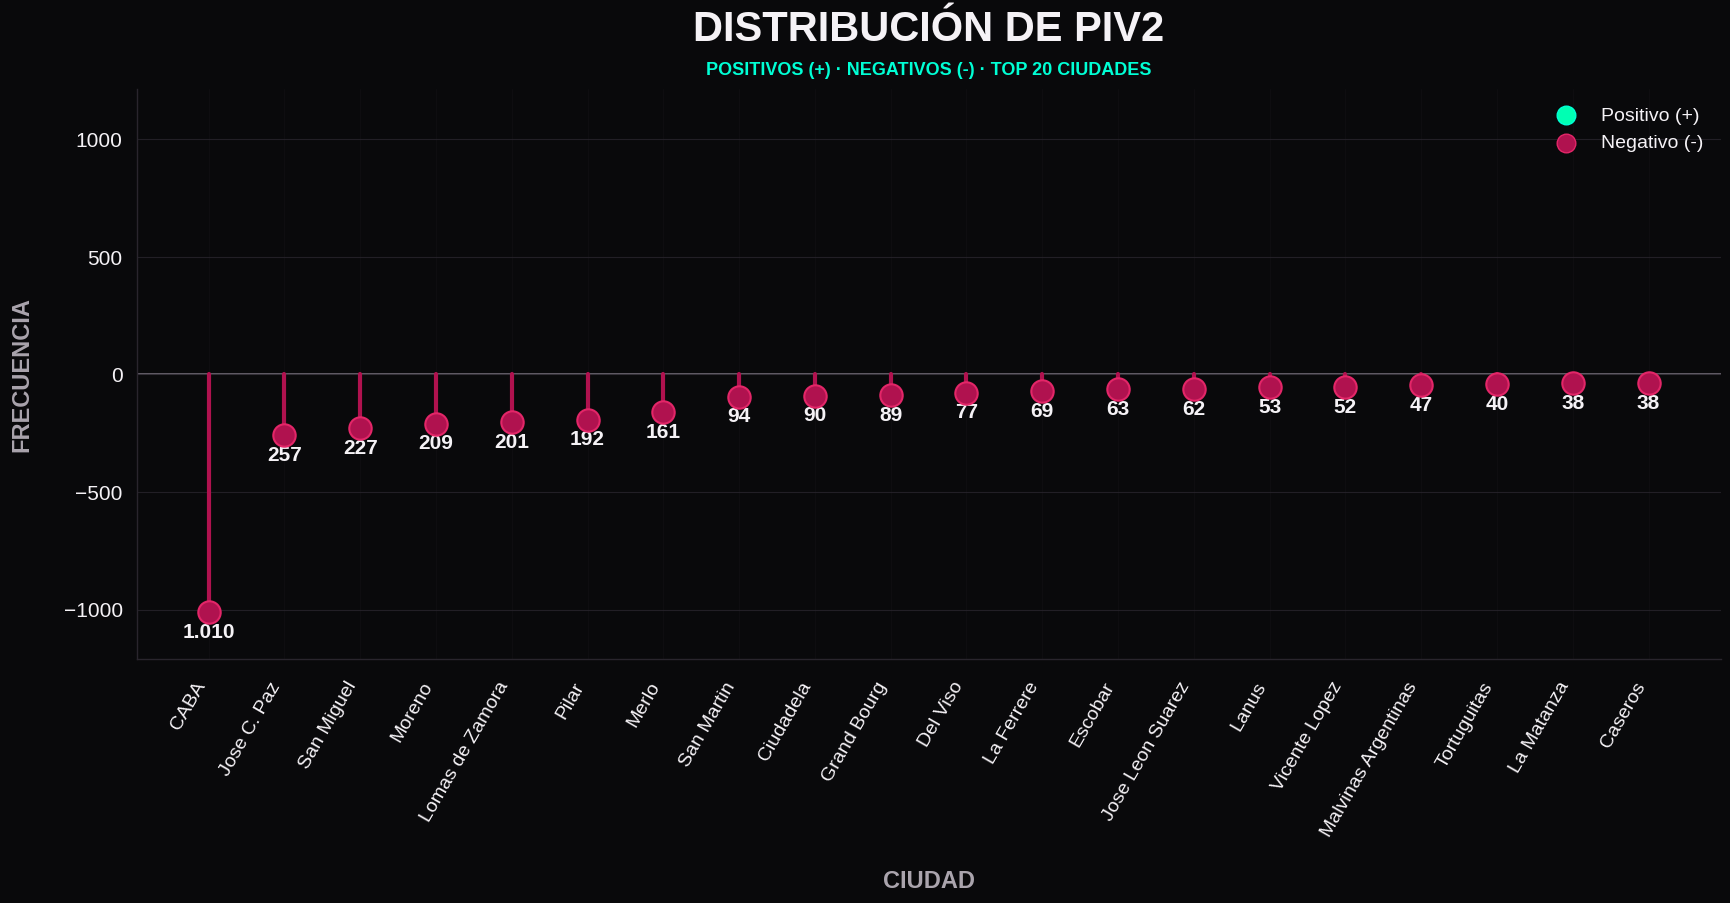

Imagen guardada en: distribucion_PIV2_top20_ciudades_lollipop_neon.png


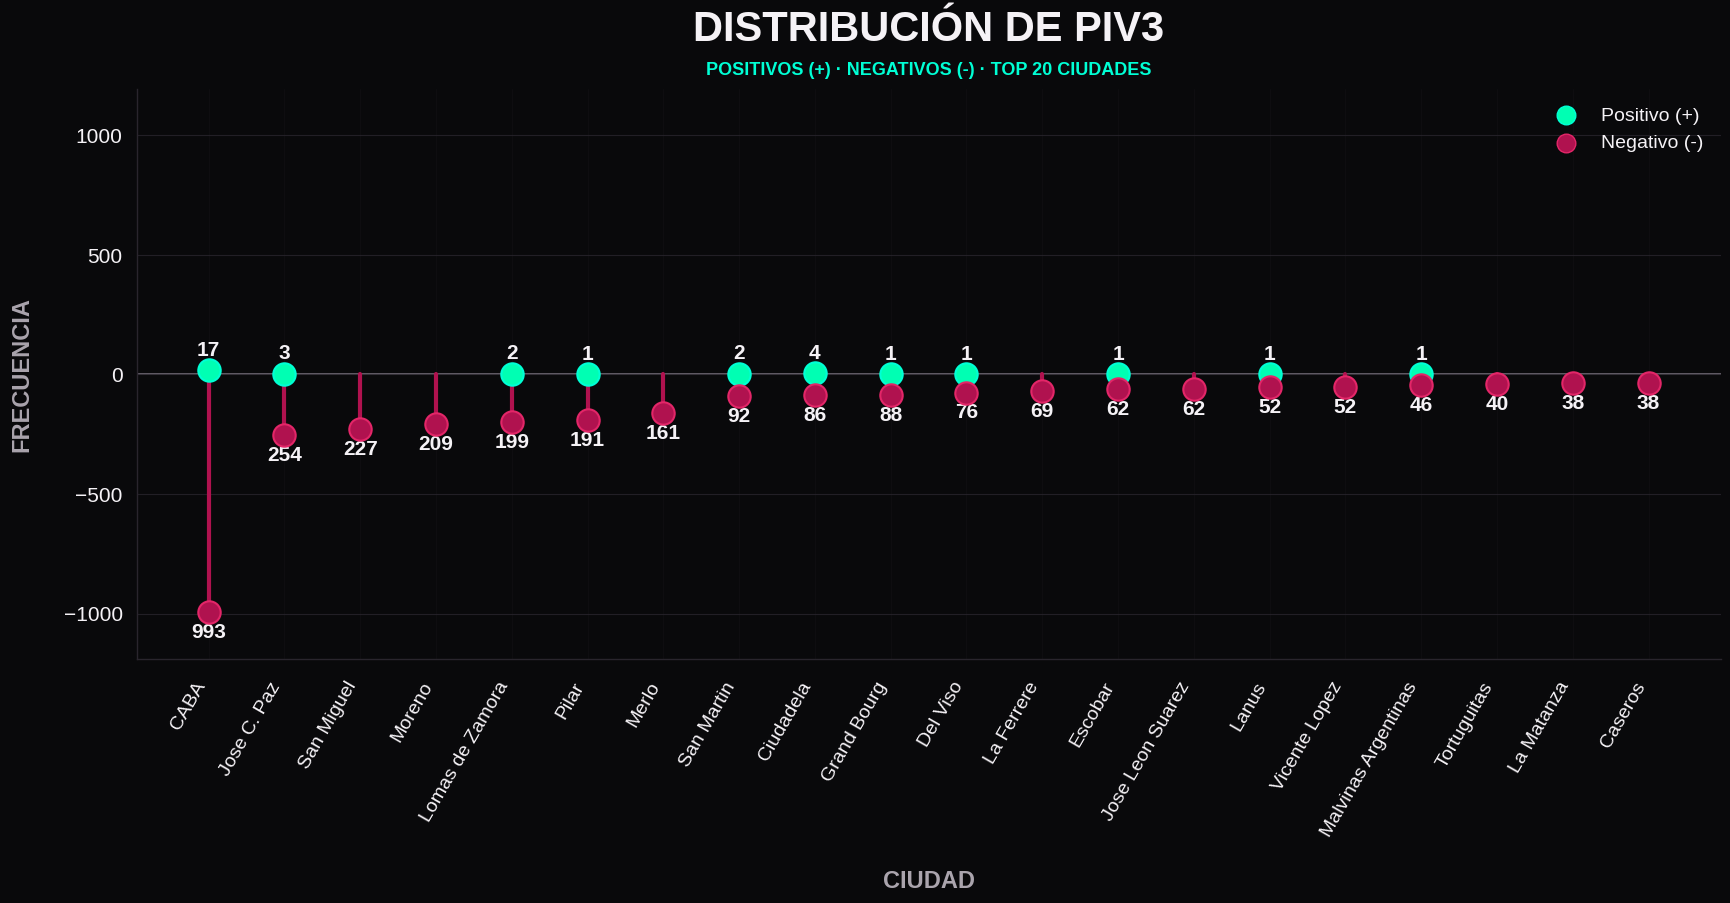

Imagen guardada en: distribucion_PIV3_top20_ciudades_lollipop_neon.png


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ============================================================
# VIRUS A ANALIZAR
# ============================================================

virus_columns = [
    'AdenoV',
    'RSV',
    'INFA',
    'INFB',
    'PIV1',
    'PIV2',
    'PIV3'
]

# ============================================================
# PALETA DE COLORES
# ============================================================

BG_COLOR = '#09090B'          # Negro grafito
TEXT_COLOR = '#F5F2F6'        # Blanco suave
MUTED_COLOR = '#AAA4AD'       # Gris claro
GRID_COLOR = '#29252D'        # Gris oscuro

# Positivos
GREEN_CYAN = '#00FFB3'        # Verde cian neón
GREEN_GLOW = '#00FFD5'        # Verde cian brillante

# Negativos
WINE_NEON = '#B0124F'         # Rojo vino neón
WINE_GLOW = '#E32668'         # Rojo vino brillante

# ============================================================
# IDENTIFICAR LAS 20 CIUDADES PRINCIPALES
# ============================================================

top_20_cities = (
    df_correccion_virus['Poblacion_limpia']
    .value_counts()
    .head(20)
    .index
    .tolist()
)

# Filtrar únicamente las ciudades principales
df_filtered_cities = df_correccion_virus[
    df_correccion_virus['Poblacion_limpia'].isin(top_20_cities)
].copy()

# ============================================================
# GENERAR UN GRÁFICO POR VIRUS
# ============================================================

for col in virus_columns:

    # ========================================================
    # CREAR LA FIGURA
    # ========================================================

    fig, ax = plt.subplots(
        figsize=(18, 10),
        facecolor=BG_COLOR
    )

    ax.set_facecolor(BG_COLOR)

    # ========================================================
    # PREPARAR LOS DATOS POSITIVOS
    # ========================================================

    df_pos_virus = df_filtered_cities[
        df_filtered_cities[col] == '+'
    ]

    counts_pos = (
        df_pos_virus['Poblacion_limpia']
        .value_counts()
        .reindex(top_20_cities, fill_value=0)
    )

    # ========================================================
    # PREPARAR LOS DATOS NEGATIVOS
    # ========================================================

    df_neg_virus = df_filtered_cities[
        df_filtered_cities[col] == '-'
    ]

    counts_neg = (
        df_neg_virus['Poblacion_limpia']
        .value_counts()
        .reindex(top_20_cities, fill_value=0)
    )

    # ========================================================
    # FRECUENCIA MÁXIMA
    # ========================================================

    max_total_freq = max(
        counts_pos.max(),
        counts_neg.max()
    )

    if max_total_freq == 0:
        max_total_freq = 1

    # ========================================================
    # POSICIONES EN EL EJE X
    # ========================================================

    x_positions = np.arange(
        len(top_20_cities)
    )

    # ========================================================
    # DIBUJAR LOLLIPOPS
    # ========================================================

    for j, city in enumerate(top_20_cities):

        pos_val = counts_pos.get(city, 0)
        neg_val = counts_neg.get(city, 0)

        # ----------------------------------------------------
        # CASOS POSITIVOS
        # ----------------------------------------------------

        if pos_val > 0:

            # Tallo
            ax.plot(
                [x_positions[j], x_positions[j]],
                [0, pos_val],
                color=GREEN_CYAN,
                linewidth=3,
                zorder=1
            )

            # Punto
            ax.scatter(
                x_positions[j],
                pos_val,
                color=GREEN_CYAN,
                edgecolor=GREEN_GLOW,
                linewidth=1.5,
                s=260,
                zorder=5
            )

            # Valor
            ax.text(
                x_positions[j],
                pos_val + (max_total_freq * 0.045),
                f'{int(pos_val):,}'.replace(',', '.'),
                ha='center',
                va='bottom',
                fontsize=15,
                color=TEXT_COLOR,
                fontweight='bold'
            )

        # ----------------------------------------------------
        # CASOS NEGATIVOS
        # ----------------------------------------------------

        if neg_val > 0:

            # Tallo
            ax.plot(
                [x_positions[j], x_positions[j]],
                [0, -neg_val],
                color=WINE_NEON,
                linewidth=3,
                zorder=1
            )

            # Punto
            ax.scatter(
                x_positions[j],
                -neg_val,
                color=WINE_NEON,
                edgecolor=WINE_GLOW,
                linewidth=1.5,
                s=260,
                zorder=5
            )

            # Valor
            ax.text(
                x_positions[j],
                -neg_val - (max_total_freq * 0.045),
                f'{int(neg_val):,}'.replace(',', '.'),
                ha='center',
                va='top',
                fontsize=15,
                color=TEXT_COLOR,
                fontweight='bold'
            )

    # ========================================================
    # TÍTULO PRINCIPAL
    # ========================================================

    ax.set_title(
        f'DISTRIBUCIÓN DE {col}',
        fontsize=30,
        fontweight='bold',
        color=TEXT_COLOR,
        fontfamily='sans-serif',
        loc='center',
        pad=35
    )

    # ========================================================
    # SUBTÍTULO
    # ========================================================

    ax.text(
        0.5,
        1.025,
        'POSITIVOS (+) · NEGATIVOS (-) · TOP 20 CIUDADES',
        transform=ax.transAxes,
        fontsize=13,
        fontweight='bold',
        color=GREEN_GLOW,
        ha='center'
    )

    # ========================================================
    # ETIQUETAS DE LOS EJES
    # ========================================================

    ax.set_xlabel(
        'CIUDAD',
        fontsize=17,
        fontweight='bold',
        color=MUTED_COLOR,
        labelpad=22
    )

    ax.set_ylabel(
        'FRECUENCIA',
        fontsize=17,
        fontweight='bold',
        color=MUTED_COLOR,
        labelpad=22
    )

    # ========================================================
    # EJE X
    # ========================================================

    ax.set_xticks(x_positions)

    ax.set_xticklabels(
        top_20_cities,
        rotation=60,
        ha='right',
        fontsize=14,
        color=TEXT_COLOR
    )

    ax.tick_params(
        axis='x',
        length=0,
        pad=14
    )

    # ========================================================
    # EJE Y
    # ========================================================

    ax.tick_params(
        axis='y',
        labelsize=15,
        colors=TEXT_COLOR,
        length=0,
        pad=10
    )

    # ========================================================
    # LÍMITES DEL EJE Y
    # ========================================================

    ax.set_ylim(
        -(max_total_freq * 1.20),
        max_total_freq * 1.20
    )

    # ========================================================
    # LÍNEA CENTRAL
    # ========================================================

    ax.axhline(
        0,
        color='#6B6570',
        linewidth=1.3,
        linestyle='-',
        zorder=0
    )

    # ========================================================
    # CUADRÍCULA
    # ========================================================

    ax.grid(
        axis='y',
        linestyle='-',
        linewidth=0.8,
        alpha=0.8,
        color=GRID_COLOR,
        zorder=0
    )

    ax.grid(
        axis='x',
        linestyle='-',
        linewidth=0.5,
        alpha=0.25,
        color=GRID_COLOR,
        zorder=0
    )

    ax.set_axisbelow(True)

    # ========================================================
    # BORDES
    # ========================================================

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    ax.spines['left'].set_color(GRID_COLOR)
    ax.spines['bottom'].set_color(GRID_COLOR)

    ax.spines['left'].set_linewidth(1)
    ax.spines['bottom'].set_linewidth(1)

    # ========================================================
    # LEYENDA
    # ========================================================

    ax.scatter(
        [],
        [],
        color=GREEN_CYAN,
        edgecolor=GREEN_GLOW,
        s=180,
        label='Positivo (+)'
    )

    ax.scatter(
        [],
        [],
        color=WINE_NEON,
        edgecolor=WINE_GLOW,
        s=180,
        label='Negativo (-)'
    )

    legend = ax.legend(
        loc='upper right',
        frameon=False,
        fontsize=14,
        labelcolor=TEXT_COLOR
    )

    # ========================================================
    # AJUSTE FINAL
    # ========================================================

    plt.subplots_adjust(
        left=0.09,
        right=0.97,
        top=0.84,
        bottom=0.27
    )

    # ========================================================
    # GUARDAR COMO PNG DE ALTA RESOLUCIÓN
    # ========================================================

    ruta_png = (
        f'distribucion_{col}_top20_ciudades_lollipop_neon.png'
    )

    fig.savefig(
        ruta_png,
        dpi=300,
        bbox_inches='tight',
        facecolor=fig.get_facecolor(),
        edgecolor='none'
    )

    # ========================================================
    # MOSTRAR EL GRÁFICO
    # ========================================================

    plt.show()

    print(f'Imagen guardada en: {ruta_png}')

## Análisis de la relación entre Localidad y presencia de cada virus (Chi-cuadrado)

### Nota : Solo se analizaron los casos + dado que nuestra H0 era sobre la distribución de casos positivos (es decir, que haya presencia del virus en cuestión lo cual solo pudo medirse mediante el test realizado). Además, la contingencia se hizo con los 7 virus en conjunto puesto que nos preguntamos si hay o no independencia de la distribución de los virus respecto de la localidad.

### Nota 2 : Hay dos virus que presenta problemas y quizás deberían de excluirse del análisis : INFB y PIV2. Ambos no aportan ninguna información al contraste de composición entre virus, porque su total es 0. Por eso, fueron eliminados

In [ ]:
import pandas as pd
from scipy.stats import chi2_contingency

# ============================================================
# CONFIGURACIÓN
# ============================================================

virus_columns = [
    'AdenoV',
    'RSV',
    'INFA',
    'INFB',
    'PIV1',
    'PIV2',
    'PIV3'
]

alpha = 0.05

# ============================================================
# DATASET DE ANÁLISIS
# ============================================================

# Dataset final después de todas las etapas de limpieza:
#
# df
#   ↓
# corrección de nombres de ciudades
#   ↓
# df_ciudades_corregidas
#   ↓
# corrección de valores NA
#   ↓
# df_sin_NA
#   ↓
# corrección de valores de virus (+ / -)
#   ↓
# df_correccion_virus
#   ↓
# corrección de edades
#   ↓
# df_correccion_edades
#   ↓
# eliminación de categorías de sexo no válidas
#   ↓
# df_correccion_sexo

df_analisis = df_correccion_sexo.copy()

# ============================================================
# ELIMINAR LOCALIDADES FALTANTES
# ============================================================

df_analisis = df_analisis.dropna(
    subset=['Poblacion_limpia']
)

# ============================================================
# CONSTRUIR TABLA LOCALIDAD × VIRUS
# ============================================================

# Cada fila = una localidad
# Cada columna = un virus
# Cada celda = cantidad de positivos (+)

contingency_table = pd.DataFrame(
    index=sorted(
        df_analisis['Poblacion_limpia'].unique()
    )
)

for virus in virus_columns:

    positivos = (
        df_analisis
        .groupby('Poblacion_limpia')[virus]
        .apply(lambda x: (x == '+').sum())
    )

    contingency_table[virus] = positivos

# Reemplazar localidades/virus sin positivos por 0
contingency_table = (
    contingency_table
    .fillna(0)
    .astype(int)
)

# ============================================================
# ELIMINAR FILAS Y COLUMNAS SIN INFORMACIÓN
# ============================================================

# Eliminar localidades que no tienen ningún caso positivo
contingency_table = contingency_table.loc[
    contingency_table.sum(axis=1) > 0
]

# Eliminar virus que no tienen ningún caso positivo
contingency_table = contingency_table.loc[
    :,
    contingency_table.sum(axis=0) > 0
]

# ============================================================
# MOSTRAR TABLA FINAL
# ============================================================

print("=" * 80)
print("TABLA DE CONTINGENCIA FINAL")
print("Localidad × Virus (casos positivos)")
print("=" * 80)

display(contingency_table)

# ============================================================
# COMPROBAR DIMENSIONES
# ============================================================

if (
    contingency_table.shape[0] < 2
    or contingency_table.shape[1] < 2
):

    print(
        "\nNo existen suficientes localidades o virus "
        "con casos positivos para realizar el test de "
        "Chi-cuadrado."
    )

else:

    # ========================================================
    # TEST DE CHI-CUADRADO
    # ========================================================

    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table
    )

    # ========================================================
    # FRECUENCIAS ESPERADAS
    # ========================================================

    expected_df = pd.DataFrame(
        expected,
        index=contingency_table.index,
        columns=contingency_table.columns
    )

    print("\n" + "=" * 80)
    print("FRECUENCIAS ESPERADAS")
    print("=" * 80)

    display(expected_df)

    # ========================================================
    # RESULTADOS
    # ========================================================

    print("\n" + "=" * 80)
    print("RESULTADOS DEL TEST DE CHI-CUADRADO")
    print("=" * 80)

    print(f"Estadístico χ²   : {chi2:.4f}")
    print(f"Grados de libertad: {dof}")
    print(f"Valor p          : {p_value:.6f}")

    # ========================================================
    # COMPROBACIÓN DE FRECUENCIAS ESPERADAS
    # ========================================================

    n_celdas = expected.size

    n_menores_5 = (
        expected < 5
    ).sum()

    porcentaje_menores_5 = (
        n_menores_5 / n_celdas
    ) * 100

    min_expected = expected.min()

    print("\n" + "=" * 80)
    print("COMPROBACIÓN DE SUPUESTOS")
    print("=" * 80)

    print(
        f"Frecuencia esperada mínima: "
        f"{min_expected:.3f}"
    )

    print(
        f"Celdas con frecuencia esperada < 5: "
        f"{n_menores_5}/{n_celdas} "
        f"({porcentaje_menores_5:.2f}%)"
    )

    if porcentaje_menores_5 <= 20 and min_expected >= 1:

        print(
            "✓ Las frecuencias esperadas cumplen "
            "razonablemente los supuestos del test."
        )

    else:

        print(
            "⚠️ Advertencia: existen frecuencias esperadas "
            "bajas. El resultado del Chi-cuadrado debe "
            "interpretarse con cautela."
        )

    # ========================================================
    # HIPÓTESIS
    # ========================================================

    print("\n" + "=" * 80)
    print("CONTRASTE DE HIPÓTESIS")
    print("=" * 80)

    print(
        "H₀: La distribución de casos positivos entre los "
        "virus es independiente de la localidad."
    )

    print(
        "H₁: La distribución de casos positivos entre los "
        "virus depende de la localidad."
    )

    # ========================================================
    # CONCLUSIÓN
    # ========================================================

    print("\n" + "=" * 80)
    print("CONCLUSIÓN")
    print("=" * 80)

    if p_value < alpha:

        print(
            f"p = {p_value:.6f} < {alpha}"
        )

        print(
            "Se rechaza H₀."
        )

        print(
            "Existe evidencia estadísticamente significativa "
            "de que la distribución de casos positivos entre "
            "los virus difiere según la localidad."
        )

        print(
            "Esto indica que al menos una localidad presenta "
            "una distribución de casos entre virus diferente "
            "de la esperada bajo la hipótesis de homogeneidad."
        )

    else:

        print(
            f"p = {p_value:.6f} ≥ {alpha}"
        )

        print(
            "No se rechaza H₀."
        )

        print(
            "No existe evidencia estadísticamente suficiente "
            "para afirmar que la distribución de casos "
            "positivos entre los virus difiera según la localidad."
        )

TABLA DE CONTINGENCIA FINAL
Localidad × Virus (casos positivos)


,AdenoV,RSV,INFA,PIV1,PIV3
Alberti,0,2,0,0,0
Aldo Bonzi,0,1,0,0,0
Alvarez,0,1,0,0,0
Avellaneda,0,7,0,0,2
Azul,0,1,0,0,0
...,...,...,...,...,...
Villa Martelli,0,6,0,0,0
Villa de Mayo,0,2,0,0,0
Virrey del Pino,1,2,0,0,0
Wilde,0,1,0,0,0



FRECUENCIAS ESPERADAS


,AdenoV,RSV,INFA,PIV1,PIV3
Alberti,0.036792,1.771891,0.092715,0.010302,0.088300
Aldo Bonzi,0.018396,0.885946,0.046358,0.005151,0.044150
Alvarez,0.018396,0.885946,0.046358,0.005151,0.044150
Avellaneda,0.165563,7.973510,0.417219,0.046358,0.397351
Azul,0.018396,0.885946,0.046358,0.005151,0.044150
...,...,...,...,...,...
Villa Martelli,0.110375,5.315673,0.278146,0.030905,0.264901
Villa de Mayo,0.036792,1.771891,0.092715,0.010302,0.088300
Virrey del Pino,0.055188,2.657837,0.139073,0.015453,0.132450
Wilde,0.018396,0.885946,0.046358,0.005151,0.044150



RESULTADOS DEL TEST DE CHI-CUADRADO
Estadístico χ²   : 618.2784
Grados de libertad: 496
Valor p          : 0.000145

COMPROBACIÓN DE SUPUESTOS
Frecuencia esperada mínima: 0.005
Celdas con frecuencia esperada < 5: 577/625 (92.32%)
⚠️ Advertencia: existen frecuencias esperadas bajas. El resultado del Chi-cuadrado debe interpretarse con cautela.

CONTRASTE DE HIPÓTESIS
H₀: La distribución de casos positivos entre los virus es independiente de la localidad.
H₁: La distribución de casos positivos entre los virus depende de la localidad.

CONCLUSIÓN
p = 0.000145 < 0.05
Se rechaza H₀.
Existe evidencia estadísticamente significativa de que la distribución de casos positivos entre los virus difiere según la localidad.
Esto indica que al menos una localidad presenta una distribución de casos entre virus diferente de la esperada bajo la hipótesis de homogeneidad.


### Modelo 1 — Análisis de sensibilidad con exclusión de PIV1

Se evalúa si la distribución de casos positivos entre los distintos virus difiere según la localidad mediante una tabla de contingencia Localidad × Virus.

A diferencia del análisis exploratorio inicial, en este modelo se excluye PIV1 debido a su frecuencia de casos positivos marcadamente inferior respecto de los restantes virus. Esta exclusión no se considera una eliminación de un outlier individual, sino una reducción de una categoría con representación muestral marginal, cuya inclusión puede generar una tabla extremadamente dispersa y frecuencias esperadas muy pequeñas.

Los virus sin ningún caso positivo en la población de análisis, como INFB y PIV2 cuando corresponda, se eliminan automáticamente, dado que una categoría con frecuencia observada total igual a cero no aporta información al contraste.

Hipótesis

Sea Oij\ la frecuencia observada de casos positivos para el virus j en la localidad i.

La hipótesis nula establece que la distribución de los casos positivos entre los virus es independiente de la localidad:

`H0 : P(Virus=j ∣ Localidad=i)=P(Virus=j)`

para todas las localidades i y virus j.

La hipótesis alternativa establece que existe al menos una localidad cuya distribución viral difiere de la esperada:

`H1 : ∃ i,j:P(Virus=j ∣ Localidad=i)≠P(Virus=j)`

Las frecuencias esperadas bajo H0 se calculan como:

`Eij = ni⋅nj⋅⋅/n`

donde ni⋅ representa el total de casos positivos de la localidad i, n⋅j el total de positivos del virus j, y n⋅⋅ el total general.

El estadístico utilizado es:

`χ2 = ∑i∑j(Oij−Eij)^2/Eij`

con:

`gl = (r−1)(c−1)`

donde r es el número de localidades y c el número de virus incluidos.

El nivel de significación se establece en:

`α = 0,05`


Este modelo constituye un análisis de sensibilidad, destinado a determinar si la conclusión global se mantiene al excluir PIV1 debido a su representación marginal.

In [ ]:
import pandas as pd
from scipy.stats import chi2_contingency

# ============================================================
# MODELO 1
# Exclusión de PIV1 por frecuencia muestral marginal
# ============================================================

alpha = 0.05

virus_columns = [
    'AdenoV',
    'RSV',
    'INFA',
    'INFB',
    'PIV1',
    'PIV2',
    'PIV3'
]

# ============================================================
# DATASET DE ANÁLISIS
# ============================================================

df_analisis = df_correccion_sexo.copy()

df_analisis = df_analisis.dropna(
    subset=['Poblacion_limpia']
)

# ============================================================
# EVALUACIÓN EXPLORATORIA DE LA FRECUENCIA DE CADA VIRUS
# ============================================================

positivos_por_virus = pd.Series({
    virus: (df_analisis[virus] == '+').sum()
    for virus in virus_columns
}).sort_values(ascending=False)

print("=" * 80)
print("FRECUENCIA DE CASOS POSITIVOS POR VIRUS")
print("=" * 80)

display(positivos_por_virus.to_frame("Casos positivos"))

# Proporción de cada virus respecto del total de positivos
proporcion_virus = (
    positivos_por_virus /
    positivos_por_virus.sum()
) * 100

print("\n" + "=" * 80)
print("REPRESENTACIÓN RELATIVA DE LOS VIRUS")
print("=" * 80)

display(
    proporcion_virus
    .round(2)
    .to_frame("Porcentaje del total de positivos")
)

# ============================================================
# EXCLUSIÓN DE PIV1
# ============================================================

# PIV1 presenta una representación muestral marginal.
# No se considera un outlier individual, sino una categoría
# con frecuencia de positivos muy baja respecto de los demás
# virus.
#
# INFB y PIV2 serán eliminados automáticamente más adelante
# si presentan cero casos positivos.

virus_columns_modelo1 = [
    virus for virus in virus_columns
    if virus != 'PIV1'
]

print("\n" + "=" * 80)
print("VIRUS INCLUIDOS EN EL MODELO 1")
print("=" * 80)

print(virus_columns_modelo1)

# ============================================================
# CONSTRUIR TABLA DE CONTINGENCIA
# ============================================================

contingency_table = pd.DataFrame(
    index=sorted(
        df_analisis['Poblacion_limpia'].unique()
    )
)

for virus in virus_columns_modelo1:

    positivos = (
        df_analisis
        .groupby('Poblacion_limpia')[virus]
        .apply(lambda x: (x == '+').sum())
    )

    contingency_table[virus] = positivos

contingency_table = (
    contingency_table
    .fillna(0)
    .astype(int)
)

# ============================================================
# ELIMINAR FILAS Y COLUMNAS SIN CASOS POSITIVOS
# ============================================================

# Eliminar localidades sin ningún caso positivo
contingency_table = contingency_table.loc[
    contingency_table.sum(axis=1) > 0
]

# Eliminar automáticamente virus sin ningún caso positivo
contingency_table = contingency_table.loc[
    :,
    contingency_table.sum(axis=0) > 0
]

print("\n" + "=" * 80)
print("TABLA DE CONTINGENCIA — MODELO 1")
print("Localidad × Virus (casos positivos)")
print("=" * 80)

display(contingency_table)

# ============================================================
# TEST DE CHI-CUADRADO
# ============================================================

if (
    contingency_table.shape[0] >= 2
    and contingency_table.shape[1] >= 2
):

    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table
    )

    expected_df = pd.DataFrame(
        expected,
        index=contingency_table.index,
        columns=contingency_table.columns
    )

    # ========================================================
    # RESULTADOS
    # ========================================================

    print("\n" + "=" * 80)
    print("RESULTADOS — MODELO 1")
    print("=" * 80)

    print(f"χ²              : {chi2:.4f}")
    print(f"Grados de libertad: {dof}")
    print(f"Valor p          : {p_value:.6f}")

    # ========================================================
    # FRECUENCIAS ESPERADAS
    # ========================================================

    n_celdas = expected.size
    n_menores_5 = (expected < 5).sum()

    porcentaje_menores_5 = (
        n_menores_5 / n_celdas
    ) * 100

    print("\n" + "=" * 80)
    print("COMPROBACIÓN DE FRECUENCIAS ESPERADAS")
    print("=" * 80)

    print(
        f"Frecuencia esperada mínima: "
        f"{expected.min():.4f}"
    )

    print(
        f"Celdas con frecuencia esperada < 5: "
        f"{n_menores_5}/{n_celdas} "
        f"({porcentaje_menores_5:.2f}%)"
    )

    # ========================================================
    # CONCLUSIÓN
    # ========================================================

    print("\n" + "=" * 80)
    print("CONCLUSIÓN — MODELO 1")
    print("=" * 80)

    if p_value < alpha:

        print(
            f"p = {p_value:.6f} < {alpha}"
        )

        print(
            "Se rechaza H₀."
        )

        print(
            "Existe evidencia de que la distribución de "
            "casos positivos entre los virus difiere "
            "según la localidad."
        )

    else:

        print(
            f"p = {p_value:.6f} ≥ {alpha}"
        )

        print(
            "No se rechaza H₀."
        )

        print(
            "No existe evidencia estadísticamente suficiente "
            "para afirmar que la distribución de casos "
            "positivos entre los virus difiera según la localidad."
        )

else:

    print(
        "No existen suficientes localidades o virus "
        "con casos positivos para realizar el contraste."
    )


FRECUENCIA DE CASOS POSITIVOS POR VIRUS


,Casos positivos
RSV,1204
INFA,63
PIV3,60
AdenoV,25
PIV1,7
INFB,0
PIV2,0



REPRESENTACIÓN RELATIVA DE LOS VIRUS


,Porcentaje del total de positivos
RSV,88.59
INFA,4.64
PIV3,4.42
AdenoV,1.84
PIV1,0.52
INFB,0.00
PIV2,0.00



VIRUS INCLUIDOS EN EL MODELO 1
['AdenoV', 'RSV', 'INFA', 'INFB', 'PIV2', 'PIV3']

TABLA DE CONTINGENCIA — MODELO 1
Localidad × Virus (casos positivos)


,AdenoV,RSV,INFA,PIV3
Alberti,0,2,0,0
Aldo Bonzi,0,1,0,0
Alvarez,0,1,0,0
Avellaneda,0,7,0,2
Azul,0,1,0,0
...,...,...,...,...
Villa Martelli,0,6,0,0
Villa de Mayo,0,2,0,0
Virrey del Pino,1,2,0,0
Wilde,0,1,0,0



RESULTADOS — MODELO 1
χ²              : 396.2429
Grados de libertad: 369
Valor p          : 0.157797

COMPROBACIÓN DE FRECUENCIAS ESPERADAS
Frecuencia esperada mínima: 0.0185
Celdas con frecuencia esperada < 5: 448/496 (90.32%)

CONCLUSIÓN — MODELO 1
p = 0.157797 ≥ 0.05
No se rechaza H₀.
No existe evidencia estadísticamente suficiente para afirmar que la distribución de casos positivos entre los virus difiera según la localidad.


### Modelo 2 — Chi-cuadrado con estimación Monte Carlo del valor p

El segundo modelo mantiene la misma hipótesis estadística y la misma estructura de la tabla de contingencia del Modelo 1, pero modifica el procedimiento utilizado para obtener el valor p.

Se excluye previamente PIV1 debido a su representación muestral marginal. Asimismo, cualquier virus sin casos positivos se elimina automáticamente.

La hipótesis nula es:

`H0:P(Virus=j∣Localidad=i)=P(Virus=j)`

para todas las localidades i y virus j.

La hipótesis alternativa es:

`H1:∃ i,j:P(Virus=j∣Localidad=i)≠P(Virus=j)`

Se utiliza el estadístico de Pearson:

`χ2=∑i∑j(Oij−Eij)^2/Eij`

Sin embargo, en el análisis exploratorio se observó una elevada proporción de frecuencias esperadas inferiores a 5. En estas condiciones, la aproximación asintótica utilizada para calcular el valor p puede resultar poco fiable.

Por este motivo, el Modelo 2 obtiene el valor p mediante un procedimiento de Monte Carlo.

Principio del procedimiento Monte Carlo

Bajo H0, se generan repetidamente tablas de contingencia compatibles con la hipótesis de independencia, manteniendo la estructura marginal de los datos.

Para cada una de las B replicaciones se calcula un estadístico:

`χb2`

El valor p se estima como la proporción de replicaciones cuyo estadístico es igual o más extremo que el observado:

`pMC=[1+∑ I(χb^2≥χobs^2)]/B+1`

donde B representa el número de replicaciones Monte Carlo.

En este análisis se utiliza:

`B=10000`

El procedimiento permite obtener una estimación empírica de la distribución del estadístico bajo H0, reduciendo la dependencia de la aproximación asintótica del χ².

El nivel de significación se establece en:

`α=0,05`

La decisión estadística se basa en el valor p obtenido mediante Monte Carlo.

Es importante destacar que Monte Carlo no modifica la hipótesis ni convierte el análisis en otro tipo de prueba. Se mantiene el mismo estadístico de asociación, pero se obtiene su significación mediante una distribución nula simulada.

In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

# ============================================================
# MODELO 2
# Chi-cuadrado con p-valor Monte Carlo
# ============================================================

alpha = 0.05
n_simulaciones = 10_000

virus_columns_modelo2 = [
    'AdenoV',
    'RSV',
    'INFA',
    'PIV3'
]

# PIV1 se excluye por su representación muestral marginal.
# INFB y PIV2 se excluyen porque no presentan casos positivos
# y, por tanto, no aportan información al contraste.

# ============================================================
# DATASET
# ============================================================

df_analisis = df_correccion_sexo.copy()

df_analisis = df_analisis.dropna(
    subset=['Poblacion_limpia']
)

# ============================================================
# CONSTRUIR TABLA DE CONTINGENCIA
# ============================================================

contingency_table = pd.DataFrame(
    index=sorted(
        df_analisis['Poblacion_limpia'].unique()
    )
)

for virus in virus_columns_modelo2:

    positivos = (
        df_analisis
        .groupby('Poblacion_limpia')[virus]
        .apply(lambda x: (x == '+').sum())
    )

    contingency_table[virus] = positivos

contingency_table = (
    contingency_table
    .fillna(0)
    .astype(int)
)

# Eliminar localidades sin casos positivos
contingency_table = contingency_table.loc[
    contingency_table.sum(axis=1) > 0
]

# Eliminar virus que eventualmente no tengan positivos
contingency_table = contingency_table.loc[
    :,
    contingency_table.sum(axis=0) > 0
]

print("=" * 80)
print("TABLA DE CONTINGENCIA — MODELO 2")
print("=" * 80)

display(contingency_table)

# ============================================================
# ESTADÍSTICO OBSERVADO
# ============================================================

chi2_observado, _, dof, expected = chi2_contingency(
    contingency_table
)

print("\n" + "=" * 80)
print("ESTADÍSTICO OBSERVADO")
print("=" * 80)

print(f"χ² observado: {chi2_observado:.6f}")
print(f"Grados de libertad: {dof}")

# ============================================================
# MONTE CARLO
# ============================================================

# Convertimos la tabla en una lista de observaciones:
# cada caso positivo conserva su localidad y su virus.
#
# Para generar tablas bajo H0, mantenemos:
# - cantidad total de casos por localidad
# - cantidad total de casos por virus
#
# y reasignamos los virus aleatoriamente a los casos,
# respetando las frecuencias marginales de los virus.

row_totals = contingency_table.sum(axis=1).to_numpy()
column_totals = contingency_table.sum(axis=0).to_numpy()

n_total = column_totals.sum()

# Vector que representa la asignación de virus
# correspondiente a las frecuencias marginales observadas.
virus_labels = np.repeat(
    np.arange(len(column_totals)),
    column_totals
)

rng = np.random.default_rng(42)

chi2_simulados = np.empty(
    n_simulaciones,
    dtype=float
)

# ============================================================
# GENERACIÓN DE TABLAS BAJO H0
# ============================================================

for b in range(n_simulaciones):

    # Permutar aleatoriamente las etiquetas de virus
    # manteniendo intacta su distribución global.
    virus_permutados = rng.permutation(
        virus_labels
    )

    tabla_simulada = np.zeros_like(
        contingency_table.to_numpy(),
        dtype=int
    )

    inicio = 0

    for i, n_casos in enumerate(row_totals):

        fin = inicio + n_casos

        virus_asignados = virus_permutados[
            inicio:fin
        ]

        conteos = np.bincount(
            virus_asignados,
            minlength=len(column_totals)
        )

        tabla_simulada[i, :] = conteos

        inicio = fin

    # Calcular χ² de la tabla simulada
    chi2_simulado = chi2_contingency(
        tabla_simulada
    )[0]

    chi2_simulados[b] = chi2_simulado

# ============================================================
# ESTIMACIÓN DEL P-VALOR MONTE CARLO
# ============================================================

n_extremos = np.sum(
    chi2_simulados >= chi2_observado
)

p_monte_carlo = (
    (n_extremos + 1) /
    (n_simulaciones + 1)
)

# ============================================================
# RESULTADOS
# ============================================================

print("\n" + "=" * 80)
print("RESULTADOS — MODELO 2")
print("=" * 80)

print(
    f"χ² observado       : "
    f"{chi2_observado:.6f}"
)

print(
    f"Grados de libertad  : "
    f"{dof}"
)

print(
    f"Simulaciones        : "
    f"{n_simulaciones:,}"
)

print(
    f"Estadísticos ≥ χ² observado: "
    f"{n_extremos}"
)

print(
    f"p-valor Monte Carlo : "
    f"{p_monte_carlo:.6f}"
)

# ============================================================
# COMPARACIÓN CON EL P-VALOR ASINTÓTICO
# ============================================================

_, p_asintotico, _, _ = chi2_contingency(
    contingency_table
)

print("\n" + "=" * 80)
print("COMPARACIÓN")
print("=" * 80)

print(
    f"p-valor asintótico : "
    f"{p_asintotico:.6f}"
)

print(
    f"p-valor Monte Carlo: "
    f"{p_monte_carlo:.6f}"
)

# ============================================================
# CONCLUSIÓN
# ============================================================

print("\n" + "=" * 80)
print("CONCLUSIÓN — MODELO 2")
print("=" * 80)

if p_monte_carlo < alpha:

    print(
        f"p_Monte Carlo = {p_monte_carlo:.6f} < {alpha}"
    )

    print(
        "Se rechaza H₀."
    )

    print(
        "Existe evidencia estadísticamente significativa "
        "de que la distribución de casos positivos entre "
        "los virus difiere según la localidad."
    )

else:

    print(
        f"p_Monte Carlo = {p_monte_carlo:.6f} ≥ {alpha}"
    )

    print(
        "No se rechaza H₀."
    )

    print(
        "No existe evidencia estadísticamente suficiente "
        "para afirmar que la distribución de casos "
        "positivos entre los virus difiera según la localidad."
    )

TABLA DE CONTINGENCIA — MODELO 2


,AdenoV,RSV,INFA,PIV3
Alberti,0,2,0,0
Aldo Bonzi,0,1,0,0
Alvarez,0,1,0,0
Avellaneda,0,7,0,2
Azul,0,1,0,0
...,...,...,...,...
Villa Martelli,0,6,0,0
Villa de Mayo,0,2,0,0
Virrey del Pino,1,2,0,0
Wilde,0,1,0,0



ESTADÍSTICO OBSERVADO
χ² observado: 396.242858
Grados de libertad: 369

RESULTADOS — MODELO 2
χ² observado       : 396.242858
Grados de libertad  : 369
Simulaciones        : 10,000
Estadísticos ≥ χ² observado: 3242
p-valor Monte Carlo : 0.324268

COMPARACIÓN
p-valor asintótico : 0.157797
p-valor Monte Carlo: 0.324268

CONCLUSIÓN — MODELO 2
p_Monte Carlo = 0.324268 ≥ 0.05
No se rechaza H₀.
No existe evidencia estadísticamente suficiente para afirmar que la distribución de casos positivos entre los virus difiera según la localidad.
